In [1]:
import os
from datetime import datetime
import pickle
import random
import math
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MaxAbsScaler, MinMaxScaler

import torch
import torch.nn as nn
import torch.nn.functional as F

os.makedirs("models", exist_ok=True)

def set_all_seeds(seed):
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)

seed = 0
set_all_seeds(seed)

In [2]:
df = pd.read_csv(f"BTCUSDT-15m-data.csv")
print(df)

                  timestamp      open_time      open      high       low  \
0       2017-08-17 04:00:00  1502942400000   4261.48   4280.56   4261.48   
1       2017-08-17 04:15:00  1502943300000   4261.48   4270.41   4261.32   
2       2017-08-17 04:30:00  1502944200000   4280.00   4310.07   4267.99   
3       2017-08-17 04:45:00  1502945100000   4310.07   4313.62   4291.37   
4       2017-08-17 05:00:00  1502946000000   4308.83   4328.69   4304.31   
...                     ...            ...       ...       ...       ...   
315235  2026-08-19 18:00:00  1787162400000  68187.39  68236.82  68042.42   
315236  2026-08-19 18:15:00  1787163300000  68238.57  68322.74  68221.64   
315237  2026-08-19 18:30:00  1787164200000  68272.37  68424.05  68236.25   
315238  2026-08-19 18:45:00  1787165100000  68423.58  68444.43  68336.57   
315239  2026-08-19 19:00:00  1787166000000  68397.33  68452.53  68108.45   

           close     volume     close_time      quote_av  trades  tb_base_av  \
0      

**Check missing values**

In [3]:
print(df.isnull())
print(f"Counts how many missing values there are in each column: {df.isnull().sum()}")
print(f"Total missing values: {df.isnull().sum().sum()}")

        timestamp  open_time   open   high    low  close  volume  close_time  \
0           False      False  False  False  False  False   False       False   
1           False      False  False  False  False  False   False       False   
2           False      False  False  False  False  False   False       False   
3           False      False  False  False  False  False   False       False   
4           False      False  False  False  False  False   False       False   
...           ...        ...    ...    ...    ...    ...     ...         ...   
315235      False      False  False  False  False  False   False       False   
315236      False      False  False  False  False  False   False       False   
315237      False      False  False  False  False  False   False       False   
315238      False      False  False  False  False  False   False       False   
315239      False      False  False  False  False  False   False       False   

        quote_av  trades  tb_base_av  t

**Split data**

In [4]:
train_end_idx = 252_000
val_end_idx = 283_500

# 3-way split, chronological, no shuffling across the boundaries:
#   df_train -> fit the model
#   df_val   -> checked every epoch to decide when to stop / which checkpoint
#               to keep (this replaces the old df_test in that role)
#   df_test  -> touched exactly once, in the final cell, after training is
#               completely finished. No epoch/checkpoint decision may look at
#               df_test's performance.
df_train = df.iloc[:train_end_idx].copy()
df_val = df.iloc[train_end_idx:val_end_idx].copy()
df_test = df.iloc[val_end_idx:].copy()

df_val.reset_index(drop=True, inplace=True)
df_test.reset_index(drop=True, inplace=True)

print(f"Length of df_train: {len(df_train)}")
print(f"Length of df_val:   {len(df_val)}")
print(f"Length of df_test:  {len(df_test)}")

Length of df_train: 252000
Length of df_val:   31500
Length of df_test:  31740


**Building Meaningful Features**

In [5]:
def build_features(opens, highs, lows, closes, volumes, train_scalers=None):

    # Build features
    feature1 = (closes - opens) / opens
    feature2 = (highs - opens) / opens
    feature3 = (highs - closes) / closes
    feature4 = (lows - opens) / opens
    feature5 = (lows - closes) / closes
    feature6 = (highs - lows) / opens
    feature7 = (highs - lows) / closes
    feature8 = volumes

    # Stack features
    features = [
        feature1,
        feature2,
        feature3,
        feature4,
        feature5,
        feature6,
        feature7,
        feature8,
    ]
    num_features = len(features)
    scaled_fts = []

    if train_scalers is None:
        train_scalers = [MaxAbsScaler() for _ in range(num_features)]
        is_train = True
    else:
        is_train = False

    for i in range(num_features):
        # Get train scaler
        scaler = train_scalers[i]
        if is_train:
            # Scaler -> Fit -> Train dataset
            scaled_ft = scaler.fit_transform(features[i].reshape(-1, 1))
            # Save the train scaler in a list
        elif not is_train:
            # Scaler -> NOT Fit -> Test dataset
            scaled_ft = scaler.transform(features[i].reshape(-1, 1))

        # Update list of SCALED features
        scaled_fts.append(scaled_ft.flatten())

    # Stack features
    scaled_features = np.stack(scaled_fts, axis=-1)

    # Get num. features
    num_features = scaled_features.shape[-1]
    return scaled_features, num_features, train_scalers

**Example of how the scaler works**

In [6]:
import numpy as np
from sklearn.preprocessing import MaxAbsScaler

# Suppose we have a simple 1D array (e.g. daily returns)
X = np.array([ -2, -1, 0, 1, 2 ])

print("Original data:", X)

# Step 1: reshape into 2D (because sklearn expects shape (n_samples, n_features))
X_2d = X.reshape(-1, 1)

# Step 2: create the scaler and fit_transform
scaler = MaxAbsScaler()
X_scaled = scaler.fit_transform(X_2d)

# Step 3: flatten back to 1D for convenience
X_scaled = X_scaled.flatten()

print("Scaled data:", X_scaled)


Original data: [-2 -1  0  1  2]
Scaled data: [-1.  -0.5  0.   0.5  1. ]


**Preprocess data**

In [7]:
def preprocess_data(seq_len, df, train_scalers=None):
    m = len(df)

    opens = np.array(df['open'].values)
    highs = np.array(df['high'].values)
    lows = np.array(df['low'].values)
    closes = np.array(df['close'].values)
    volumes = np.array(df['volume'].values)

    # Build features
    features, num_features, train_scalers = build_features(opens, highs, lows, closes, volumes, train_scalers)

    # Calculate number of samples
    num_samples = m - seq_len

    # Create storage for inputs & targets
    X = np.zeros([num_samples, seq_len, num_features], dtype=np.float32)
    Y = np.zeros([num_samples, num_features], dtype=np.float32)

    # Create samples (X, Y)
    for i in range(num_samples):
        X[i] = features[i : i+seq_len]
        Y[i] = features[i+seq_len : i+seq_len+1]

    # Fix alignment
    opens = np.array(opens[seq_len:])
    closes = np.array(closes[seq_len:])

    return X, Y, num_features, opens, closes, train_scalers

In [8]:
# Sequence Length
seq_len = 96

# Preprocess data. df_val is what the training loop is allowed to check every
# epoch; df_test is preprocessed here but not looked at again until the final
# one-time evaluation cell at the end of this notebook.
X_train, Y_train, num_features, _, _, train_scalers = preprocess_data(seq_len, df_train)
X_val, Y_val, num_features, backtest_opens_val, backtest_closes_val, _ = preprocess_data(seq_len, df_val, train_scalers)
X_test, Y_test, num_features, backtest_opens_test, backtest_closes_test, _ = preprocess_data(seq_len, df_test, train_scalers)

In [9]:
m_train = X_train.shape[0]
m_val = X_val.shape[0]
m_test = X_test.shape[0]
print(f"m_train: {m_train}")
print(f"m_val: {m_val}")
print(f"m_test: {m_test}")
print(f"X_train shape: {X_train.shape}")
print(f"Y_train shape: {Y_train.shape}")
print(f"X_val shape: {X_val.shape}")
print(f"Y_val shape: {Y_val.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"Y_test shape: {Y_test.shape}")

m_train: 251904
m_val: 31404
m_test: 31644
X_train shape: (251904, 96, 8)
Y_train shape: (251904, 8)
X_val shape: (31404, 96, 8)
Y_val shape: (31404, 8)
X_test shape: (31644, 96, 8)
Y_test shape: (31644, 8)


**Transform data to Torch Tensor**

In [10]:
device = torch.device("cuda:0" if torch.cuda.is_available() else 'cpu')
print("my deive: ", device)

X_train = torch.from_numpy(X_train.astype(np.float32)).to(device, dtype=torch.float32)
Y_train = torch.from_numpy(Y_train.astype(np.float32)).to(device, dtype=torch.float32)

X_val = torch.from_numpy(X_val.astype(np.float32)).to(device, dtype=torch.float32)
Y_val = torch.from_numpy(Y_val.astype(np.float32)).to(device, dtype=torch.float32)

# X_test/Y_test are kept on CPU and are not touched anywhere in the training
# loop below -- only in the final one-time evaluation cell at the end.
X_test = torch.from_numpy(X_test.astype(np.float32))
Y_test = torch.from_numpy(Y_test.astype(np.float32))

Y_pred_val = torch.zeros([m_val, num_features], device=device, dtype=torch.float32)

my deive:  cpu


**Build model**

In [11]:
class Model(nn.Module):
    def __init__(self):
        super().__init__()

        # Conv1D
        self.conv1 = nn.Conv1d(
            in_channels=num_features,
            out_channels=64,
            kernel_size=3,
            padding=1,
            stride=1,
        )
        self.act1 = nn.GELU()

        # LSTM
        self.lstm = nn.LSTM(64, 32, batch_first=True)

        # Output layer
        self.fc_out = nn.Linear(32, num_features)

    def forward(self, x):
        # Conv1D
        x = x.permute(0, 2, 1) # (batch, num_features, seq_len)
        x = self.conv1(x)
        x = self.act1(x)
        x = x.permute(0, 2, 1) # (batch, seq_len, num_features)

        # LSTM
        x, (h_n, c_n) = self.lstm(x)
        x = x[:, -1, :]

        # Output layer
        x = self.fc_out(x)
        return x



**Initialization**

In [12]:
# Initialize model
model = Model()

# Transfer model to device
model.to(device)

# Initialize criterion
criterion = nn.MSELoss()

# Choose learning rate
lr = 1e-4

# Create optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

# Choose batch size
batch_size = 32

# Lists of train/validation losses
train_losses = []
val_losses = []

val_equity_epochs = []
val_accuracy_epochs = []

# Tracks the single best checkpoint seen so far, by validation equity --
# this is the file the final held-out test cell evaluates.
best_val_equity = -float("inf")

# Set epoch
num_epochs = 200

In [13]:
def create_minibatches(X, Y, batch_size, seed, shuffle=True):

    mini_batches = []
    m = len(X)
    if shuffle:
        permutation = list(np.random.permutation(m))
        X = X[permutation]
        Y = Y[permutation]
    num_batches = m // batch_size
    for k in range(num_batches):
        mb_X = X[k * batch_size : k * batch_size + batch_size]
        mb_Y = Y[k * batch_size : k * batch_size + batch_size]
        mb_pair = (mb_X, mb_Y)
        mini_batches.append(mb_pair)

    seed += 1
    set_all_seeds(seed)

    return mini_batches, seed

**Load model (if available)**

In [14]:
def load_training_data(model, optimizer):
    checkpoint = torch.load('training_process', weights_only=False)
    epoch = checkpoint['epoch']
    train_losses = checkpoint['train_losses']
    val_losses = checkpoint['val_losses']
    val_equity_epochs = checkpoint['val_equity_epochs']
    val_accuracy_epochs = checkpoint['val_accuracy_epochs']
    best_val_equity = checkpoint['best_val_equity']
    seed = checkpoint['seed']

    # Load model's weights & optimizer's state
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    return model, optimizer, epoch, train_losses, val_losses, val_equity_epochs, val_accuracy_epochs, best_val_equity, seed


if os.path.exists("training_process"):
    model, optimizer, epoch, train_losses, val_losses, val_equity_epochs, val_accuracy_epochs, best_val_equity, seed = load_training_data(model, optimizer)
    print(f"Loaded model!")
else:
    print(f"No training process to load.")
    epoch = 0

No training process to load.


**Train model**

Epoch: 0, Val Equity: 1286.32, Val Accuracy: 48.98 train_losses: 0.0004098044601813321, val_losses: 9.429991769138724e-05, Duration: 0:01:47.172616


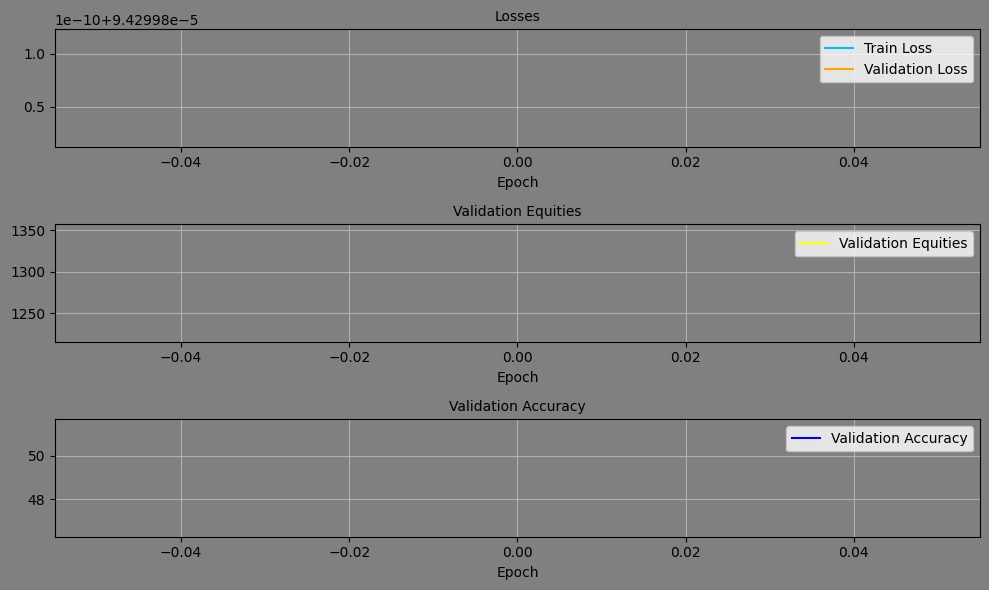

Epoch: 1, Val Equity: 913.72, Val Accuracy: 50.11 train_losses: 0.00028911877499711677, val_losses: 9.171783312922344e-05, Duration: 0:01:47.630606


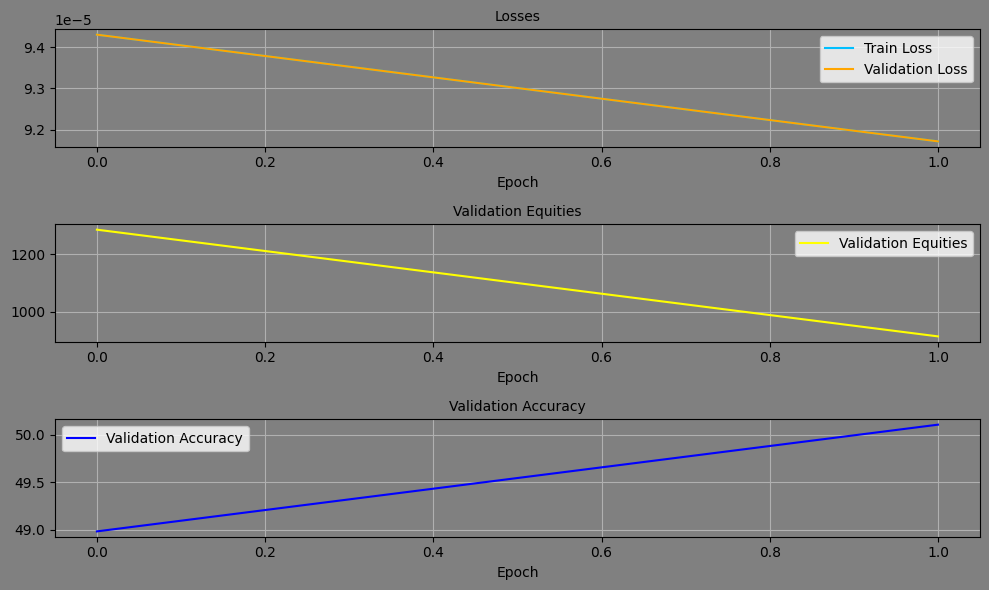

Epoch: 2, Val Equity: 1247.94, Val Accuracy: 50.18 train_losses: 0.0002862846036321098, val_losses: 9.196224709739909e-05, Duration: 0:01:49.590069


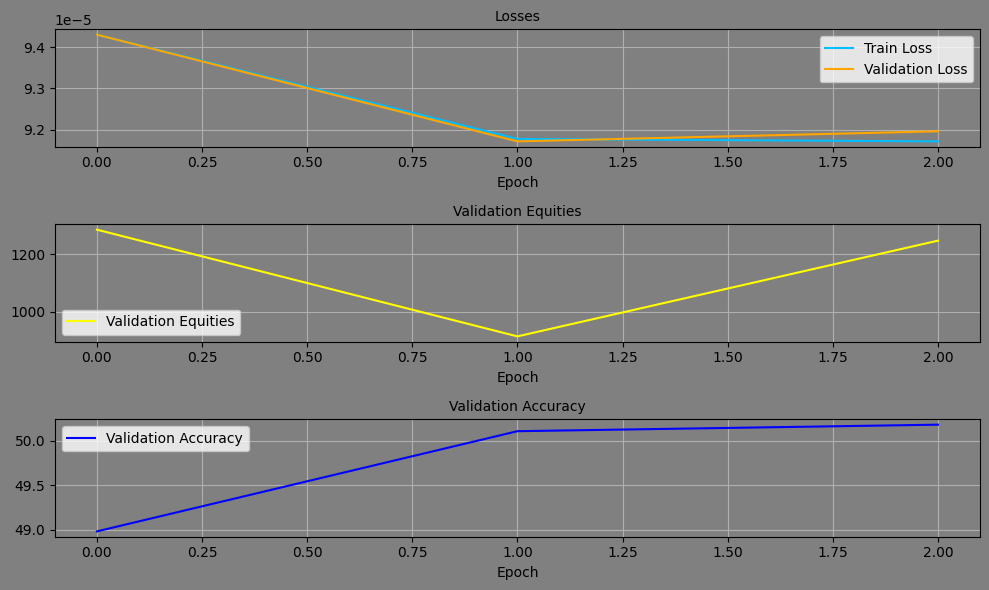

Epoch: 3, Val Equity: 1412.19, Val Accuracy: 49.02 train_losses: 0.0002849825265654981, val_losses: 9.229280112776905e-05, Duration: 0:01:46.795926


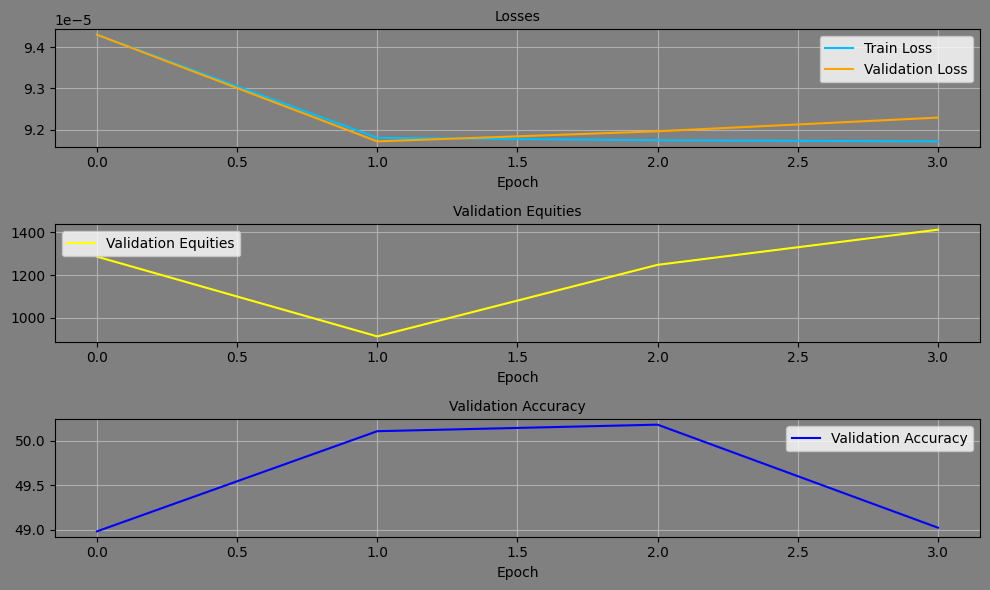

Epoch: 4, Val Equity: 1262.43, Val Accuracy: 50.29 train_losses: 0.0002838890596336103, val_losses: 8.98165671969764e-05, Duration: 0:01:47.760315


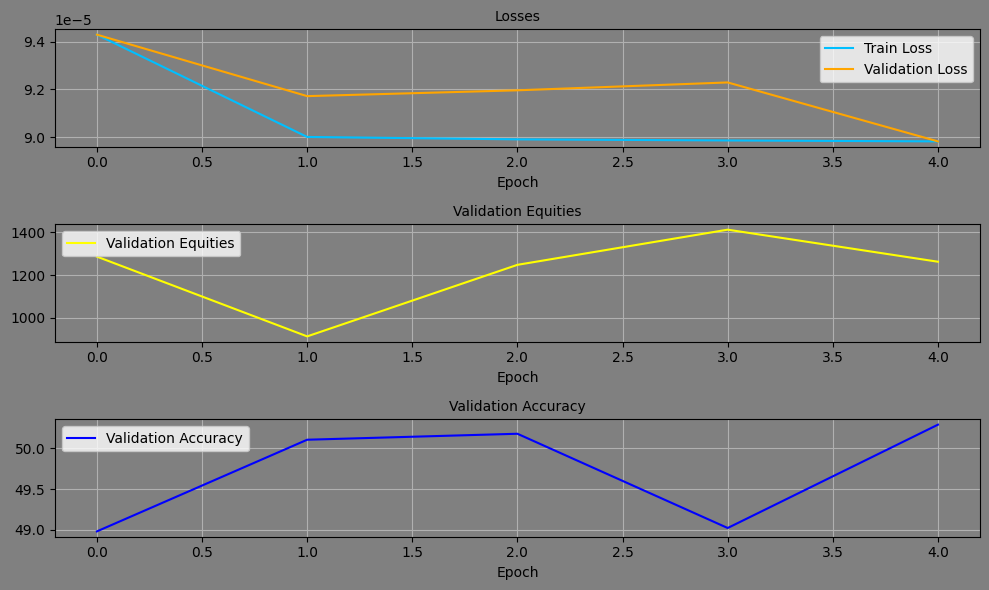

Epoch: 5, Val Equity: 1435.69, Val Accuracy: 49.02 train_losses: 0.0002831367834316064, val_losses: 9.034993854584172e-05, Duration: 0:01:46.882503


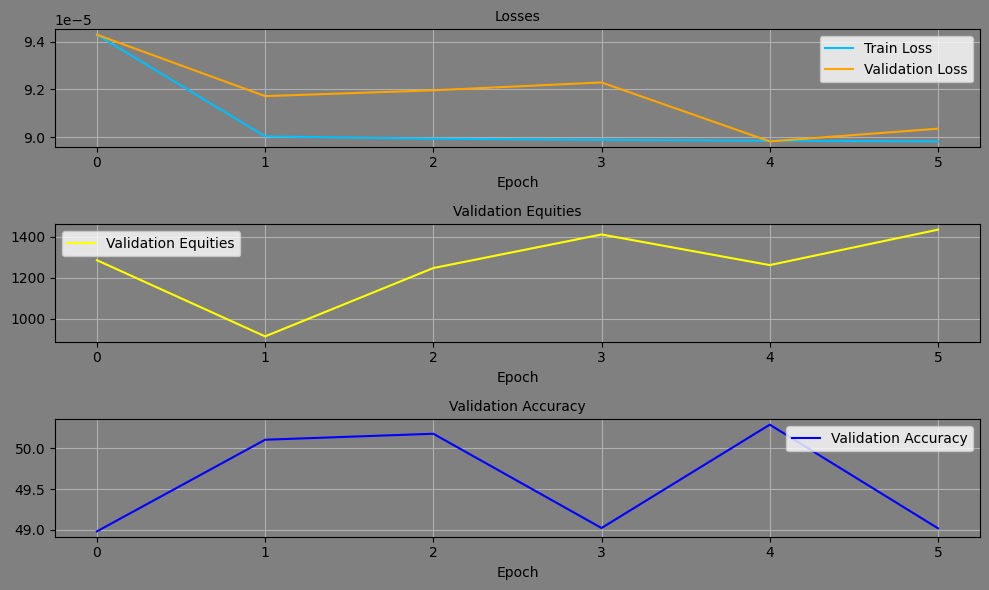

Epoch: 6, Val Equity: 1556.95, Val Accuracy: 49.05 train_losses: 0.0002828835369412194, val_losses: 8.980894199339673e-05, Duration: 0:01:47.718256


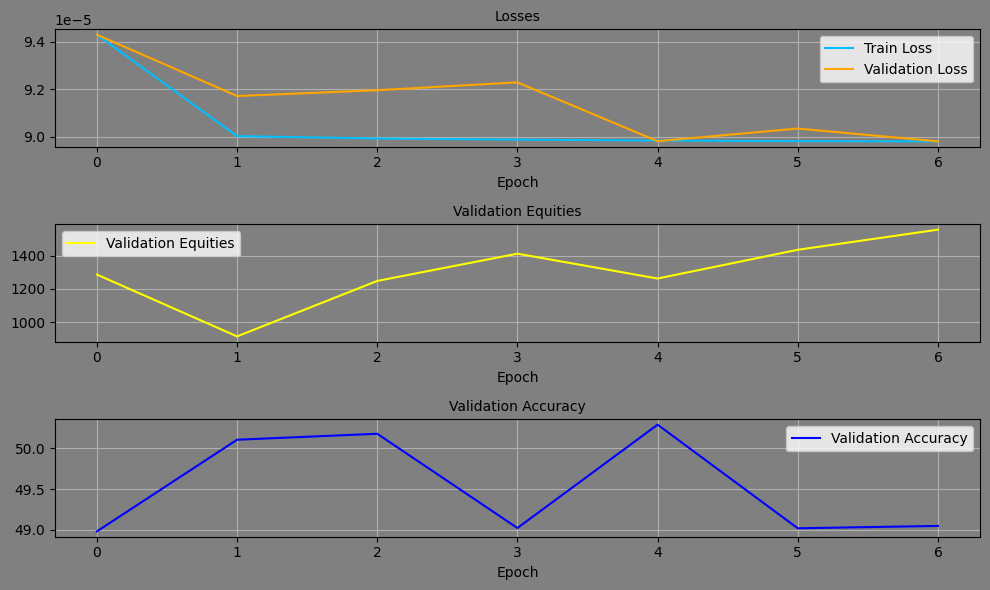

Epoch: 7, Val Equity: 1247.18, Val Accuracy: 50.39 train_losses: 0.0002824128011651944, val_losses: 8.974524826044217e-05, Duration: 0:01:48.949645


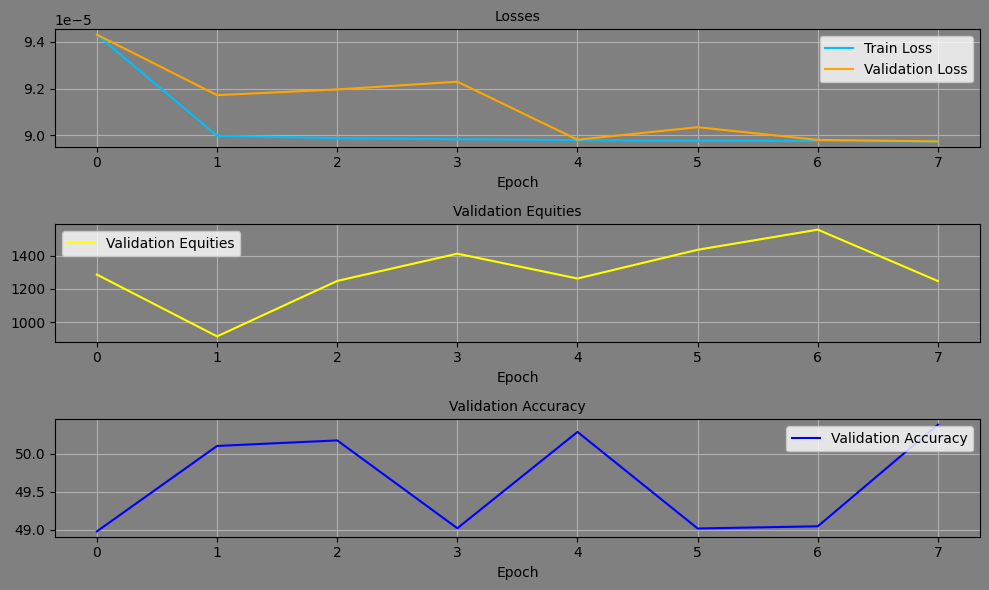

Epoch: 8, Val Equity: 2088.37, Val Accuracy: 50.66 train_losses: 0.00028206924345547705, val_losses: 9.016305557452142e-05, Duration: 0:01:47.345042


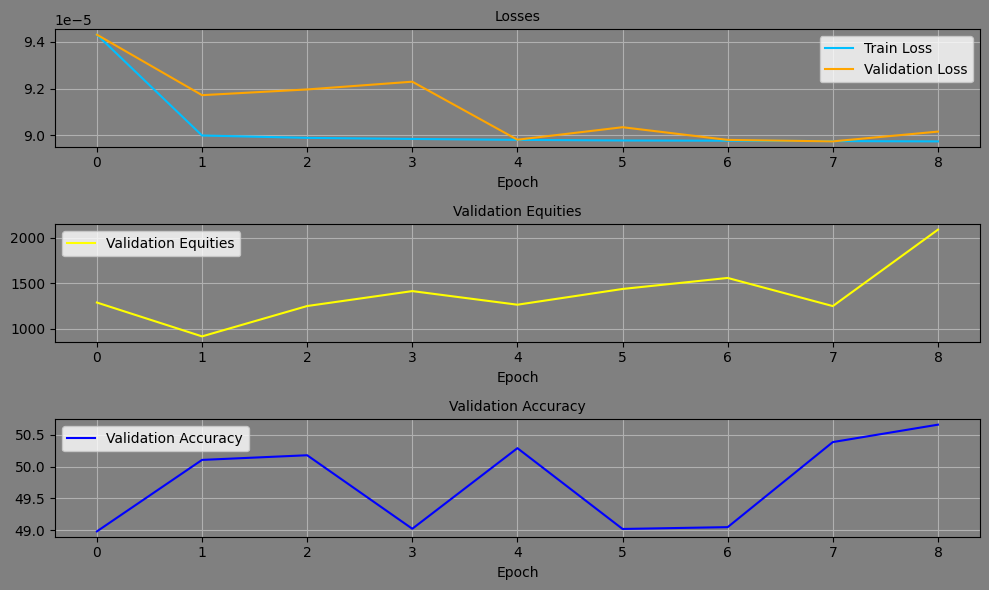

Epoch: 9, Val Equity: 834.53, Val Accuracy: 50.12 train_losses: 0.00028186957415786814, val_losses: 8.959940169006586e-05, Duration: 0:01:47.577471


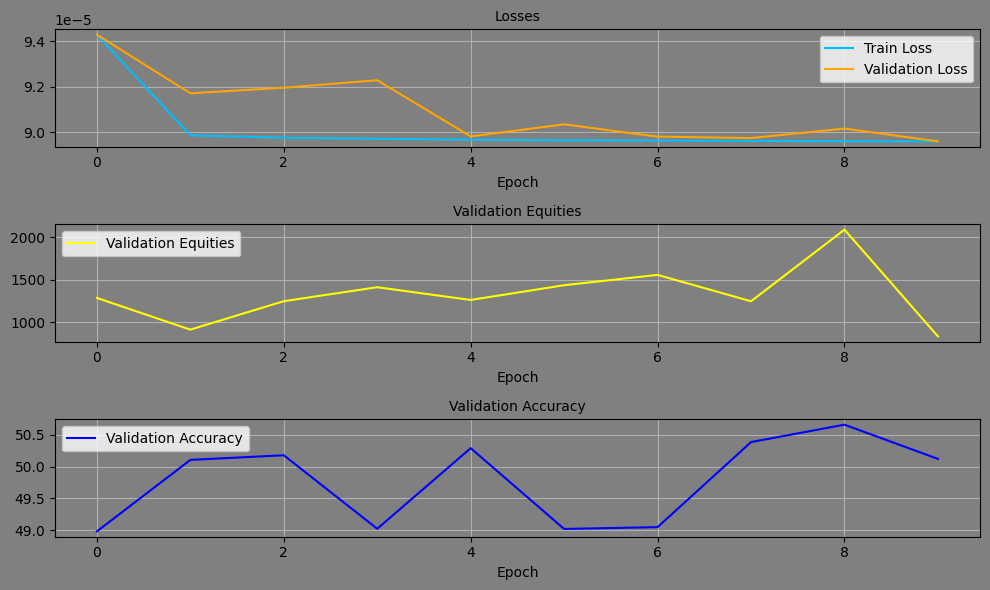

Epoch: 10, Val Equity: 978.94, Val Accuracy: 48.95 train_losses: 0.00028176078773536737, val_losses: 8.930435433285311e-05, Duration: 0:01:48.376180


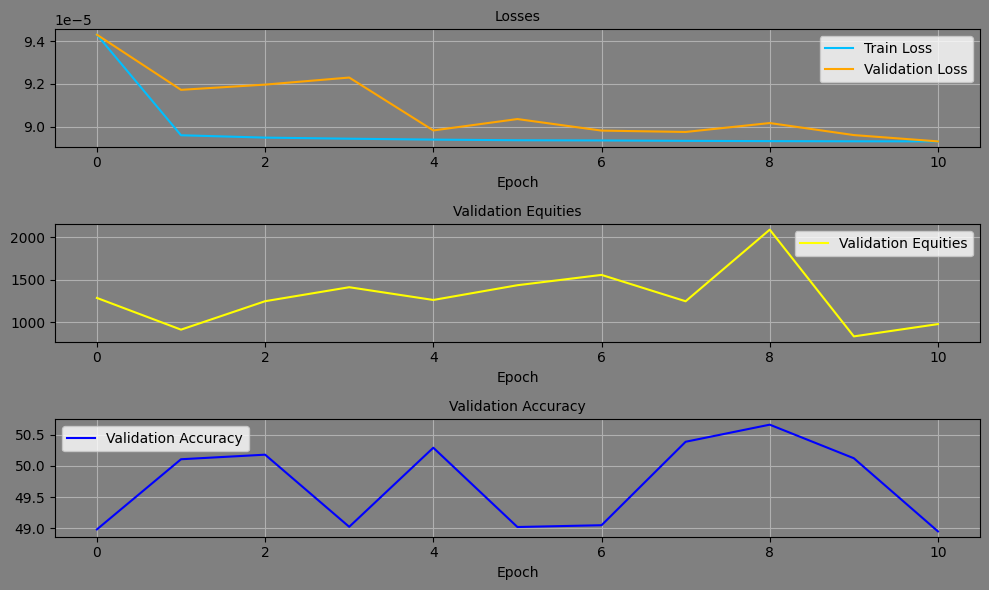

Epoch: 11, Val Equity: 1670.45, Val Accuracy: 48.86 train_losses: 0.00028146392478641625, val_losses: 8.963291475083679e-05, Duration: 0:01:47.761441


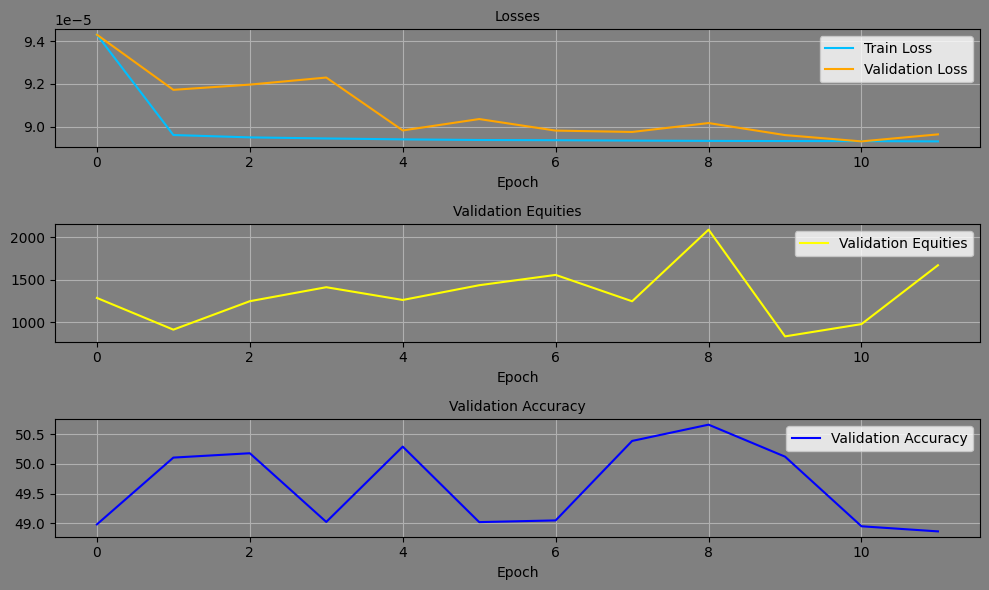

Epoch: 12, Val Equity: 632.46, Val Accuracy: 49.90 train_losses: 0.0002813140822156602, val_losses: 8.987200999399647e-05, Duration: 0:01:48.075223


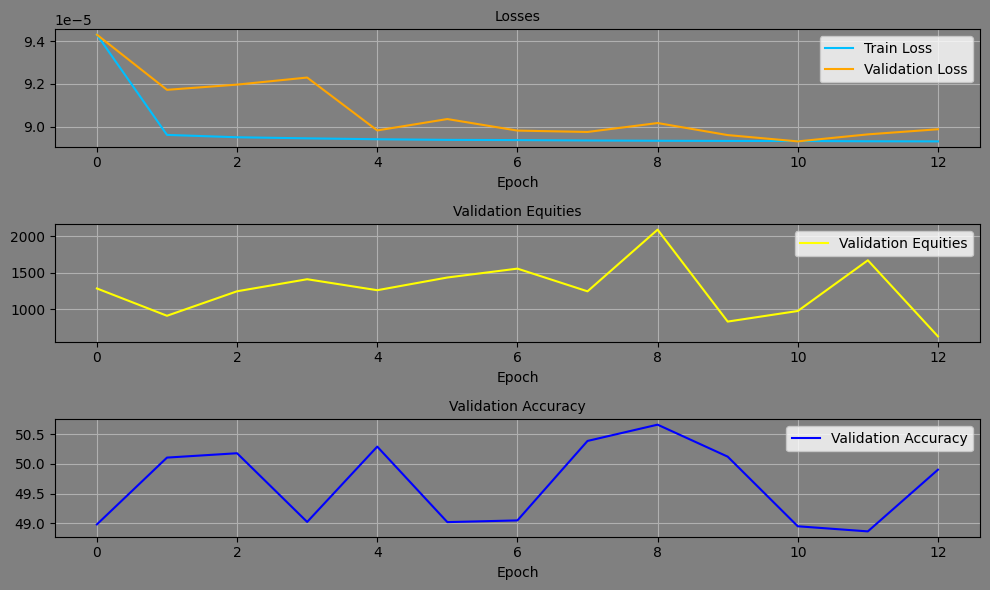

Epoch: 13, Val Equity: 643.22, Val Accuracy: 50.09 train_losses: 0.00028117277528595446, val_losses: 9.395607776241377e-05, Duration: 0:01:47.419410


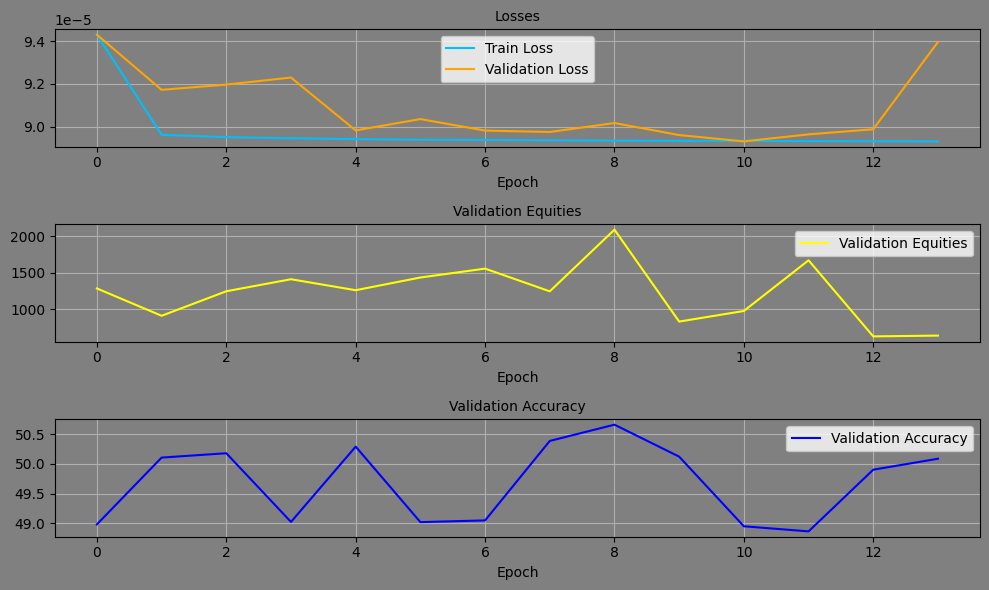

Epoch: 14, Val Equity: 676.16, Val Accuracy: 49.16 train_losses: 0.0002812173235098249, val_losses: 8.962889114627615e-05, Duration: 0:01:47.574190


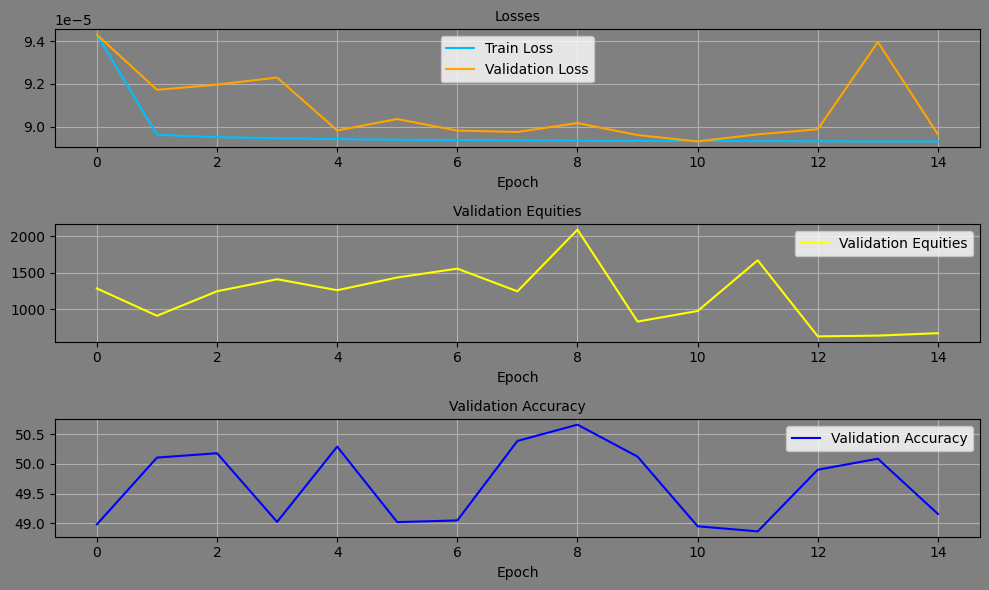

Epoch: 15, Val Equity: 696.68, Val Accuracy: 50.11 train_losses: 0.00028094922621689175, val_losses: 8.973099465947598e-05, Duration: 0:01:48.631370


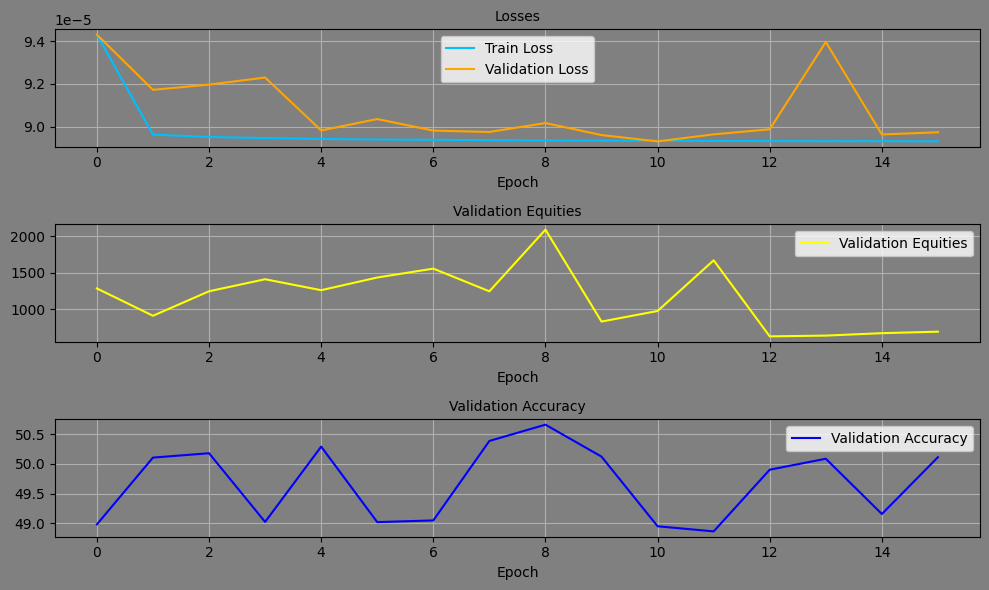

Epoch: 16, Val Equity: 1919.67, Val Accuracy: 49.06 train_losses: 0.00028072334872955416, val_losses: 9.282448445446789e-05, Duration: 0:01:47.949515


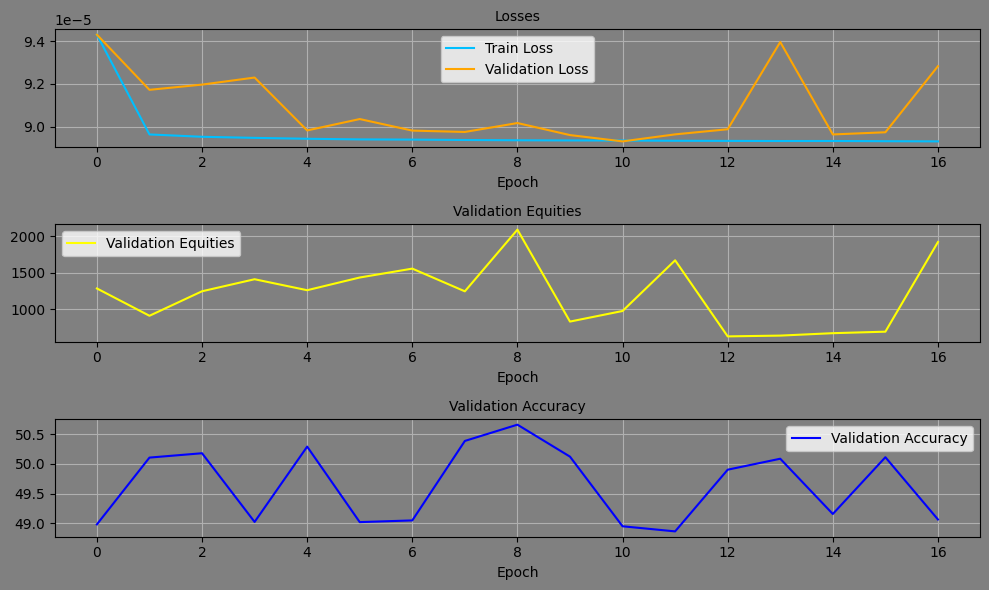

Epoch: 17, Val Equity: 1106.26, Val Accuracy: 50.11 train_losses: 0.0002806133844249941, val_losses: 9.056869021151215e-05, Duration: 0:01:48.859483


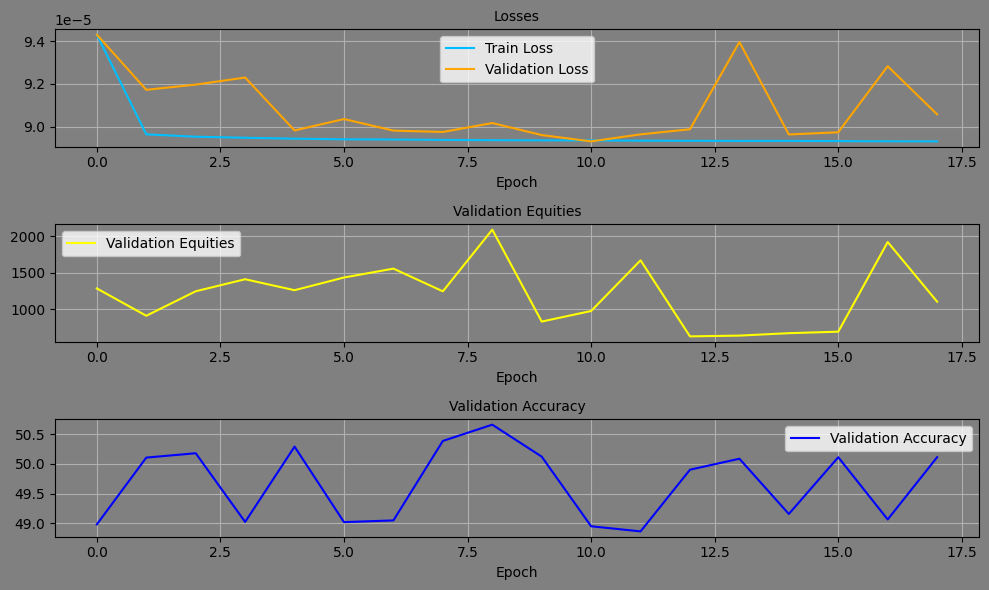

Epoch: 18, Val Equity: 1764.44, Val Accuracy: 48.73 train_losses: 0.0002804698071469563, val_losses: 9.065002086572349e-05, Duration: 0:01:49.502301


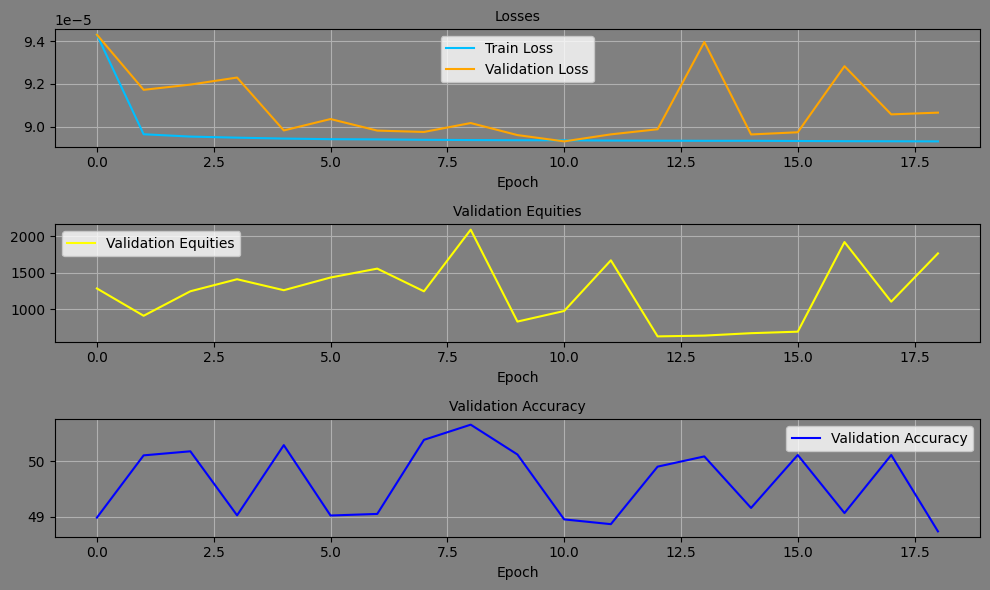

Epoch: 19, Val Equity: 2239.50, Val Accuracy: 49.21 train_losses: 0.0002802716664700896, val_losses: 8.974540105555207e-05, Duration: 0:01:51.242447


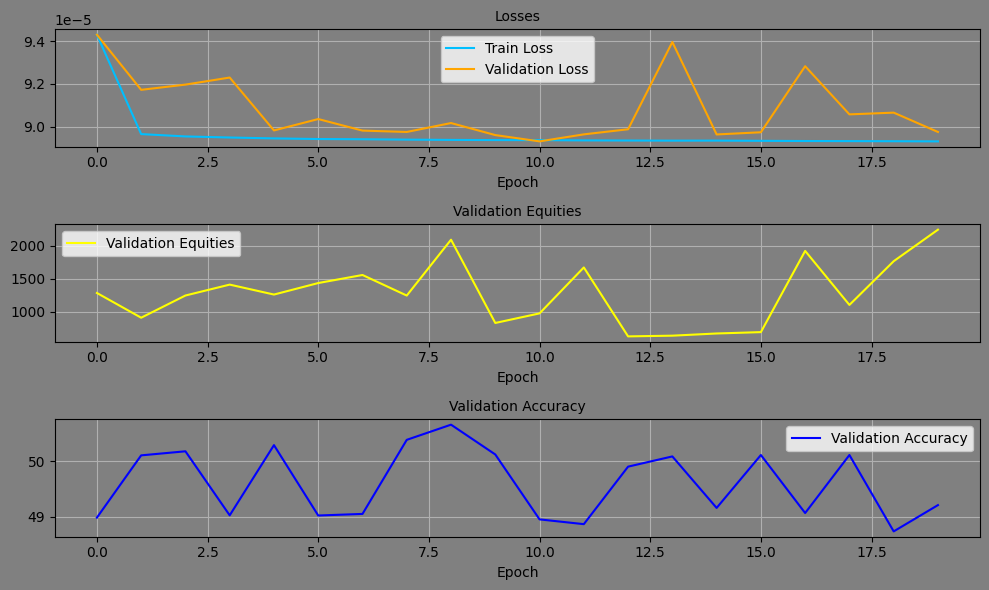

Epoch: 20, Val Equity: 1223.93, Val Accuracy: 48.98 train_losses: 0.00028022395133436986, val_losses: 8.925991278374568e-05, Duration: 0:01:48.624483


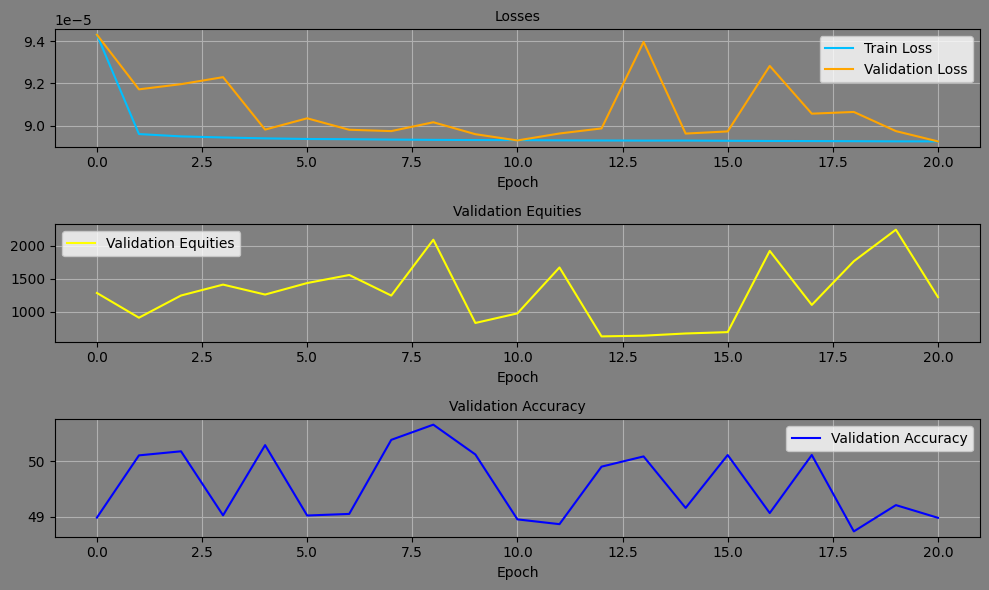

Epoch: 21, Val Equity: 2115.88, Val Accuracy: 49.36 train_losses: 0.0002799806764144934, val_losses: 9.113662235904485e-05, Duration: 0:01:48.085027


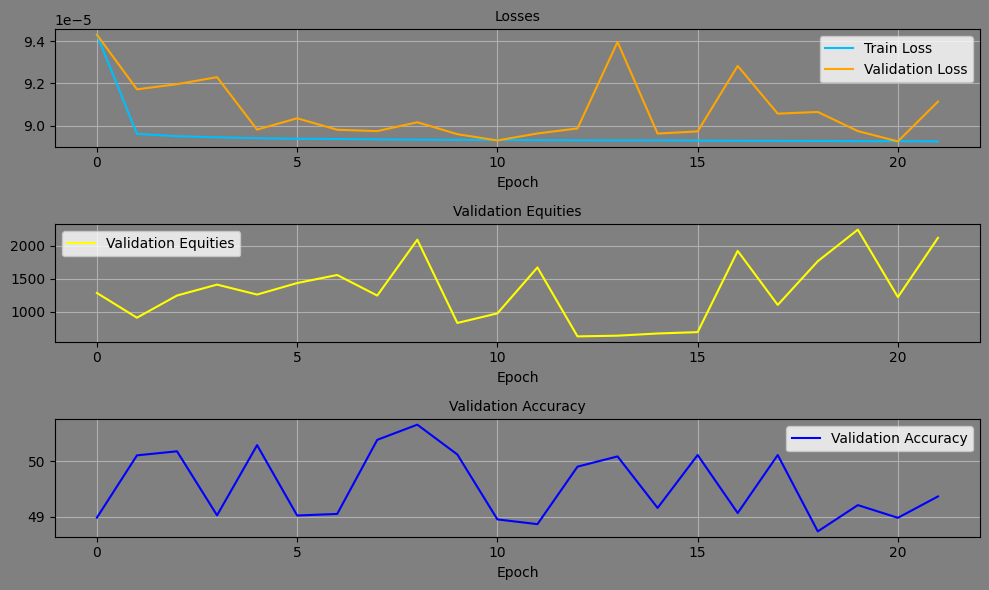

Epoch: 22, Val Equity: 1674.37, Val Accuracy: 49.23 train_losses: 0.0002799184607019333, val_losses: 8.914923819247633e-05, Duration: 0:01:48.307367


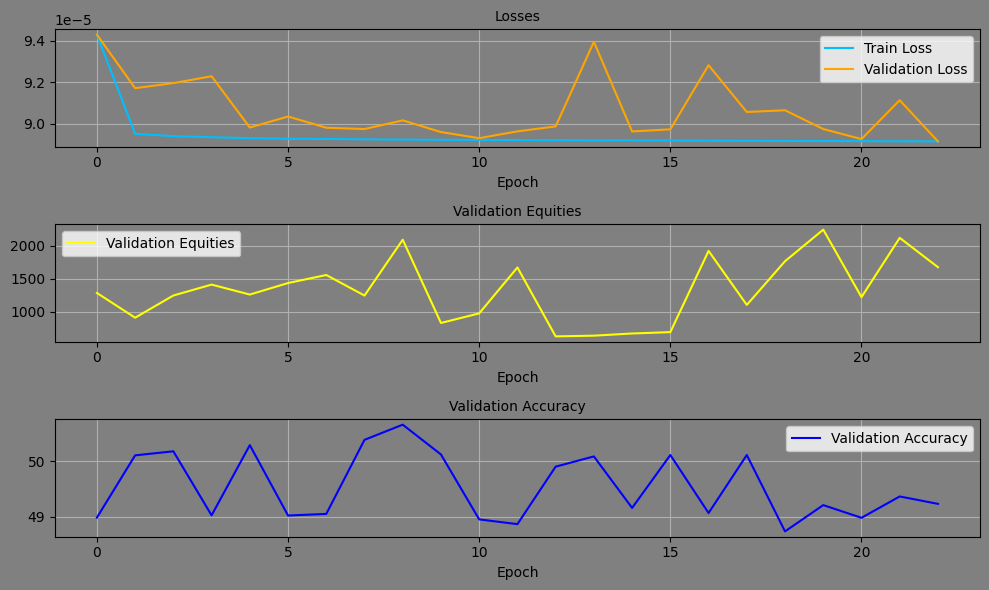

Epoch: 23, Val Equity: 1679.12, Val Accuracy: 50.24 train_losses: 0.0002797328776351583, val_losses: 8.939428516896442e-05, Duration: 0:01:48.857461


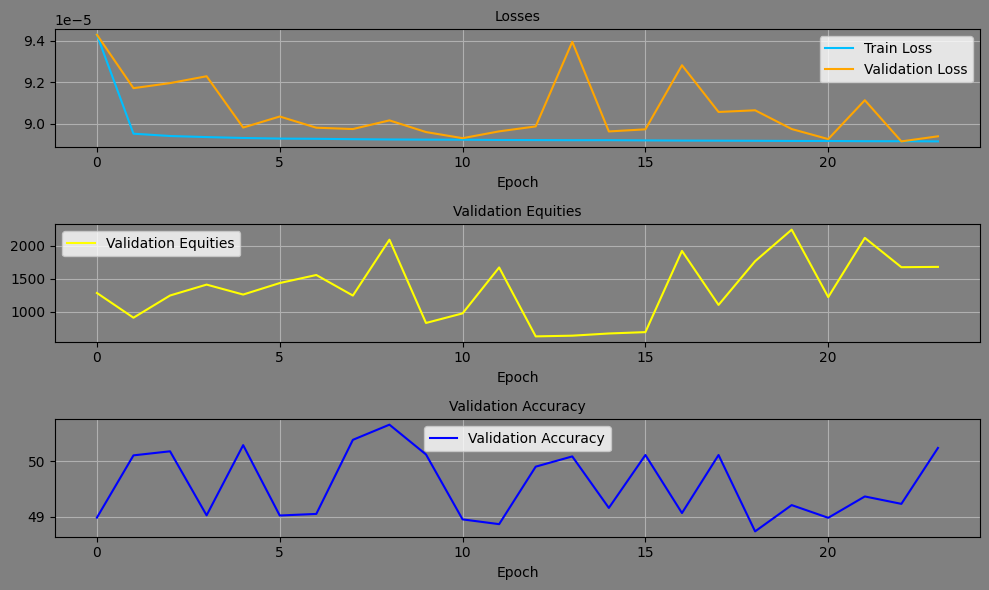

Epoch: 24, Val Equity: 498.45, Val Accuracy: 49.41 train_losses: 0.00027949819911824987, val_losses: 8.929886826081201e-05, Duration: 0:01:51.016521


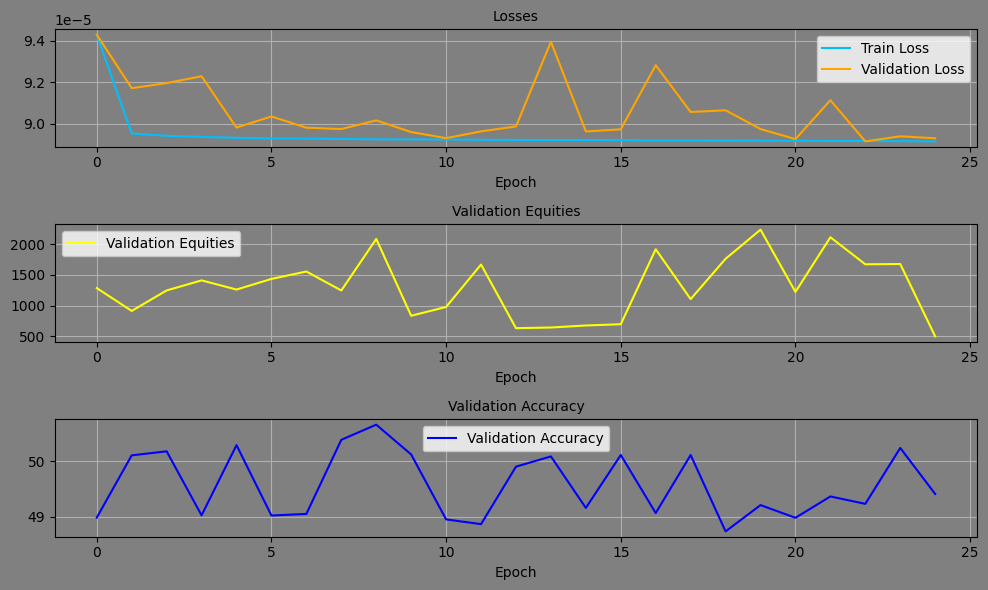

Epoch: 25, Val Equity: 1783.80, Val Accuracy: 48.85 train_losses: 0.00027925542760276657, val_losses: 8.93032192834653e-05, Duration: 0:01:48.930151


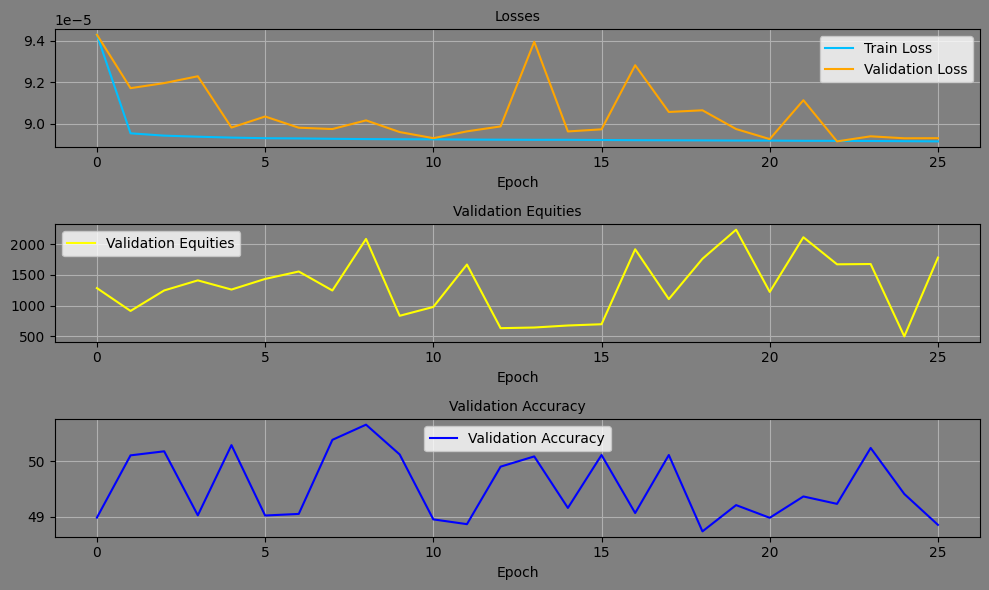

Epoch: 26, Val Equity: 1862.36, Val Accuracy: 49.03 train_losses: 0.0002790254909162589, val_losses: 9.029806824401021e-05, Duration: 0:01:50.453596


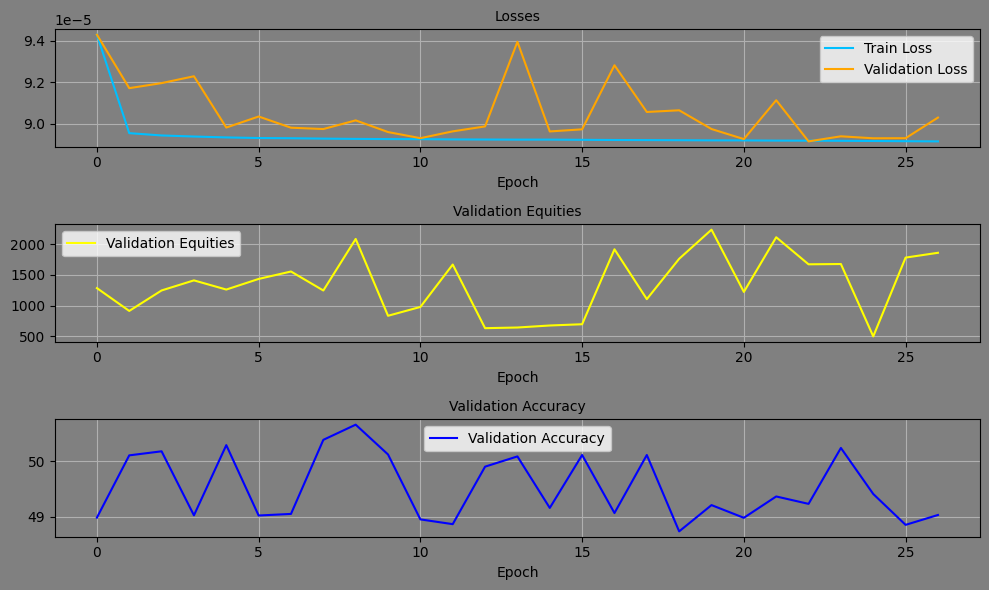

Epoch: 27, Val Equity: 2236.57, Val Accuracy: 49.23 train_losses: 0.0002784036434939377, val_losses: 9.512914402876049e-05, Duration: 0:01:48.743325


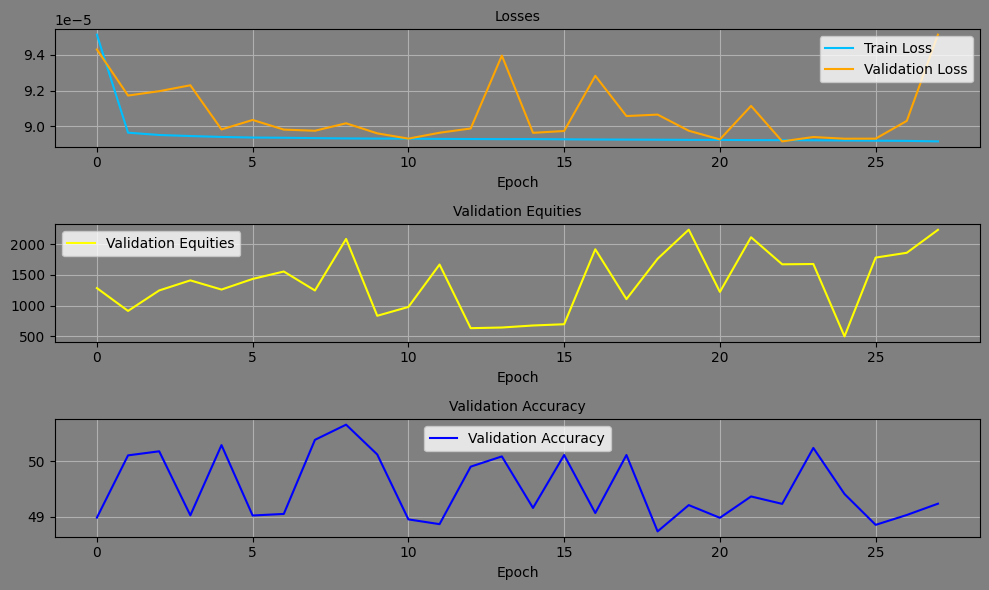

Epoch: 28, Val Equity: 992.13, Val Accuracy: 50.15 train_losses: 0.0002779790460222768, val_losses: 9.173488069791347e-05, Duration: 0:01:47.089528


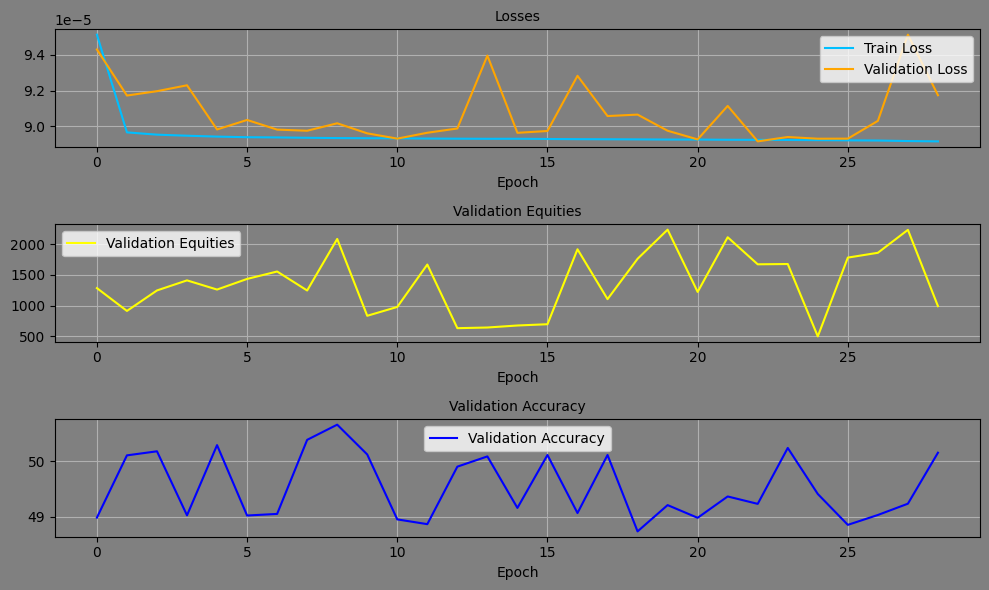

Epoch: 29, Val Equity: 802.10, Val Accuracy: 49.43 train_losses: 0.000278002127311453, val_losses: 8.991618233267218e-05, Duration: 0:01:47.936301


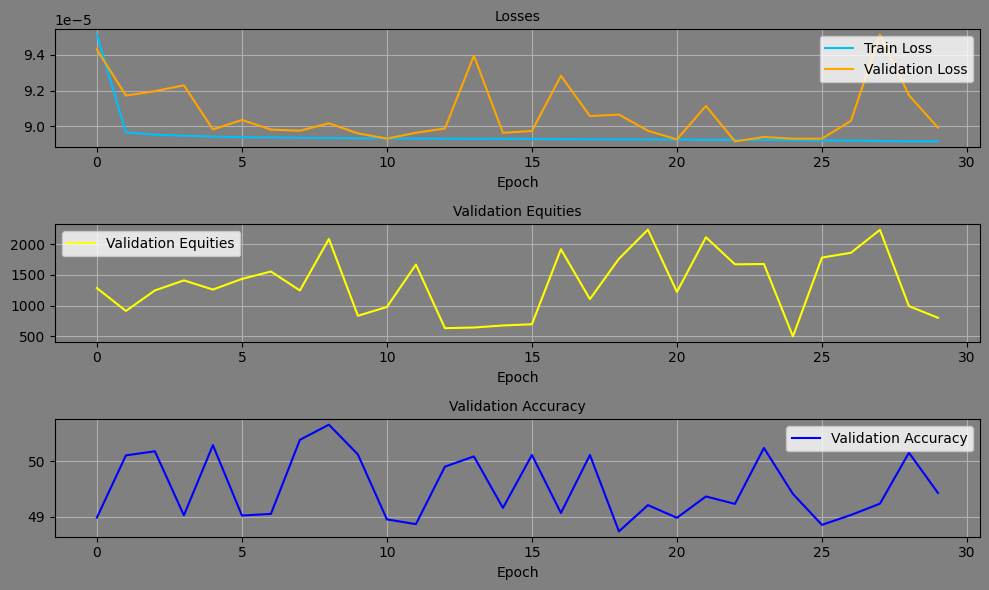

Epoch: 30, Val Equity: 1182.52, Val Accuracy: 50.29 train_losses: 0.0002776585875393004, val_losses: 9.066944039659575e-05, Duration: 0:01:49.510333


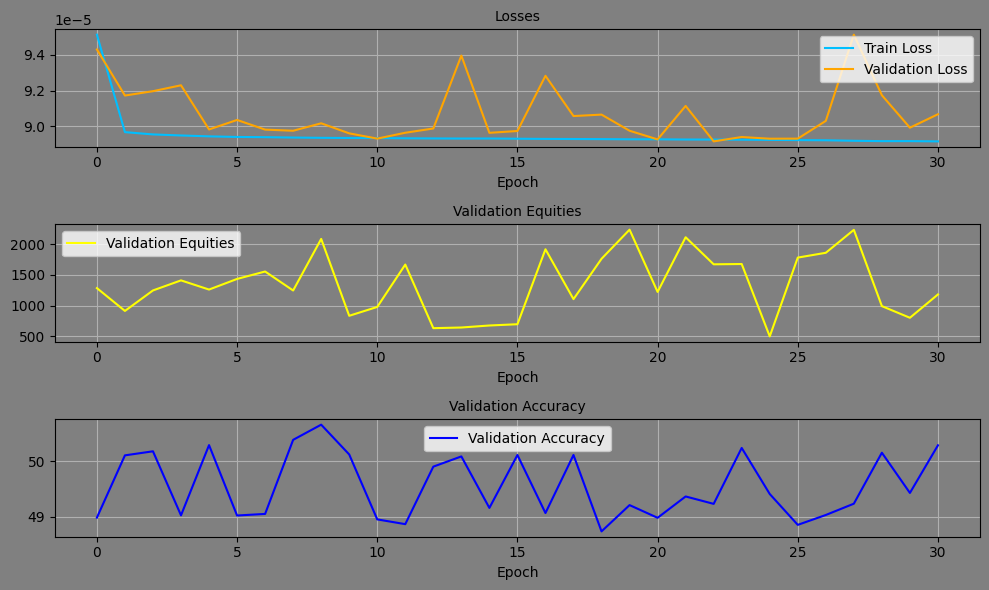

Epoch: 31, Val Equity: 2168.13, Val Accuracy: 48.81 train_losses: 0.00027723718152383004, val_losses: 8.90362643986009e-05, Duration: 0:01:48.178845


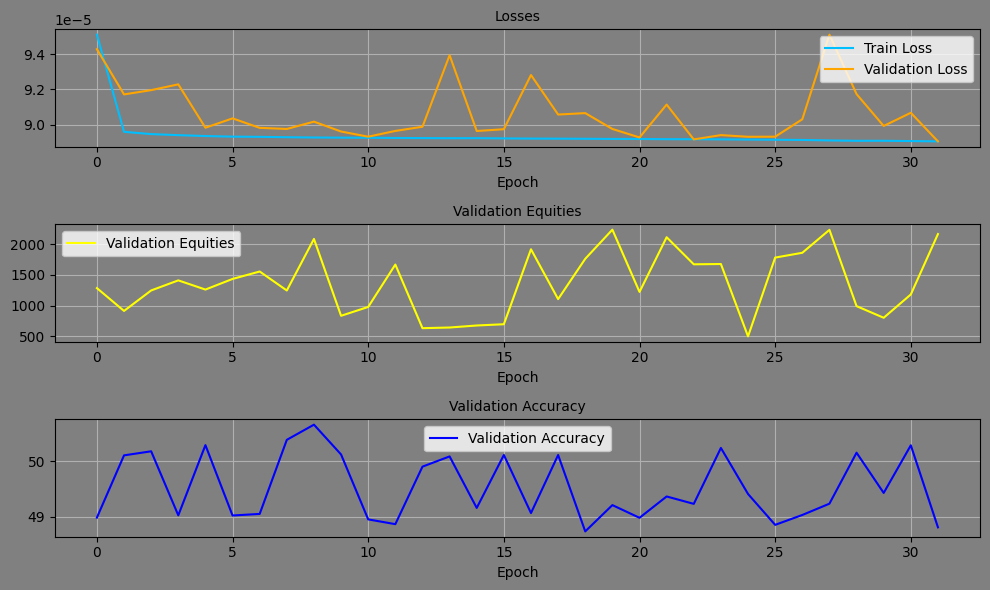

Epoch: 32, Val Equity: 1427.52, Val Accuracy: 50.28 train_losses: 0.0002769498044932423, val_losses: 9.077312279259786e-05, Duration: 0:01:48.842245


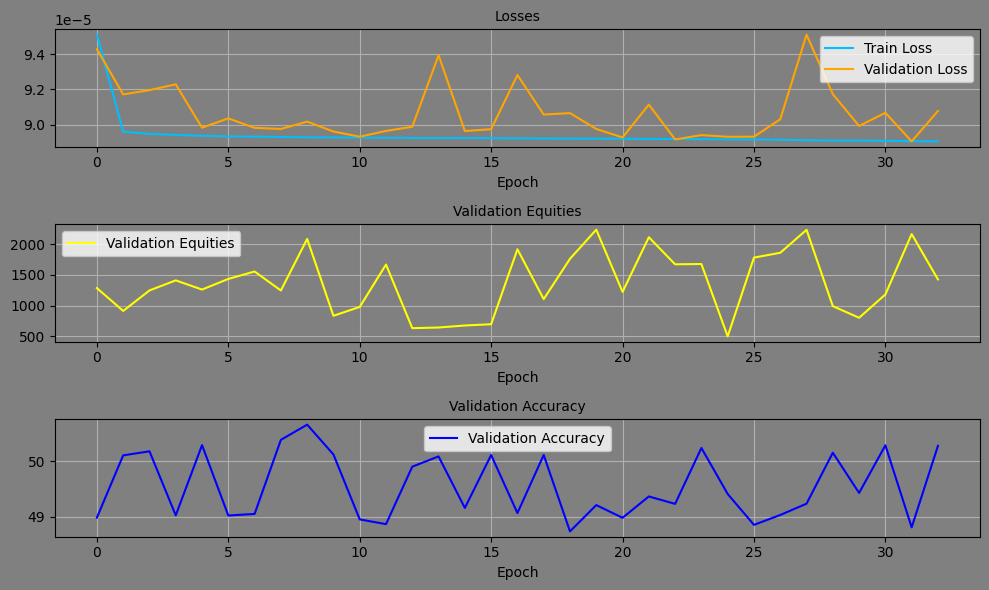

Epoch: 33, Val Equity: 498.68, Val Accuracy: 49.42 train_losses: 0.00027673200394413405, val_losses: 9.250688890460879e-05, Duration: 0:01:48.218910


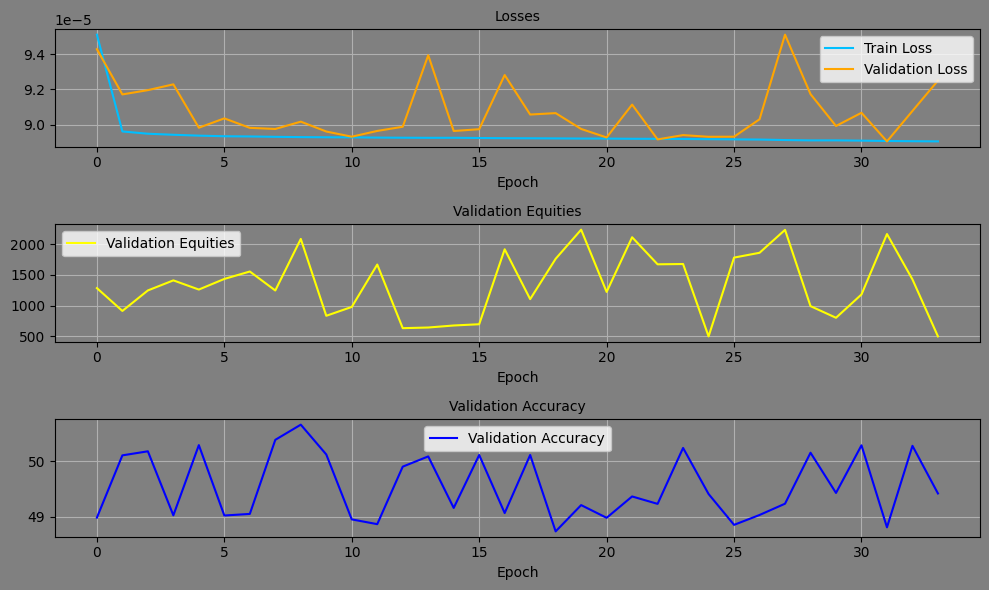

Epoch: 34, Val Equity: 1694.76, Val Accuracy: 48.66 train_losses: 0.00027656399867036886, val_losses: 9.004714229376987e-05, Duration: 0:01:47.860119


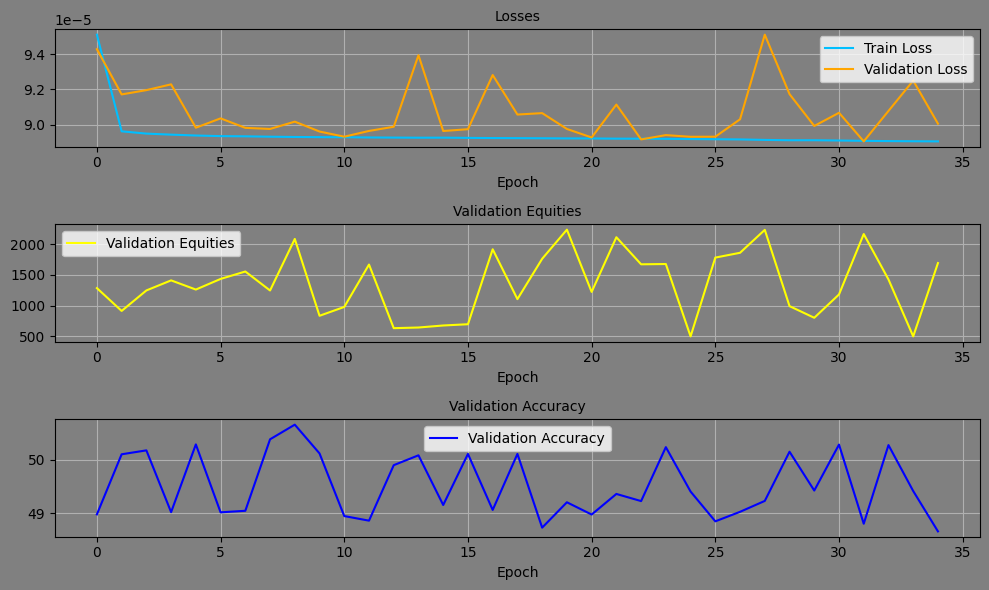

Epoch: 35, Val Equity: 1175.74, Val Accuracy: 50.19 train_losses: 0.0002764062121259966, val_losses: 9.08023866941221e-05, Duration: 0:01:57.458688


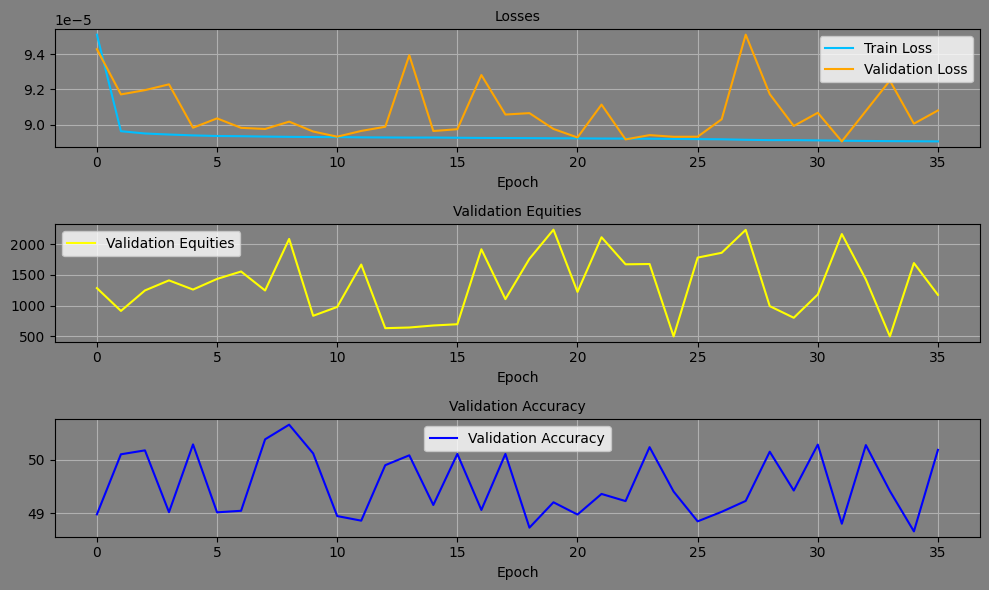

Epoch: 36, Val Equity: 1922.53, Val Accuracy: 49.05 train_losses: 0.0002762486125890781, val_losses: 9.181808127323166e-05, Duration: 0:01:49.174788


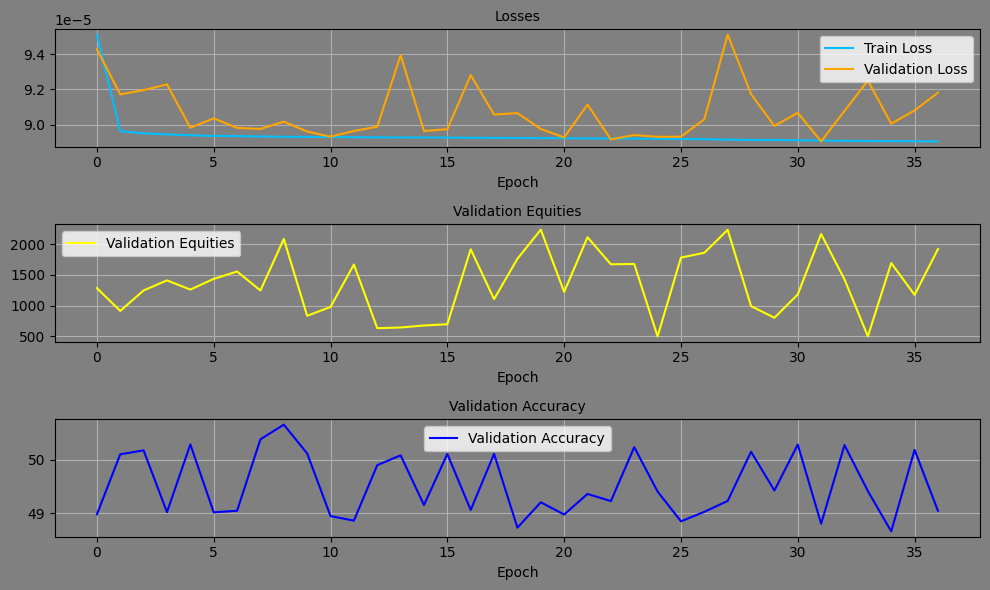

Epoch: 37, Val Equity: 906.51, Val Accuracy: 49.27 train_losses: 0.0002760821834950489, val_losses: 8.937845268519595e-05, Duration: 0:01:48.347609


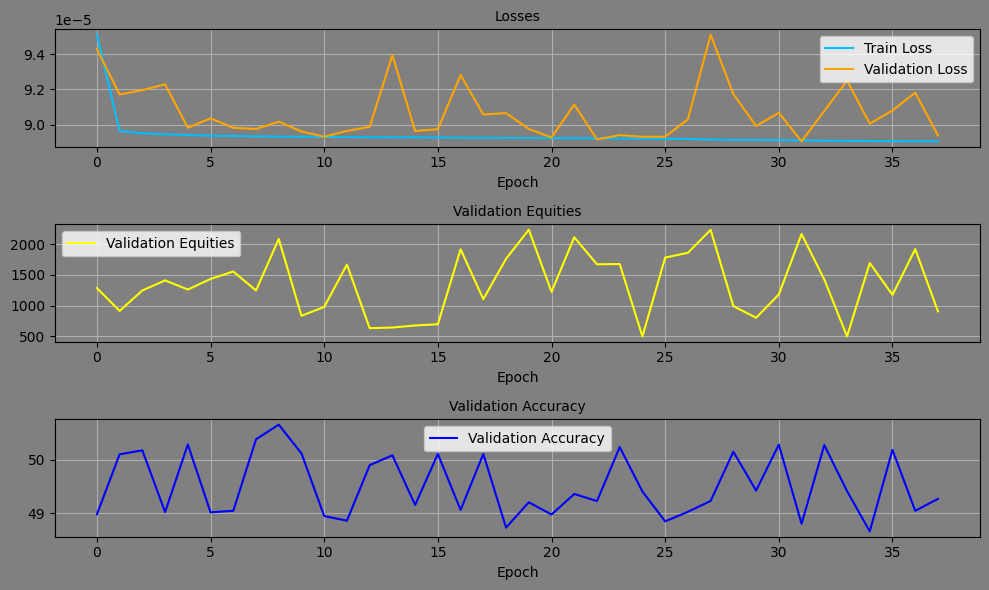

Epoch: 38, Val Equity: 1303.16, Val Accuracy: 48.83 train_losses: 0.0002759157349619568, val_losses: 8.94427575985901e-05, Duration: 0:01:48.056478


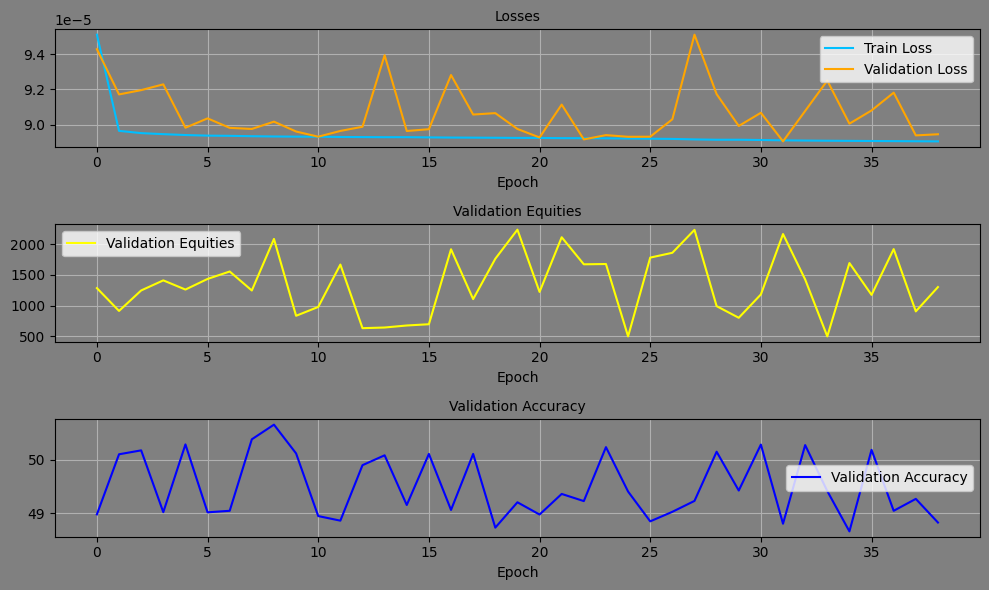

Epoch: 39, Val Equity: 1976.31, Val Accuracy: 49.26 train_losses: 0.0002756922878353269, val_losses: 8.958522084867582e-05, Duration: 0:01:47.772449


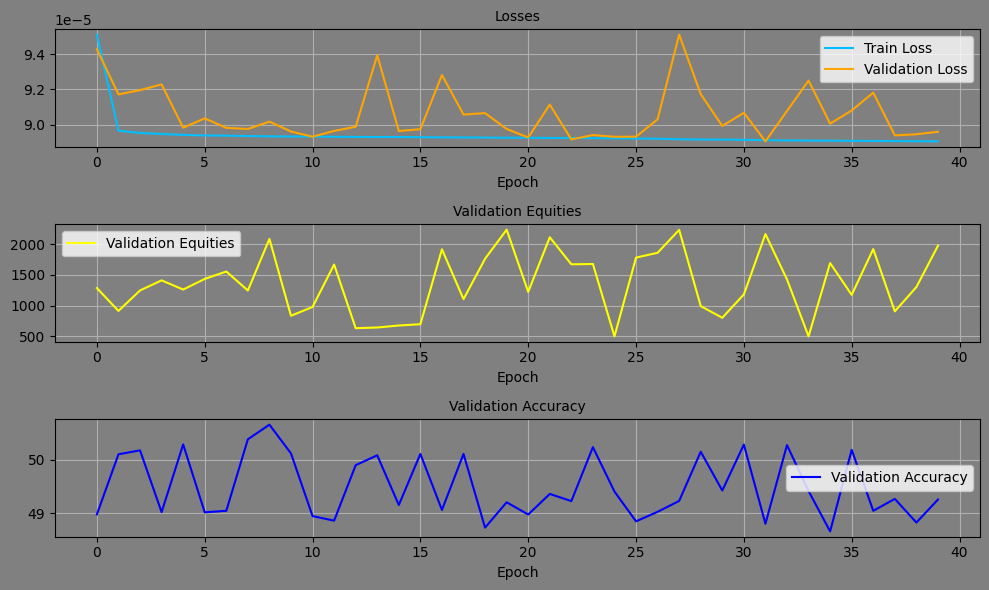

Epoch: 40, Val Equity: 2063.99, Val Accuracy: 48.89 train_losses: 0.00027558879948334677, val_losses: 8.975184755399823e-05, Duration: 0:01:48.445032


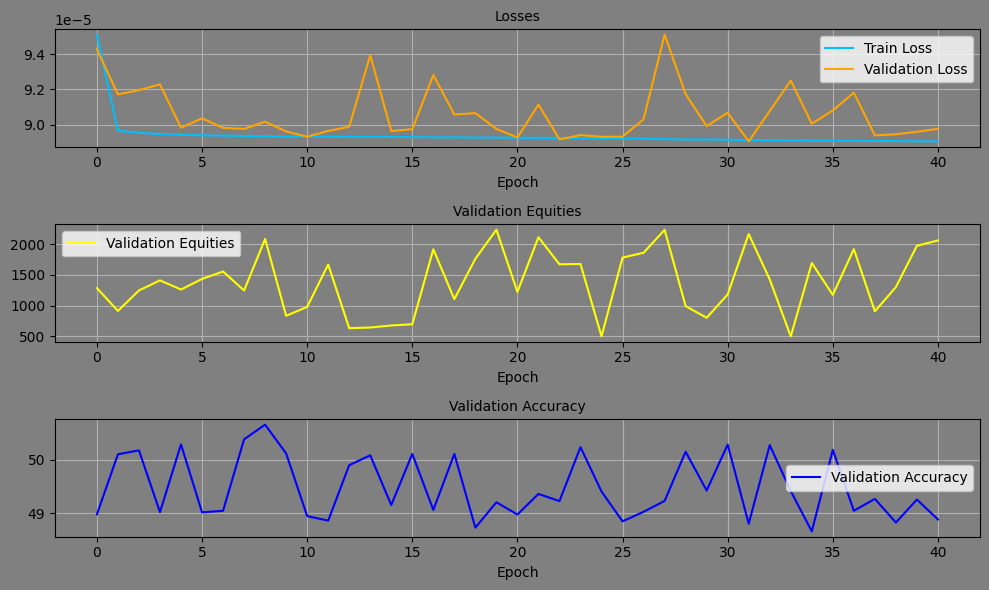

Epoch: 41, Val Equity: 1700.09, Val Accuracy: 49.41 train_losses: 0.0002755551951214159, val_losses: 9.006754407892004e-05, Duration: 0:01:47.397390


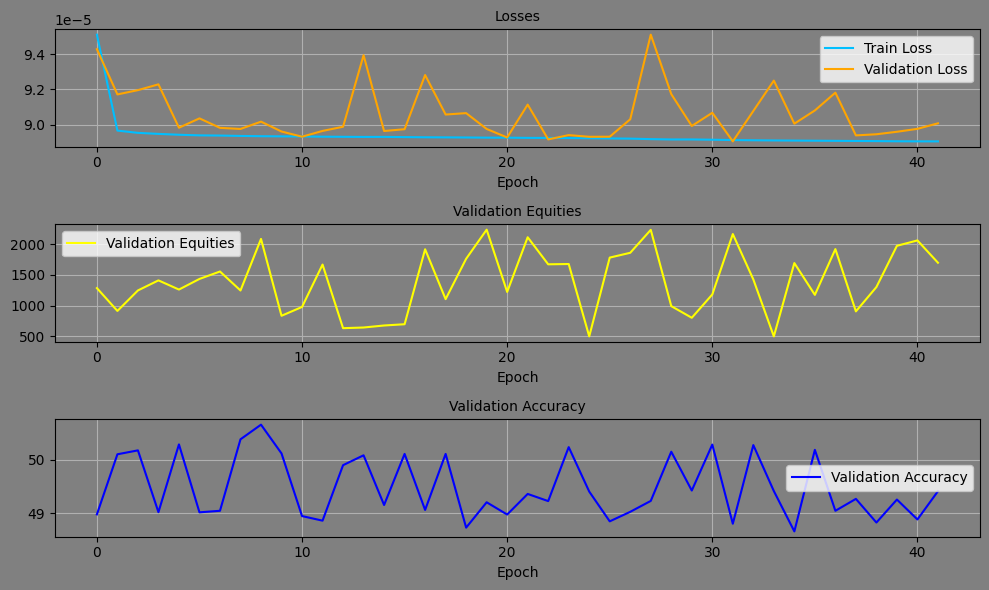

Epoch: 42, Val Equity: 1354.69, Val Accuracy: 48.76 train_losses: 0.00027539541512548266, val_losses: 9.10829912754707e-05, Duration: 0:01:48.597089


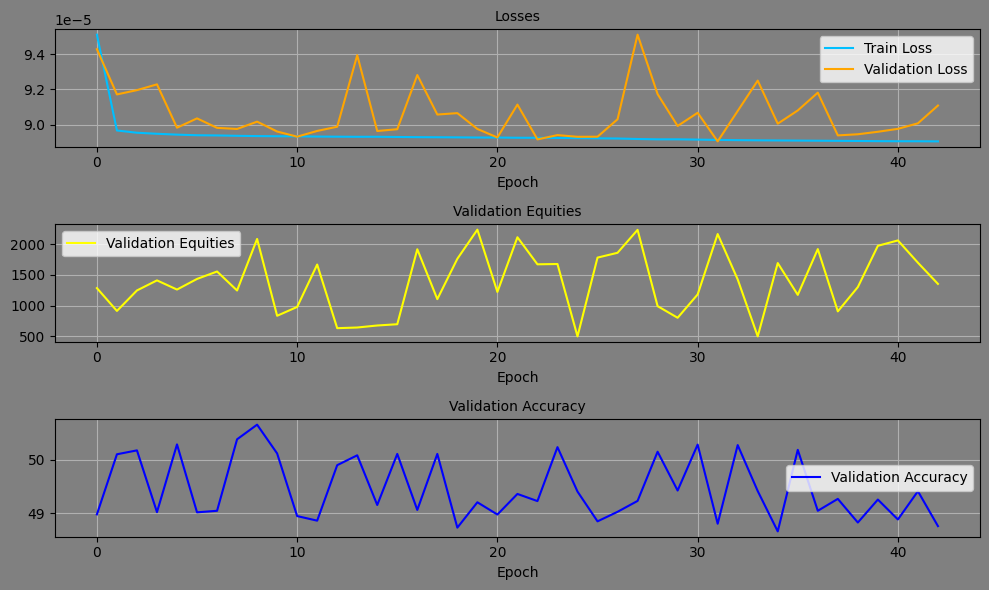

Epoch: 43, Val Equity: 1479.97, Val Accuracy: 49.90 train_losses: 0.0002751073843128546, val_losses: 9.047106868820265e-05, Duration: 0:01:48.130885


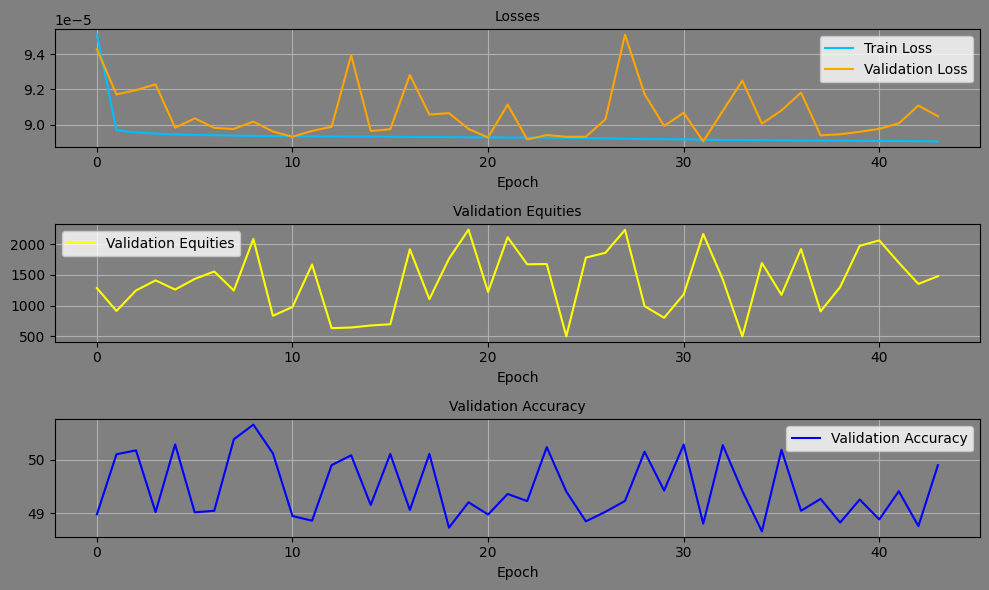

Epoch: 44, Val Equity: 1561.79, Val Accuracy: 49.06 train_losses: 0.0002750275167962291, val_losses: 8.955642260843888e-05, Duration: 0:01:48.415980


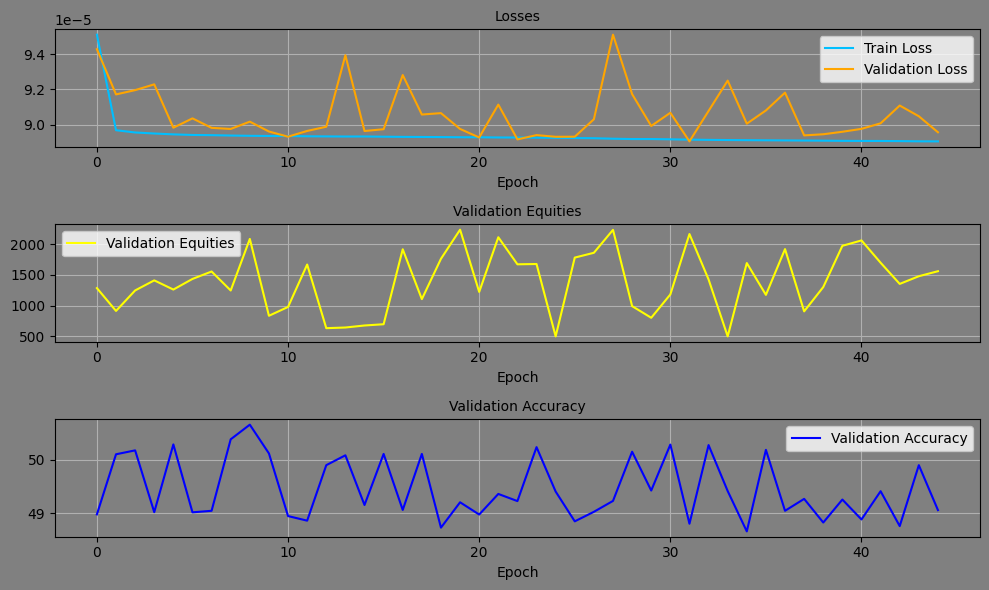

Epoch: 45, Val Equity: 1776.69, Val Accuracy: 50.24 train_losses: 0.0002749334046400254, val_losses: 8.914044155972078e-05, Duration: 0:01:48.371027


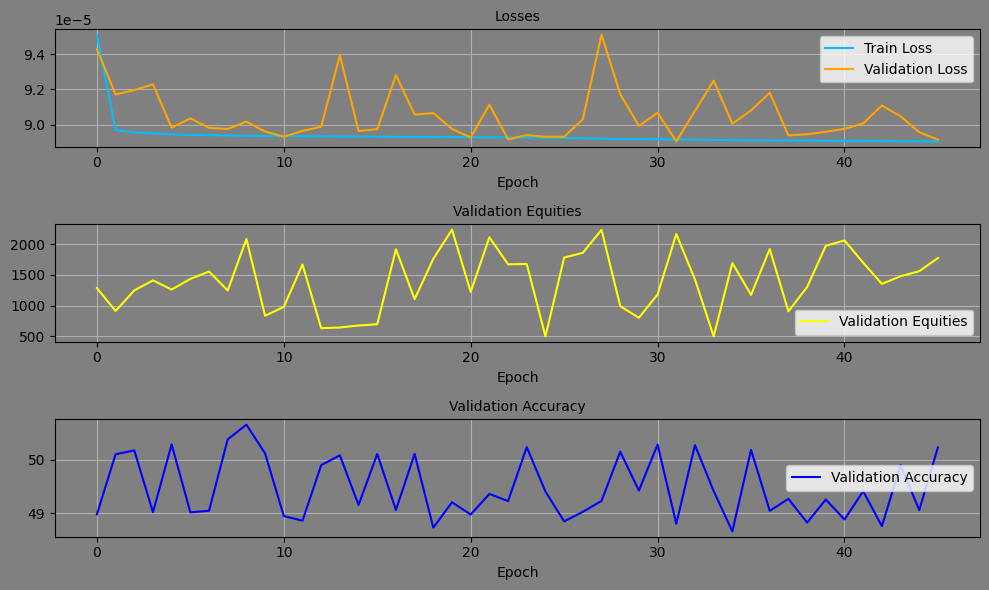

Epoch: 46, Val Equity: 1985.40, Val Accuracy: 50.96 train_losses: 0.00027477695220514813, val_losses: 8.930142939789221e-05, Duration: 0:01:47.894031


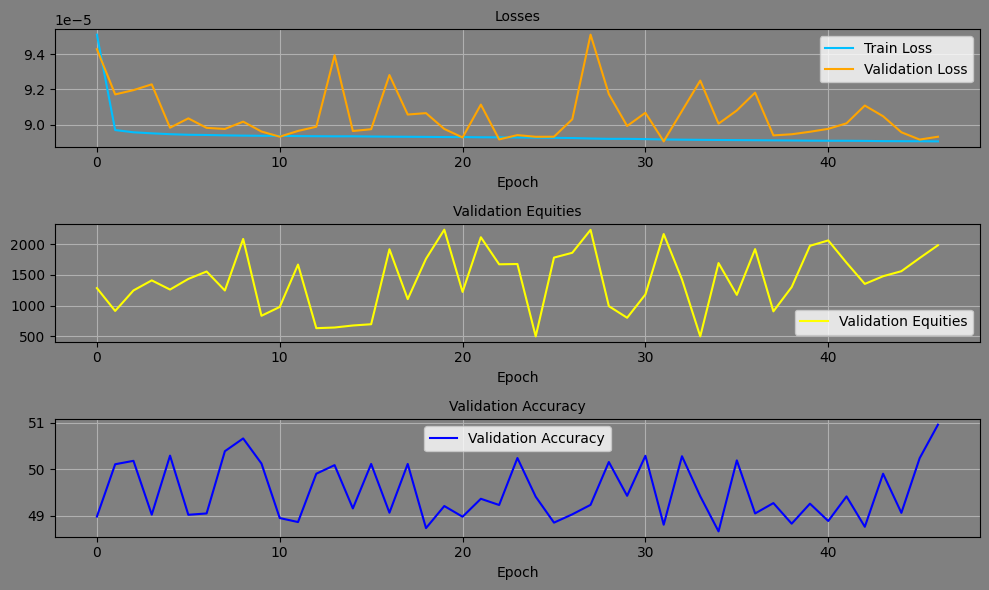

Epoch: 47, Val Equity: 1498.69, Val Accuracy: 50.34 train_losses: 0.0002746374335019271, val_losses: 9.016380499815568e-05, Duration: 0:01:48.079246


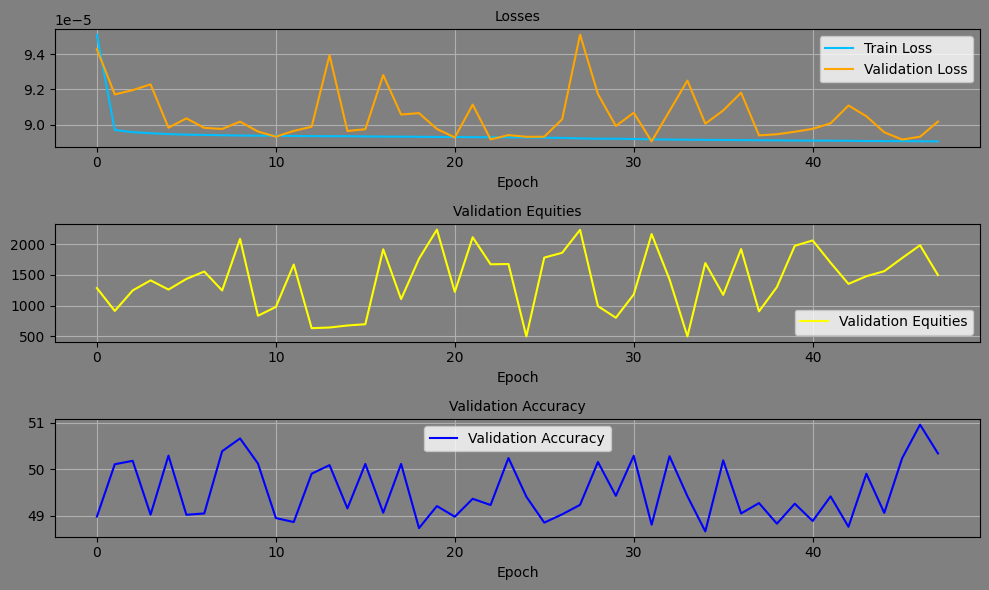

Epoch: 48, Val Equity: 1464.95, Val Accuracy: 48.98 train_losses: 0.0002746243421376779, val_losses: 8.988200715975836e-05, Duration: 0:01:48.138881


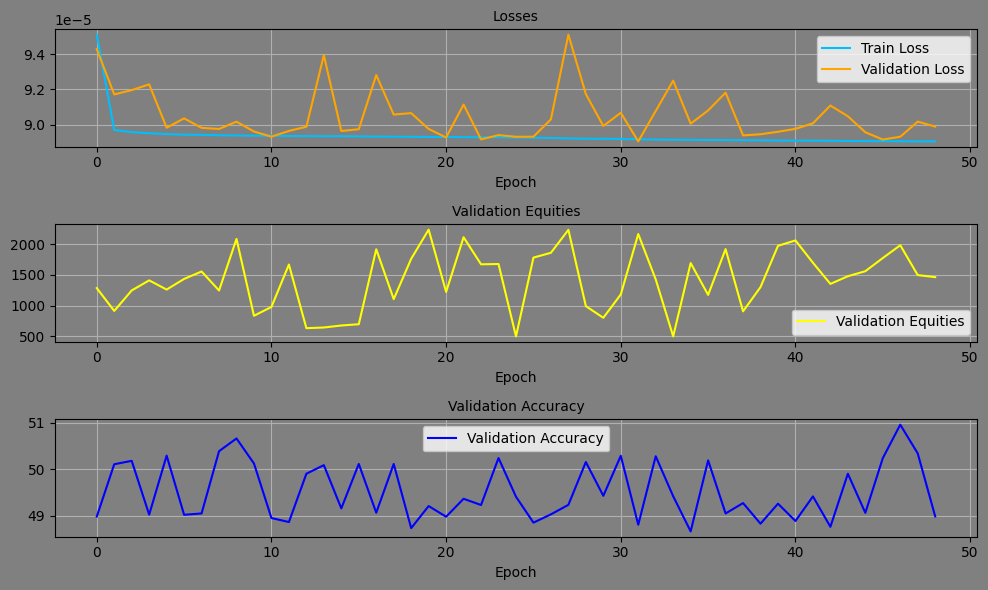

Epoch: 49, Val Equity: 2544.06, Val Accuracy: 50.56 train_losses: 0.00027438756590497616, val_losses: 8.914595673559234e-05, Duration: 0:01:47.914034


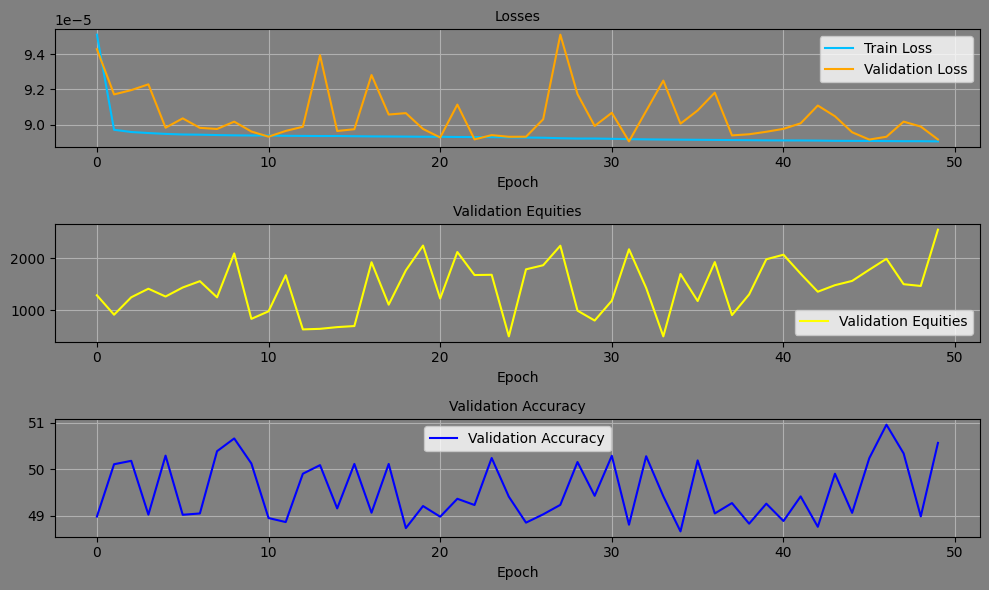

Epoch: 50, Val Equity: 2511.66, Val Accuracy: 51.38 train_losses: 0.00027430331741060197, val_losses: 8.953379438025877e-05, Duration: 0:01:47.665481


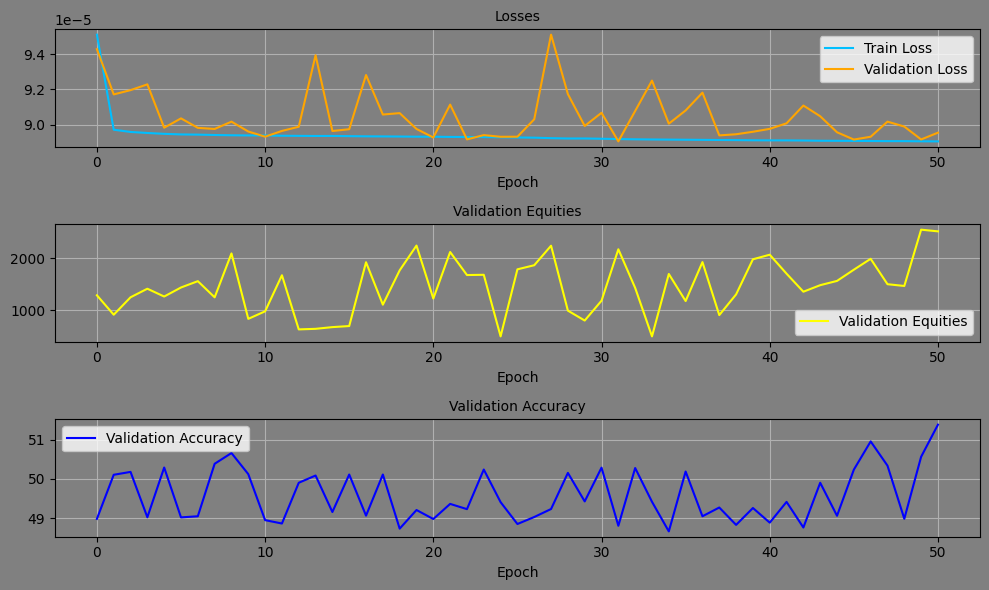

Epoch: 51, Val Equity: 1143.87, Val Accuracy: 50.00 train_losses: 0.00027412659787851376, val_losses: 8.982406870927662e-05, Duration: 0:01:47.956352


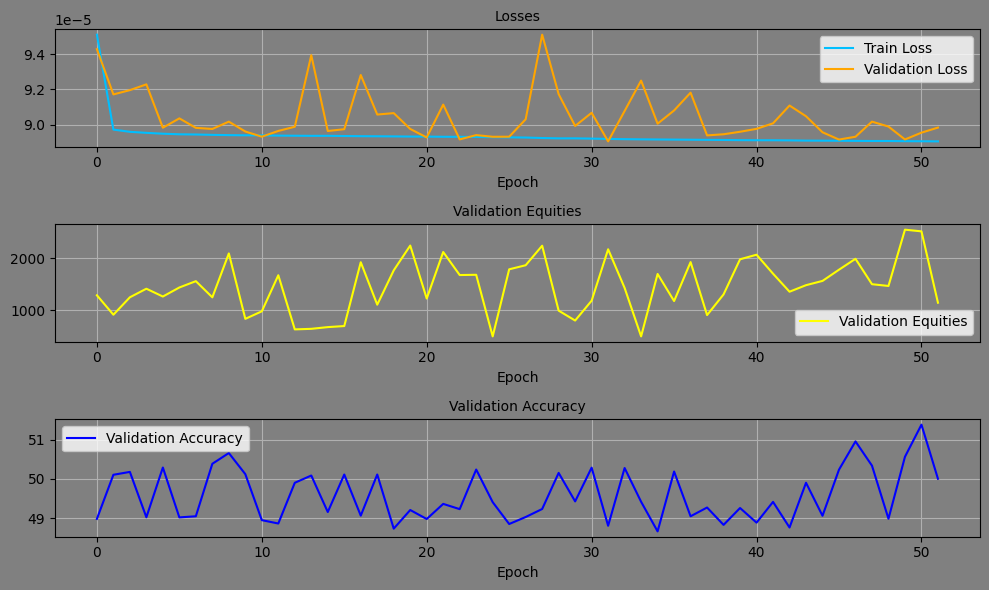

Epoch: 52, Val Equity: 1369.51, Val Accuracy: 50.19 train_losses: 0.00027395522105520495, val_losses: 8.927201270125806e-05, Duration: 0:01:48.571397


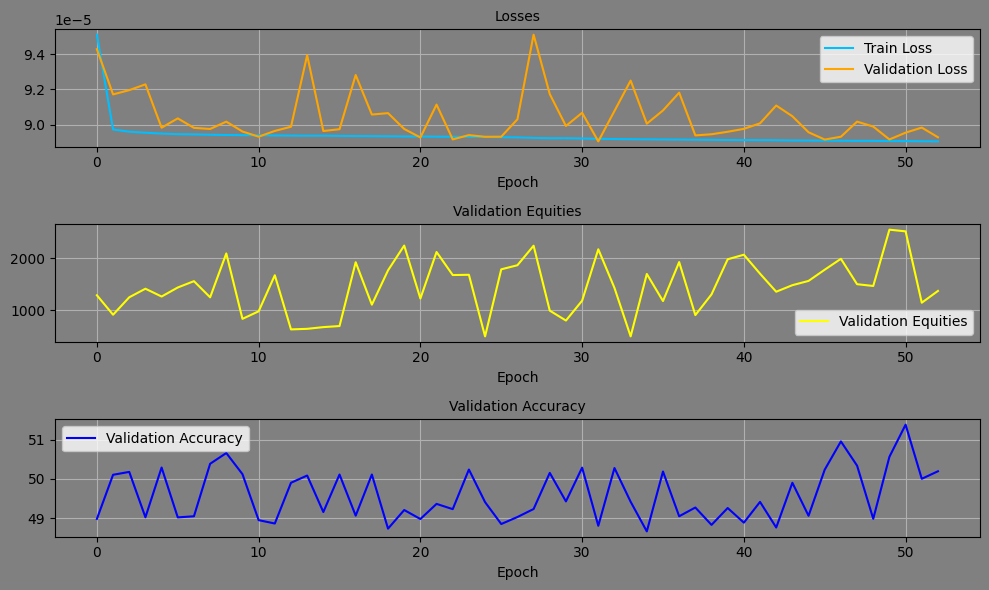

Epoch: 53, Val Equity: 1860.92, Val Accuracy: 49.78 train_losses: 0.0002738283054682364, val_losses: 8.973047079052776e-05, Duration: 0:01:50.359795


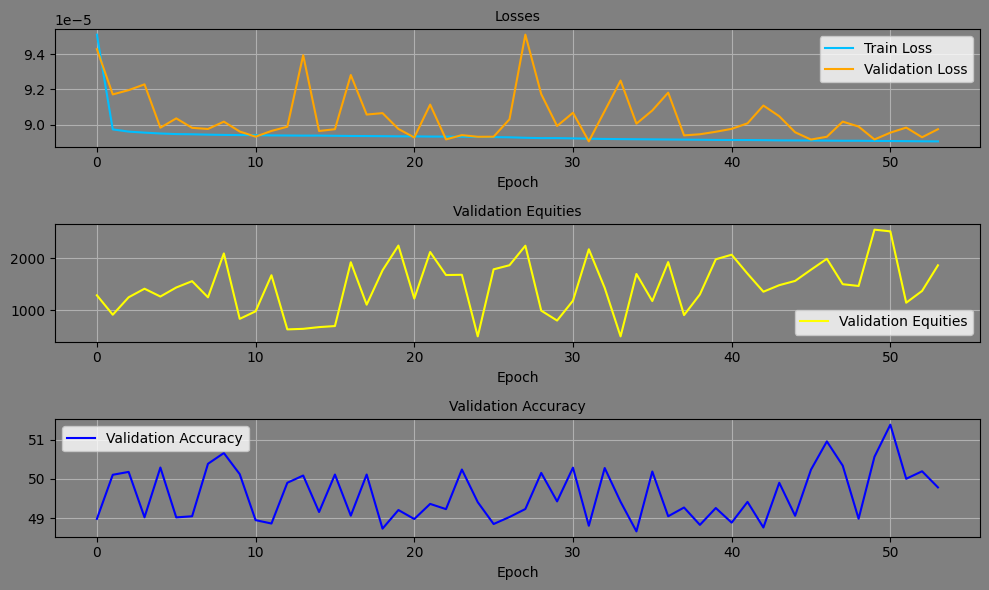

Epoch: 54, Val Equity: 1410.00, Val Accuracy: 48.97 train_losses: 0.000273767172611252, val_losses: 9.026561747305095e-05, Duration: 0:01:48.376314


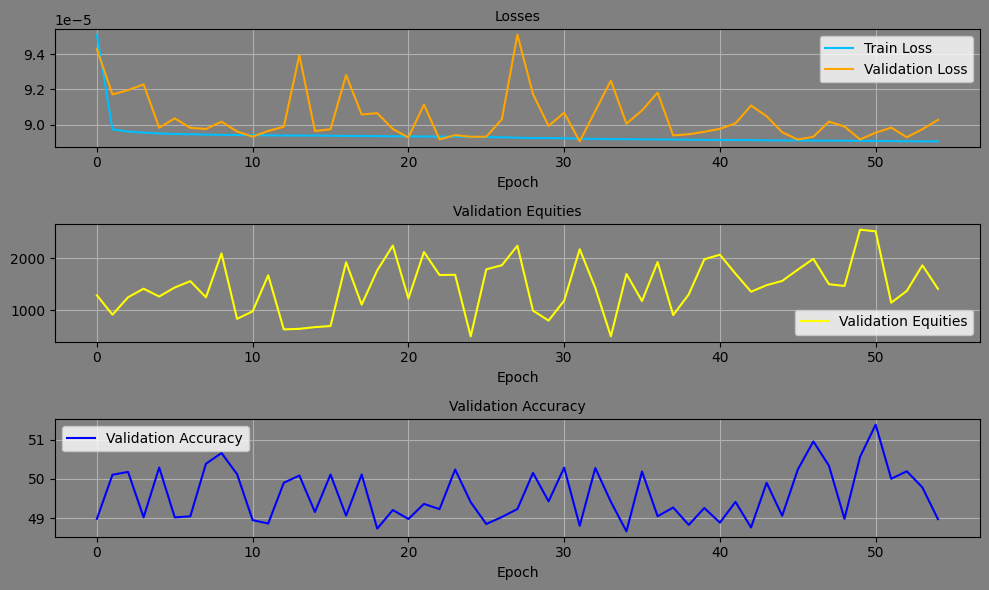

Epoch: 55, Val Equity: 1924.71, Val Accuracy: 50.79 train_losses: 0.00027355810713347676, val_losses: 8.982445433503017e-05, Duration: 0:01:48.554166


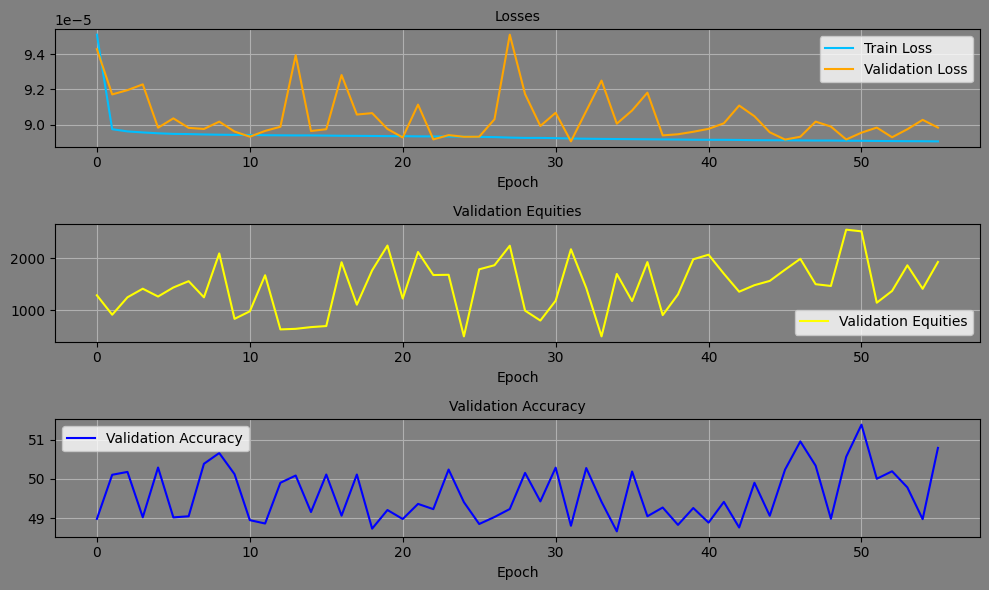

Epoch: 56, Val Equity: 2533.90, Val Accuracy: 51.13 train_losses: 0.00027365007419004496, val_losses: 8.92578245839104e-05, Duration: 0:01:48.090589


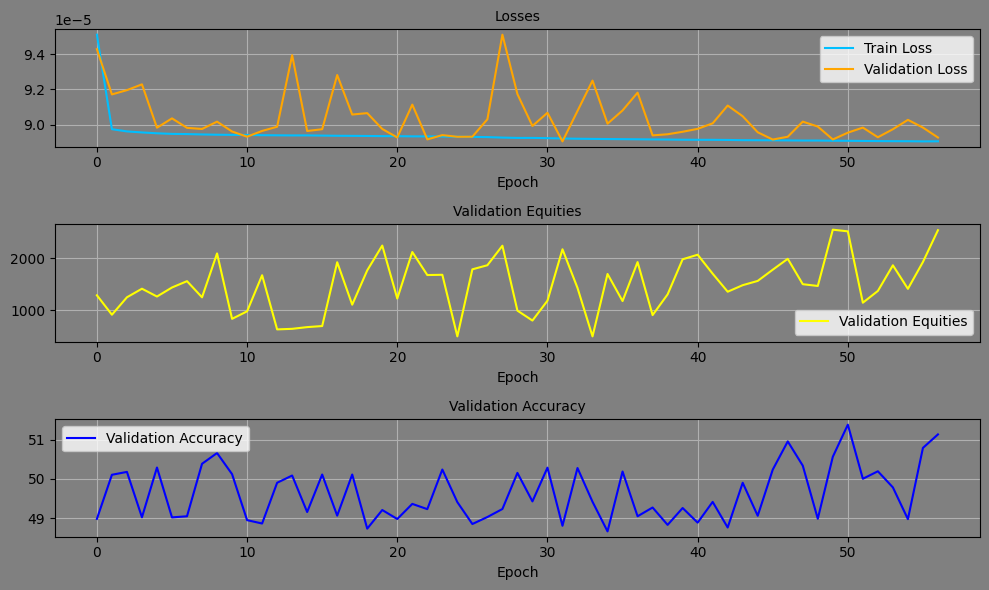

Epoch: 57, Val Equity: 1980.55, Val Accuracy: 49.23 train_losses: 0.0002733938196291173, val_losses: 8.896042709238827e-05, Duration: 0:01:49.035995


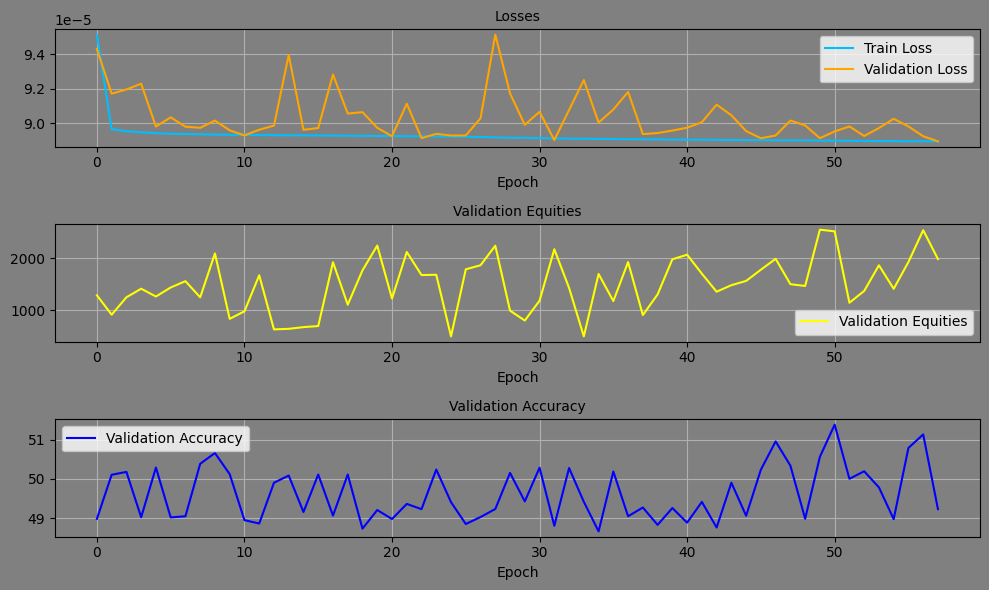

Epoch: 58, Val Equity: 2434.50, Val Accuracy: 51.41 train_losses: 0.00027333740025476695, val_losses: 8.928455645218492e-05, Duration: 0:01:52.669998


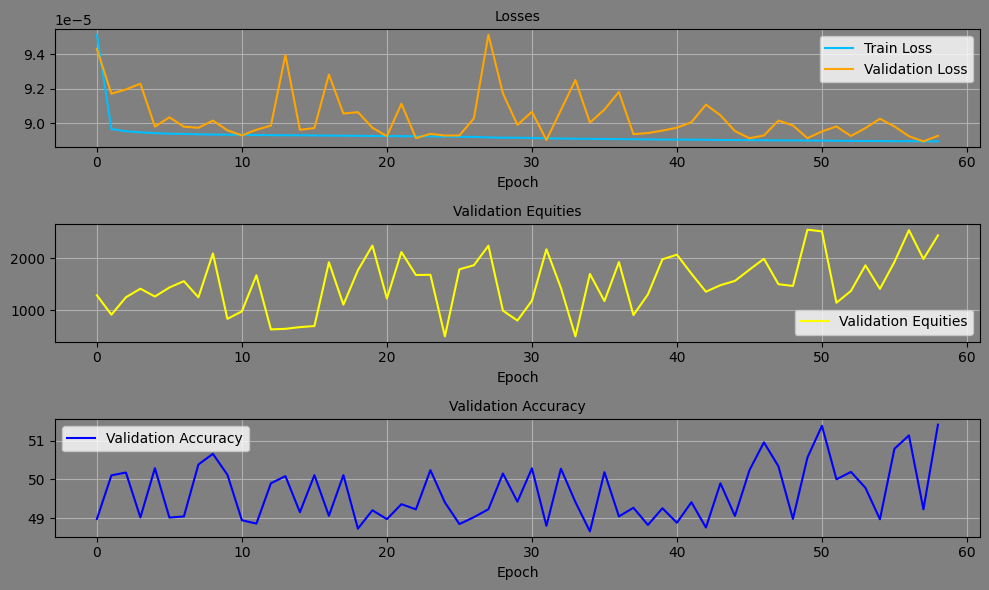

Epoch: 59, Val Equity: 1169.14, Val Accuracy: 50.35 train_losses: 0.0002731294717853978, val_losses: 8.993929077405483e-05, Duration: 0:01:48.461670


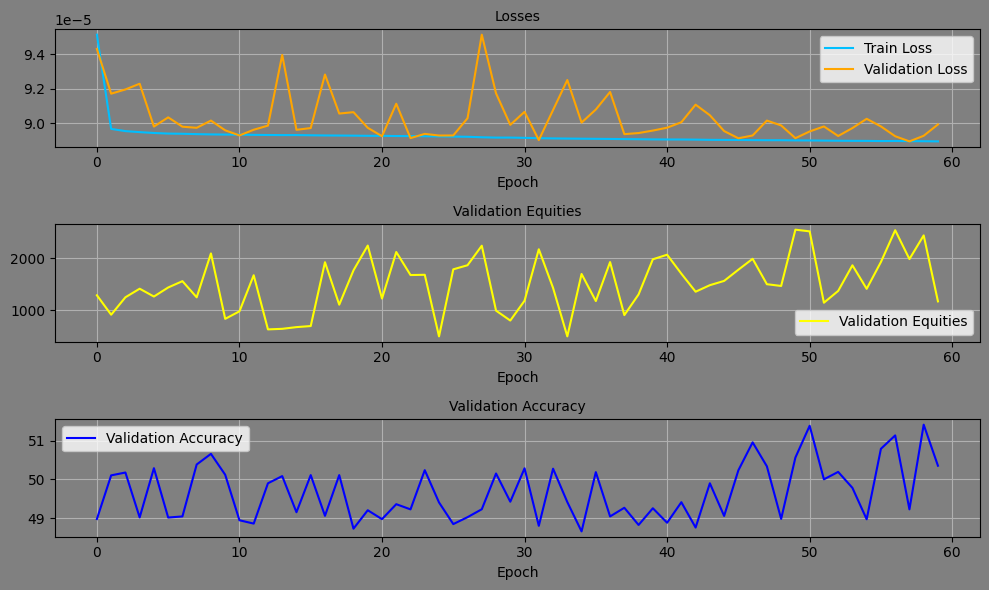

Epoch: 60, Val Equity: 1920.51, Val Accuracy: 50.64 train_losses: 0.0002730348439295233, val_losses: 8.947151218308136e-05, Duration: 0:01:50.345267


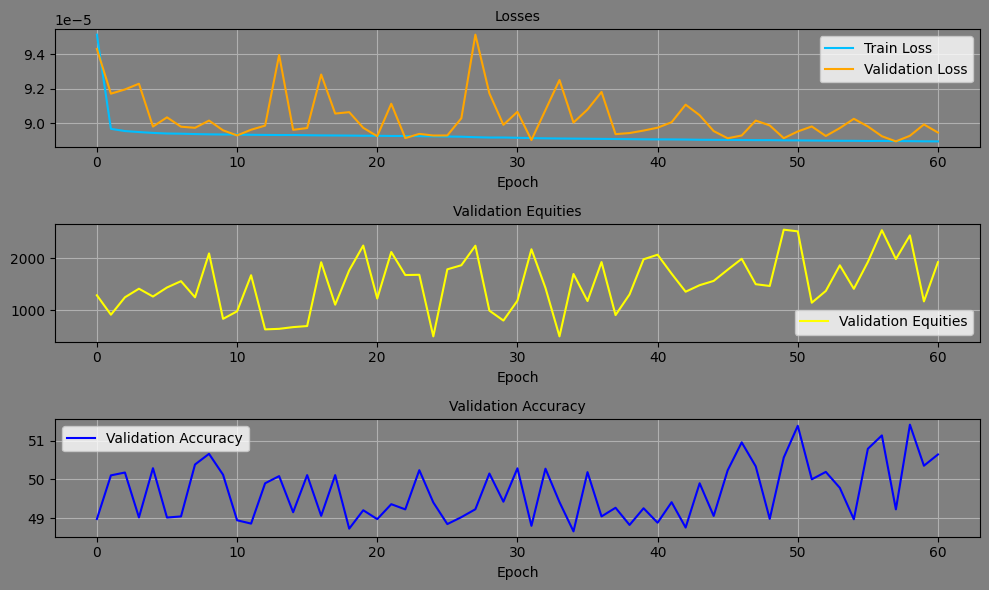

Epoch: 61, Val Equity: 1878.49, Val Accuracy: 51.20 train_losses: 0.0002730021144252421, val_losses: 8.936023368733004e-05, Duration: 0:01:57.515929


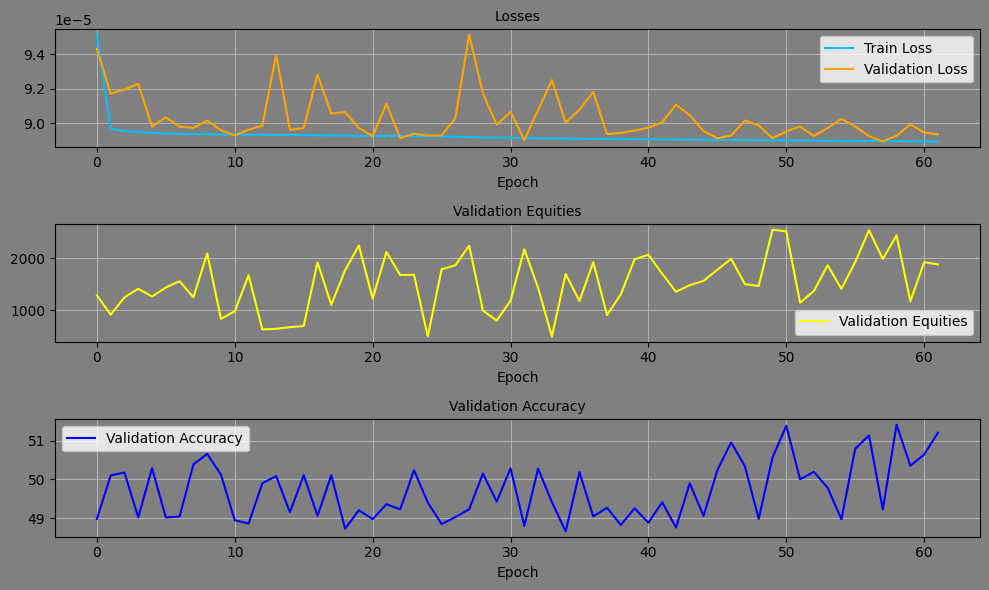

Epoch: 62, Val Equity: 2229.64, Val Accuracy: 50.81 train_losses: 0.00027274179739410605, val_losses: 8.880801760824397e-05, Duration: 0:01:51.327485


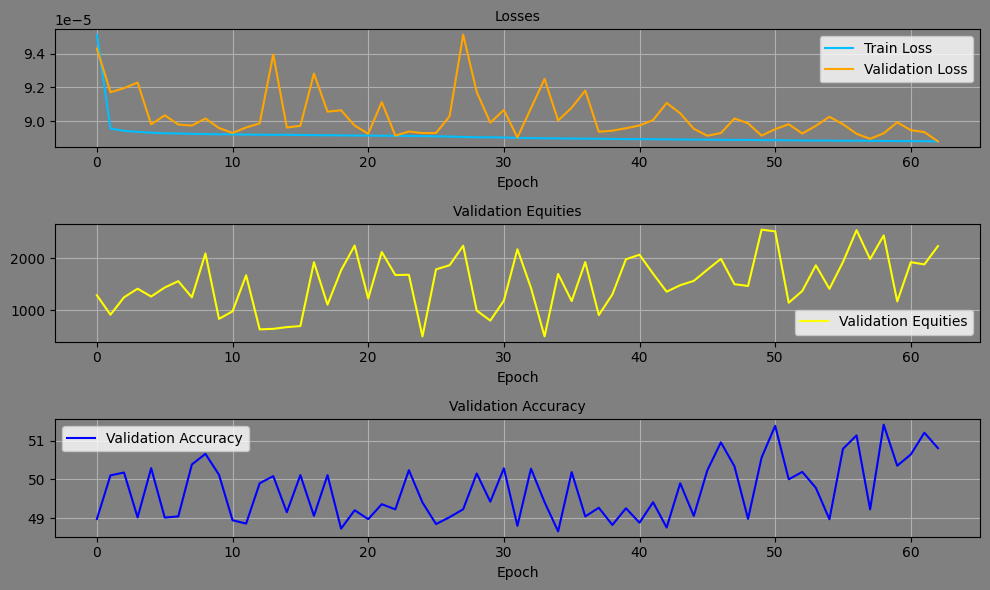

Epoch: 63, Val Equity: 2233.69, Val Accuracy: 51.81 train_losses: 0.0002727003624163518, val_losses: 8.949766197474673e-05, Duration: 0:01:52.944725


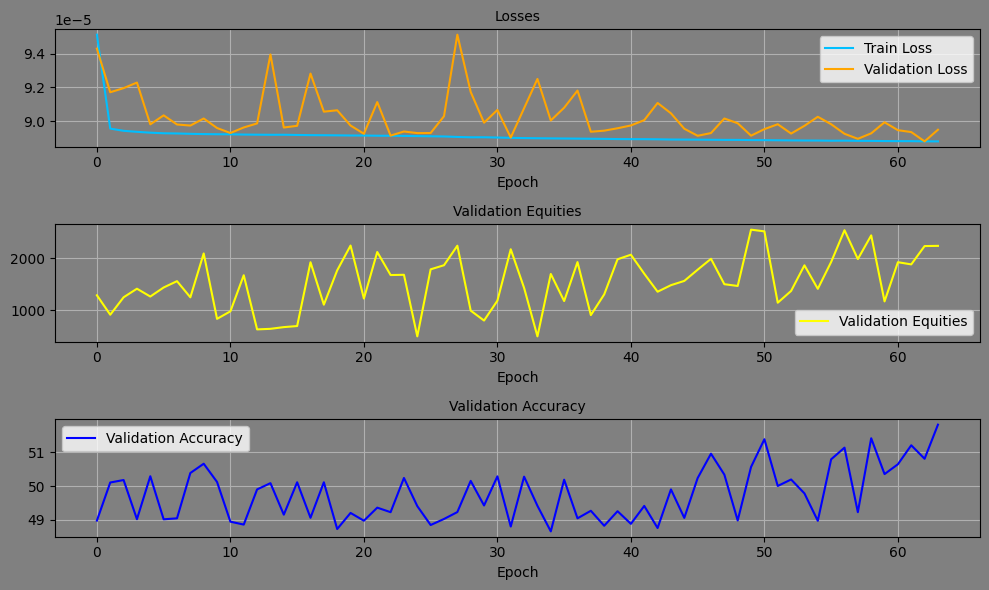

Epoch: 64, Val Equity: 1651.70, Val Accuracy: 50.46 train_losses: 0.0002723537158001308, val_losses: 9.000148565974087e-05, Duration: 0:01:49.354398


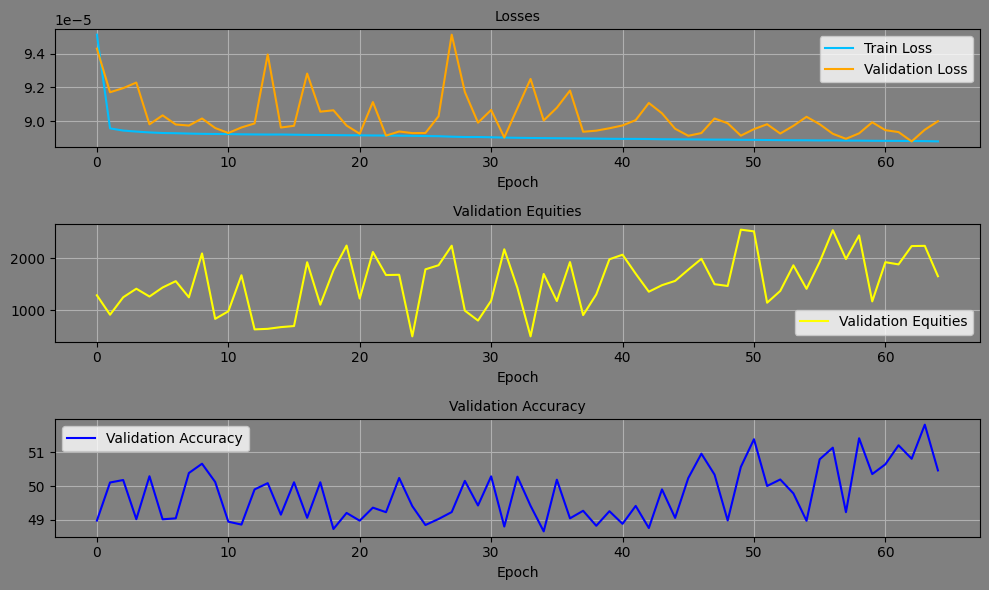

Epoch: 65, Val Equity: 1912.29, Val Accuracy: 49.69 train_losses: 0.00027231911316470713, val_losses: 8.875027560861781e-05, Duration: 0:01:55.469024


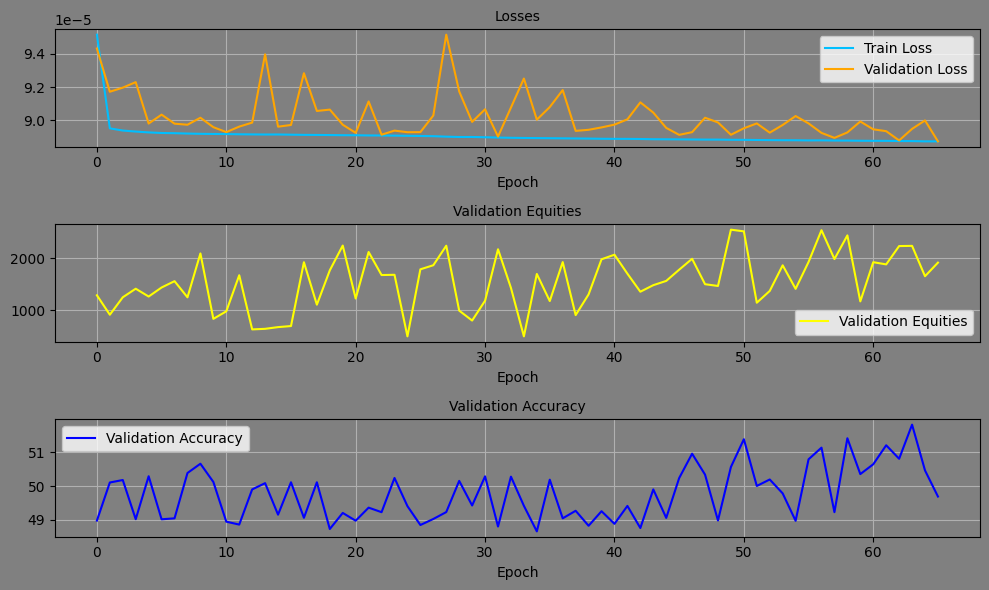

Epoch: 66, Val Equity: 1418.17, Val Accuracy: 48.81 train_losses: 0.00027227495518430934, val_losses: 9.153725113719702e-05, Duration: 0:01:56.760532


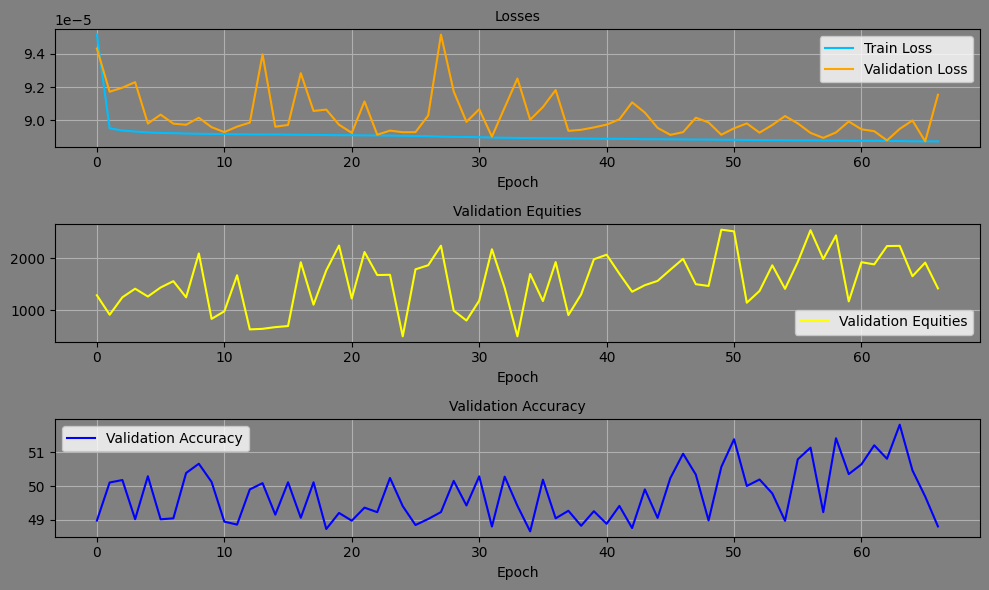

Epoch: 67, Val Equity: 2078.31, Val Accuracy: 49.71 train_losses: 0.0002721701465944771, val_losses: 9.064983169082552e-05, Duration: 0:01:54.589840


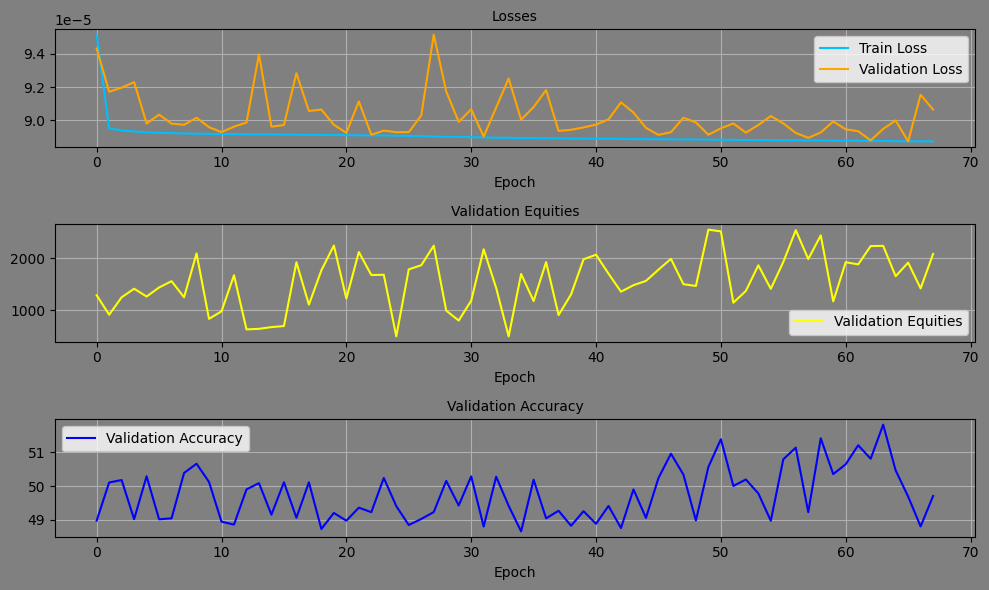

Epoch: 68, Val Equity: 1477.21, Val Accuracy: 49.05 train_losses: 0.00027198951439261253, val_losses: 8.94991826498881e-05, Duration: 0:01:59.278423


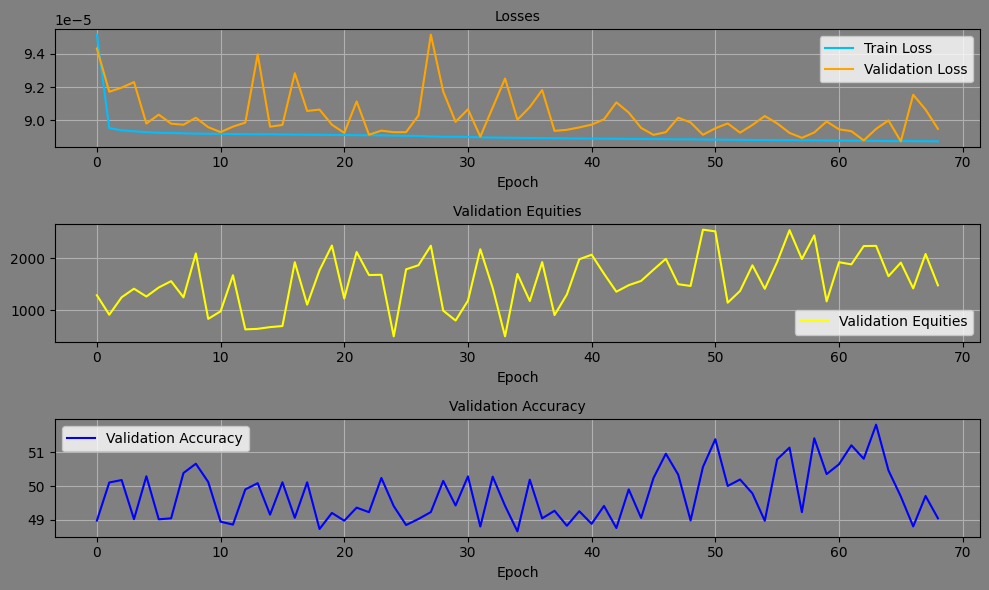

Epoch: 69, Val Equity: 1790.58, Val Accuracy: 49.22 train_losses: 0.0002718180405925826, val_losses: 8.981216524261981e-05, Duration: 0:01:52.221086


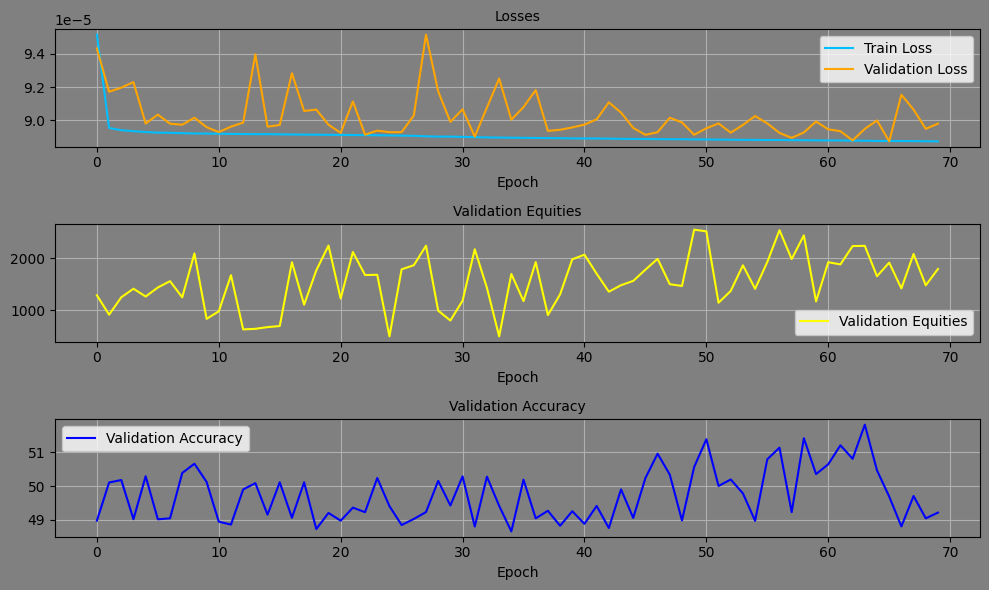

Epoch: 70, Val Equity: 1393.06, Val Accuracy: 50.10 train_losses: 0.0002720167977719118, val_losses: 8.943225839175284e-05, Duration: 0:01:57.952647


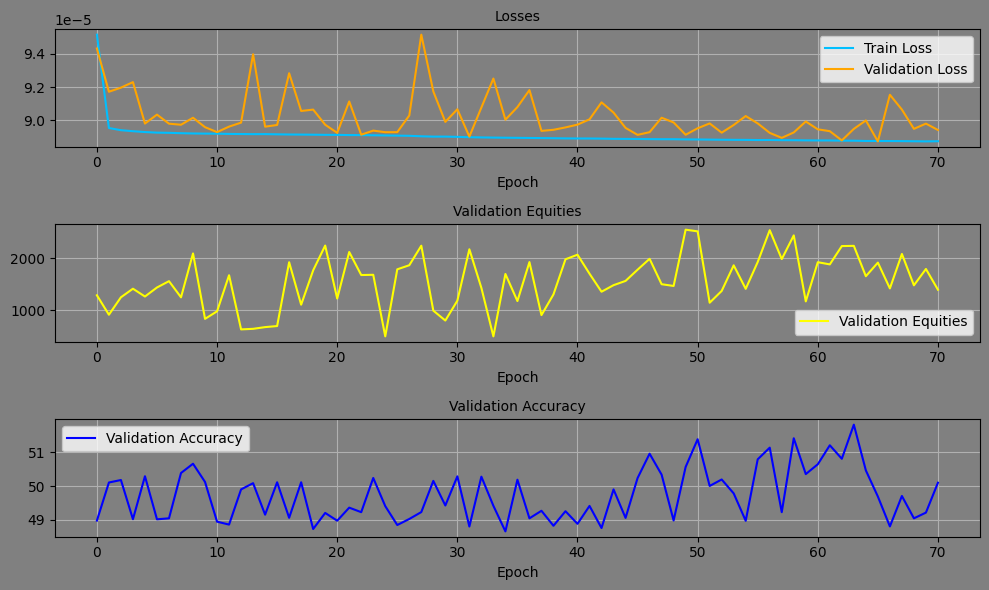

Epoch: 71, Val Equity: 1386.07, Val Accuracy: 50.17 train_losses: 0.0002716672350180577, val_losses: 8.894164784578606e-05, Duration: 0:01:52.380935


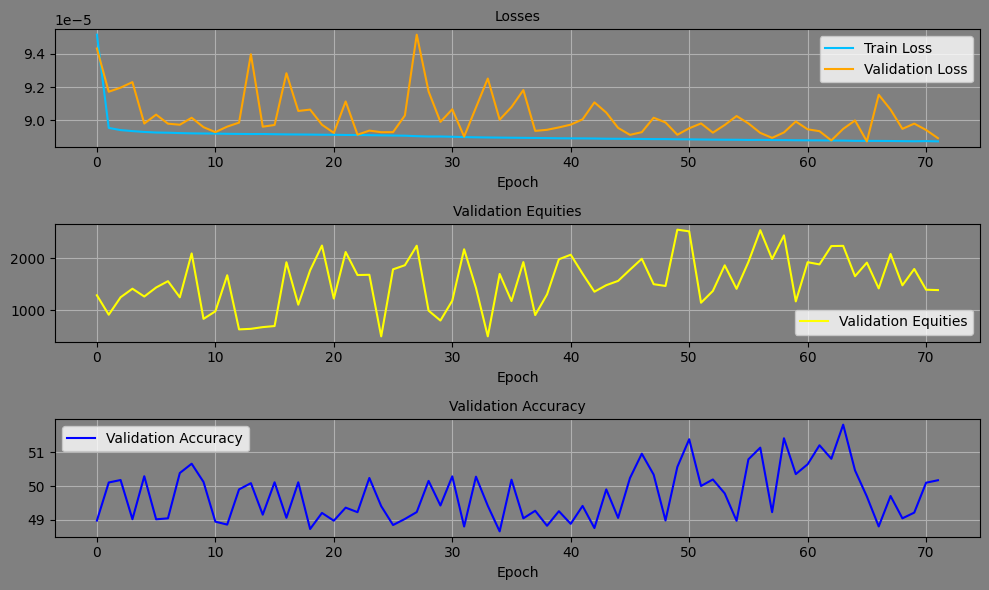

Epoch: 72, Val Equity: 1050.27, Val Accuracy: 50.20 train_losses: 0.0002716483236826007, val_losses: 8.941943815443665e-05, Duration: 0:01:51.518429


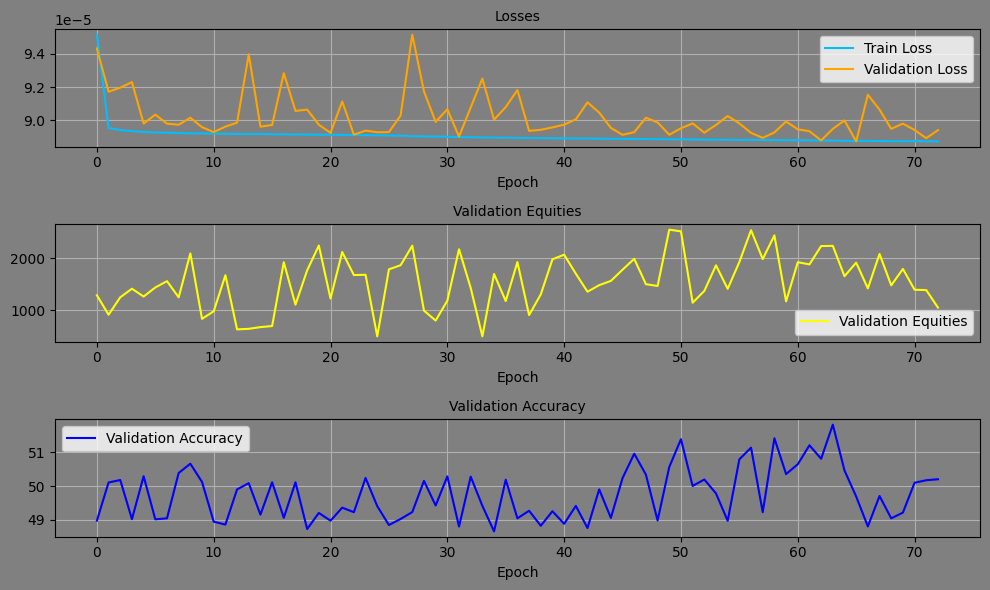

Epoch: 73, Val Equity: 2103.72, Val Accuracy: 51.22 train_losses: 0.00027139456521139645, val_losses: 8.978955156635493e-05, Duration: 0:01:50.066384


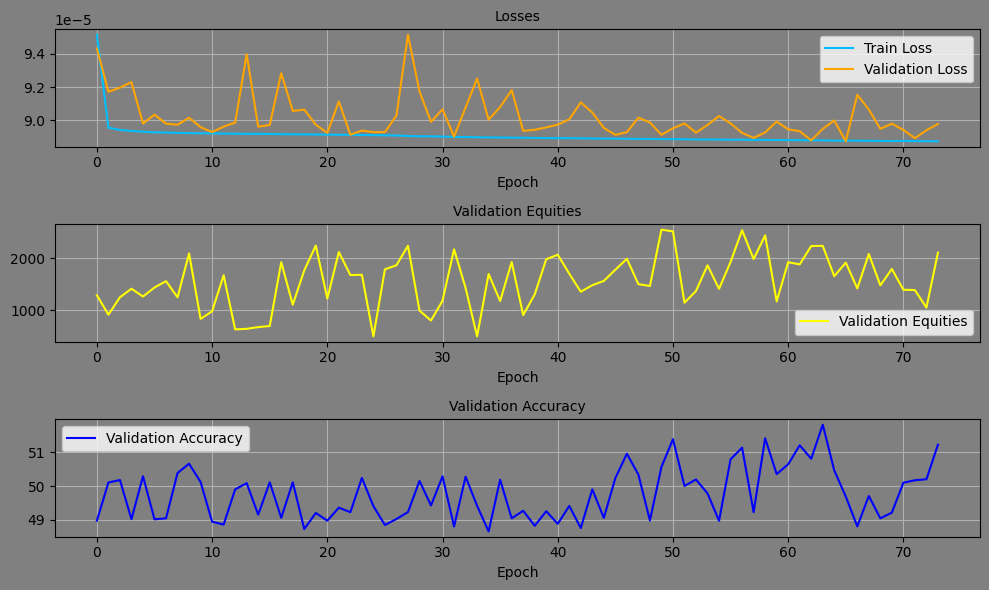

Epoch: 74, Val Equity: 1176.91, Val Accuracy: 50.34 train_losses: 0.00027150538800547444, val_losses: 8.905508002499118e-05, Duration: 0:01:49.494254


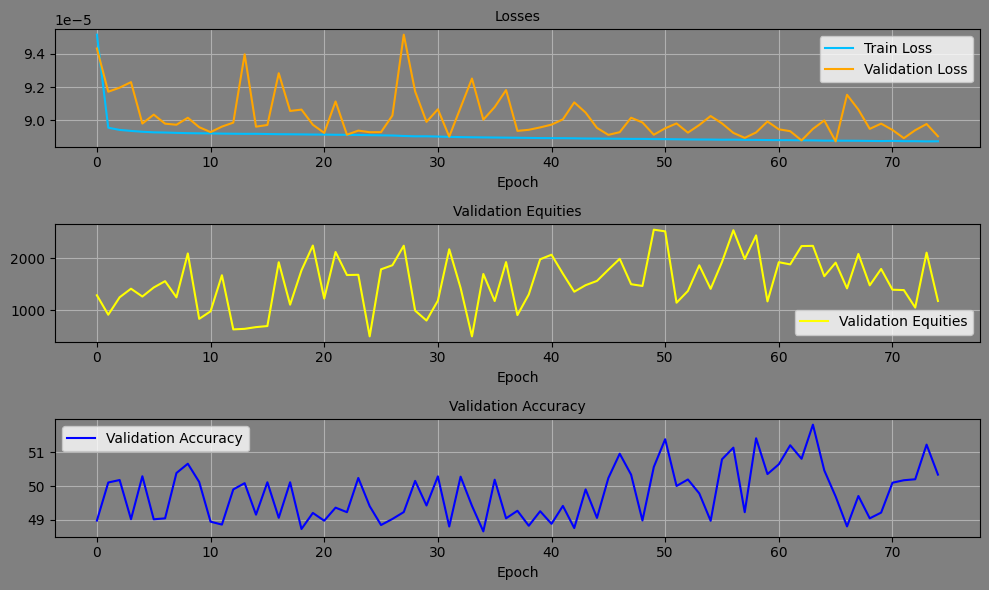

Epoch: 75, Val Equity: 1976.31, Val Accuracy: 50.86 train_losses: 0.00027133414555815925, val_losses: 8.881329995347187e-05, Duration: 0:01:51.518654


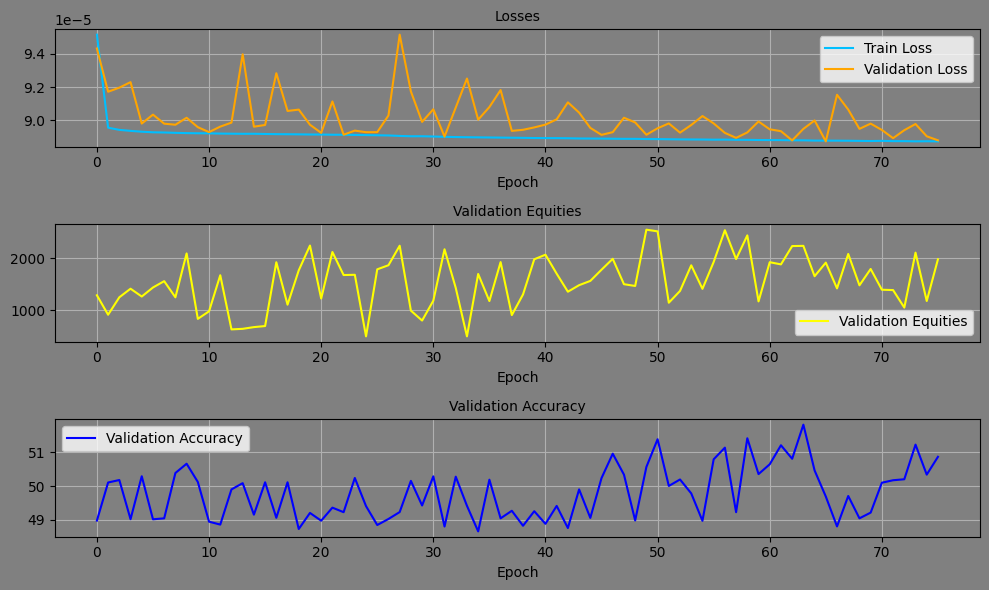

Epoch: 76, Val Equity: 728.31, Val Accuracy: 49.84 train_losses: 0.000271106320486354, val_losses: 8.952562347985804e-05, Duration: 0:01:51.393934


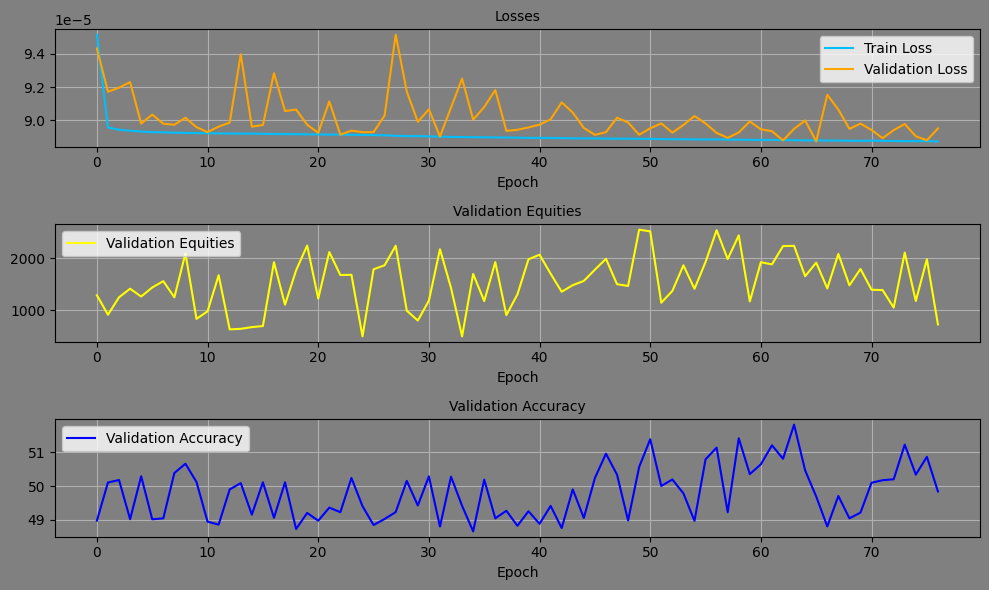

Epoch: 77, Val Equity: 869.30, Val Accuracy: 50.18 train_losses: 0.0002712159868015374, val_losses: 8.912261546356604e-05, Duration: 0:01:49.520675


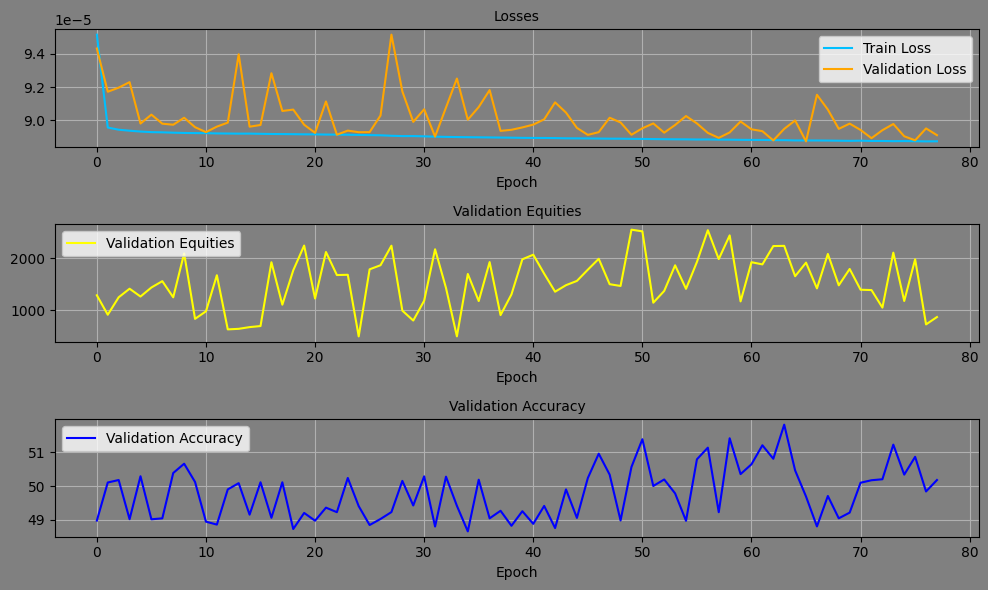

Epoch: 78, Val Equity: 1548.55, Val Accuracy: 49.38 train_losses: 0.00027091585515820514, val_losses: 8.910932228900492e-05, Duration: 0:01:49.635758


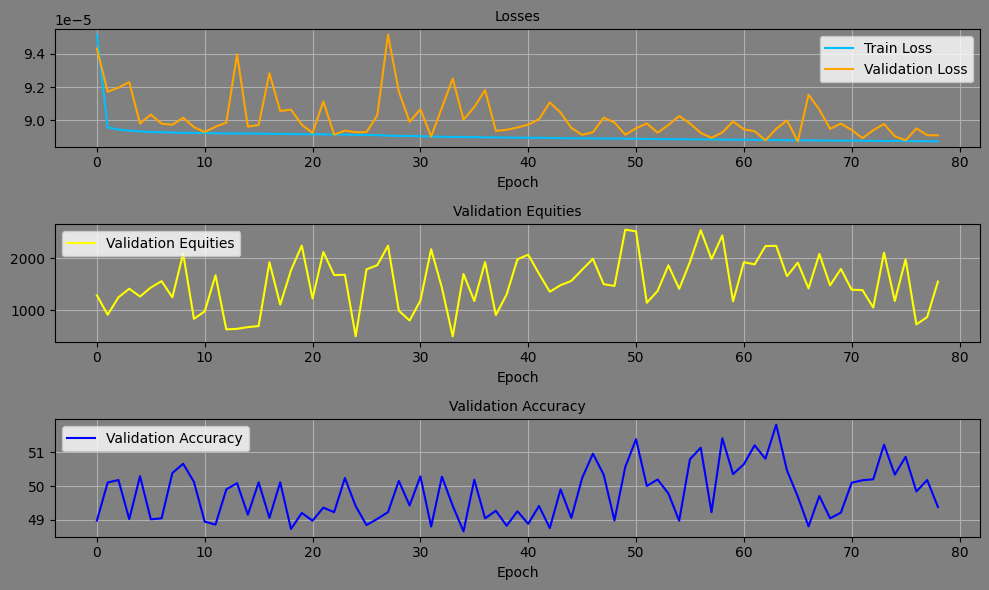

Epoch: 79, Val Equity: 1809.03, Val Accuracy: 50.54 train_losses: 0.000270939379912469, val_losses: 8.949534094426781e-05, Duration: 0:01:50.247472


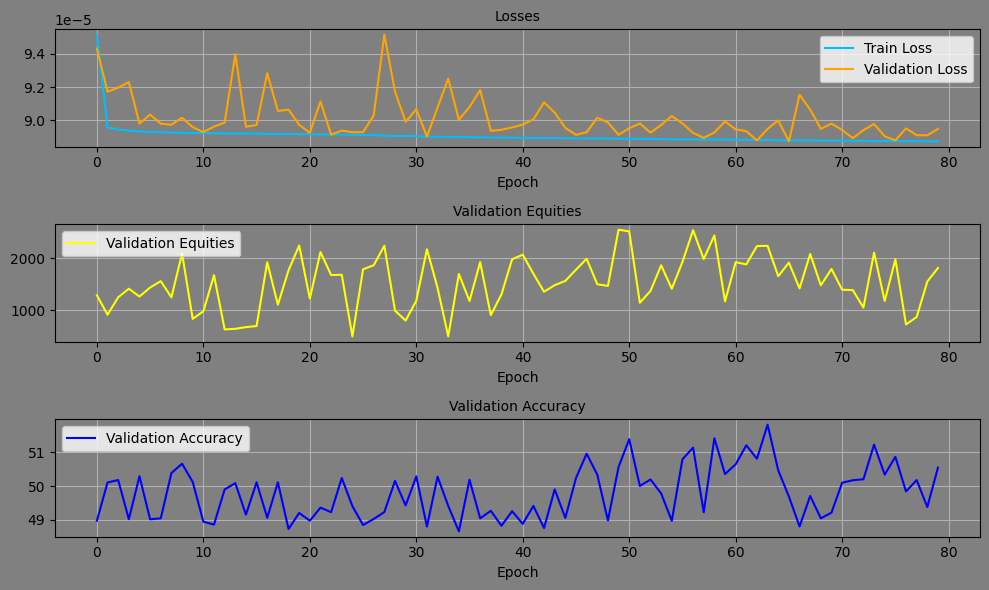

Epoch: 80, Val Equity: 1868.39, Val Accuracy: 50.04 train_losses: 0.0002704831055980802, val_losses: 9.03107866179198e-05, Duration: 0:01:49.972130


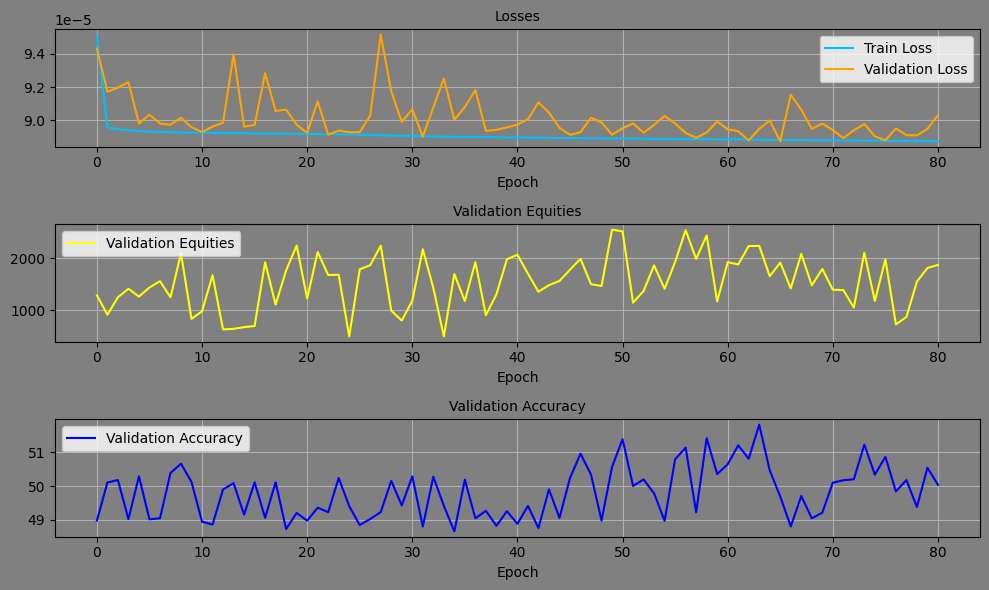

Epoch: 81, Val Equity: 1491.92, Val Accuracy: 50.41 train_losses: 0.00027063761199111854, val_losses: 9.010986832436174e-05, Duration: 0:01:51.461525


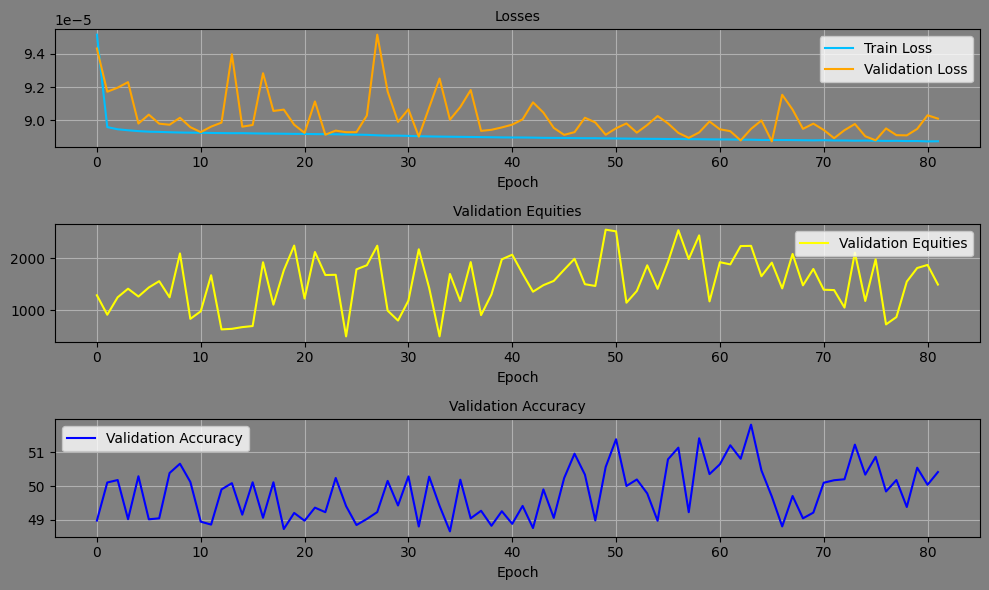

Epoch: 82, Val Equity: 1076.95, Val Accuracy: 50.22 train_losses: 0.0002706012642608873, val_losses: 9.044918260769919e-05, Duration: 0:01:51.705321


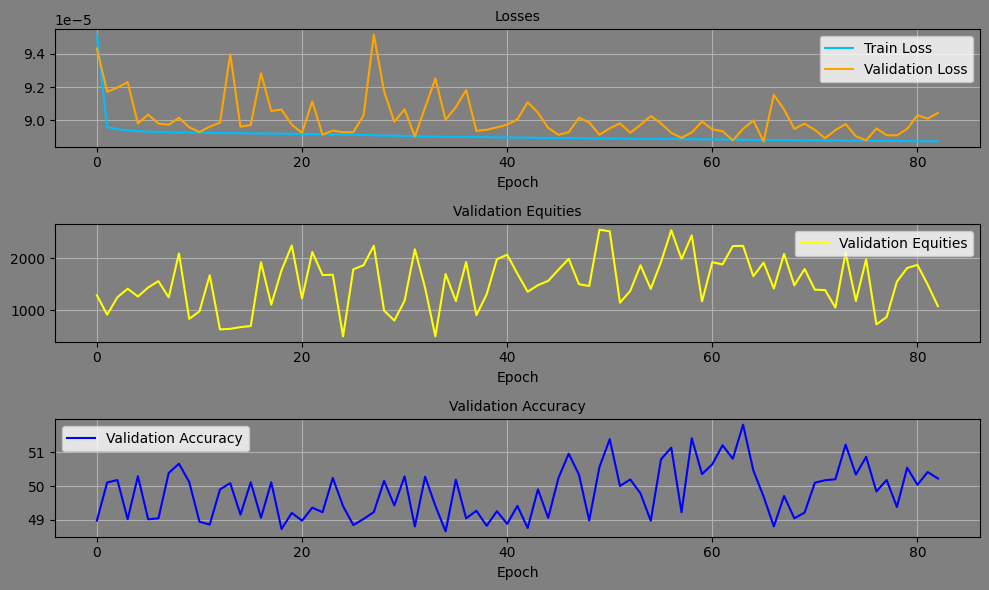

Epoch: 83, Val Equity: 1423.84, Val Accuracy: 48.88 train_losses: 0.0002700811453109039, val_losses: 8.927965973271057e-05, Duration: 0:01:49.648717


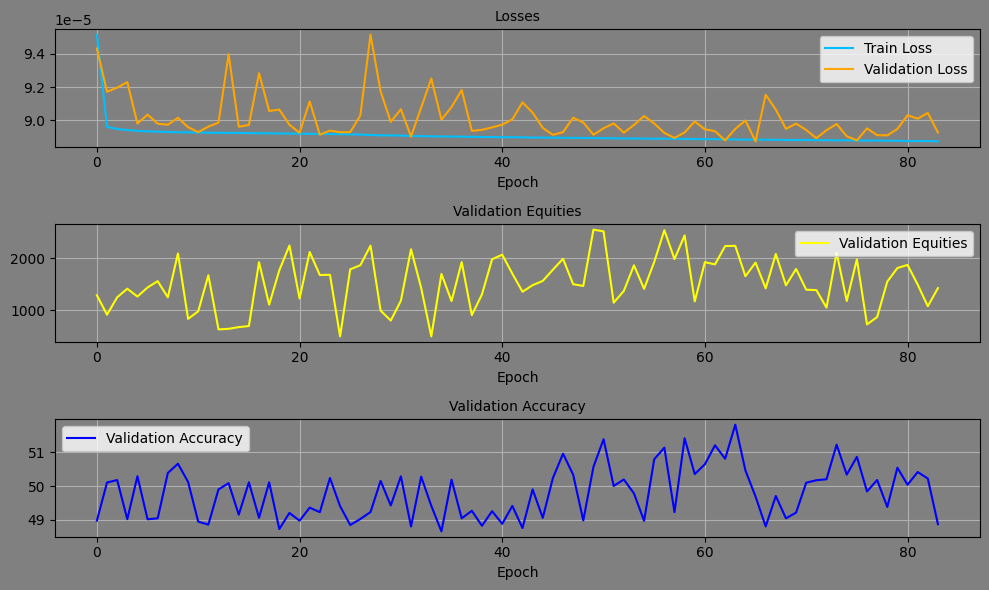

Epoch: 84, Val Equity: 2386.21, Val Accuracy: 50.50 train_losses: 0.0002701313162620915, val_losses: 9.028942440636456e-05, Duration: 0:01:49.210422


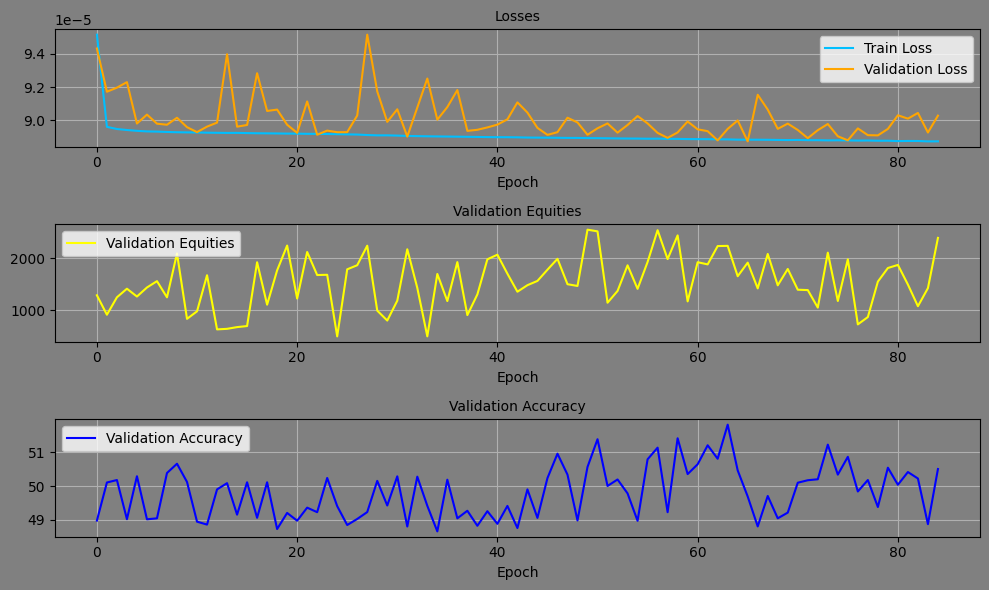

Epoch: 85, Val Equity: 1153.12, Val Accuracy: 50.15 train_losses: 0.00027008421559032757, val_losses: 9.054382098838687e-05, Duration: 0:01:51.970748


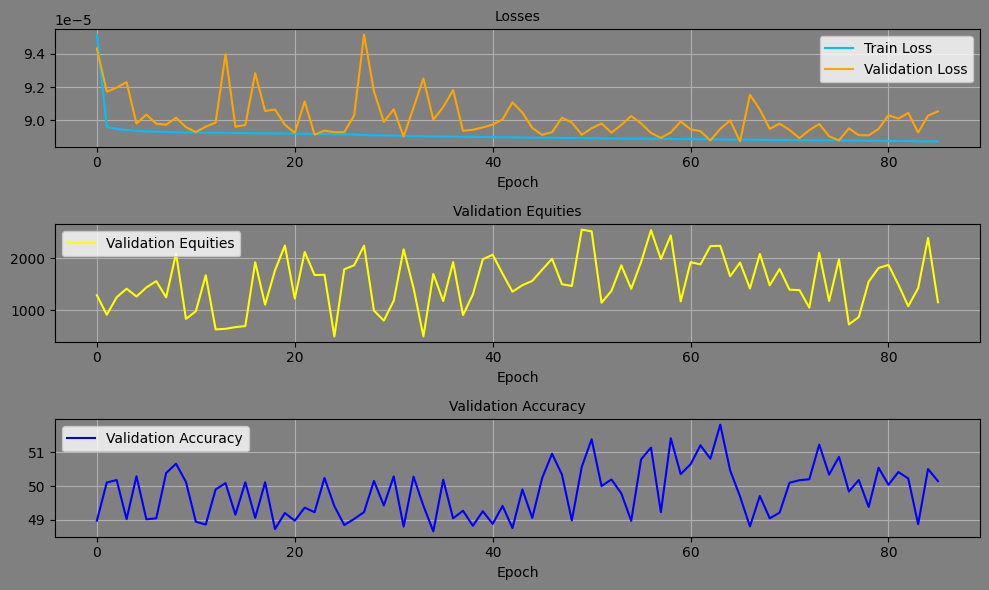

Epoch: 86, Val Equity: 1174.78, Val Accuracy: 49.80 train_losses: 0.0002700280775021694, val_losses: 8.89544899109751e-05, Duration: 0:01:50.114255


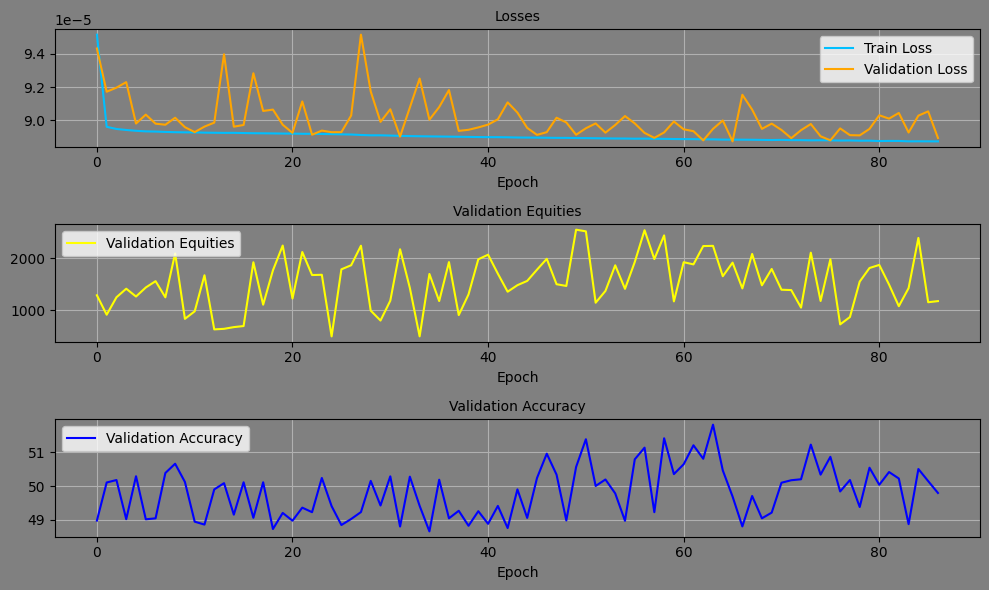

Epoch: 87, Val Equity: 1067.47, Val Accuracy: 50.38 train_losses: 0.00026985551025658855, val_losses: 8.932774653658271e-05, Duration: 0:01:53.545966


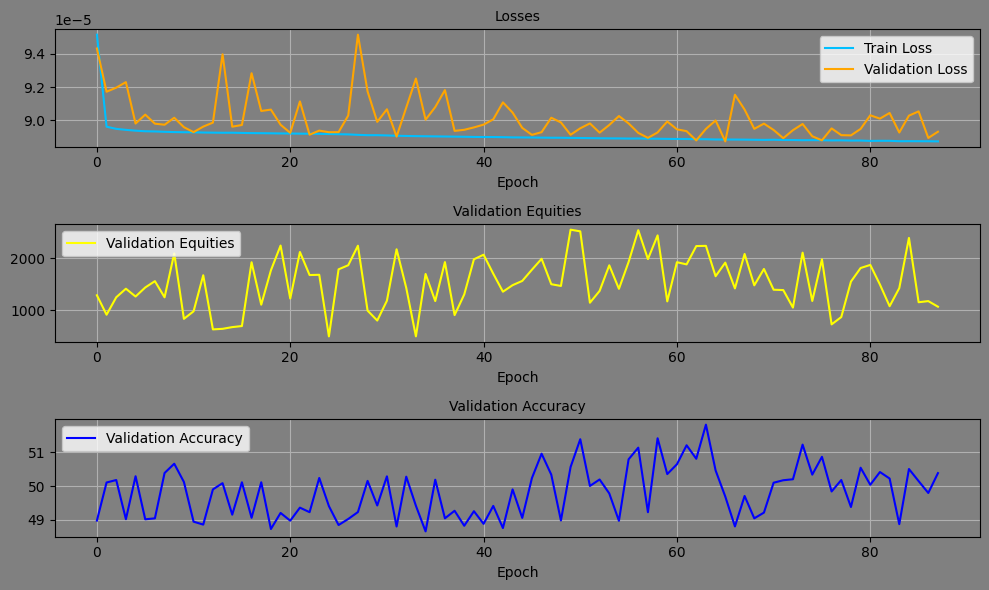

Epoch: 88, Val Equity: 1550.99, Val Accuracy: 49.97 train_losses: 0.0002699723015851534, val_losses: 8.920986147131771e-05, Duration: 0:01:49.227242


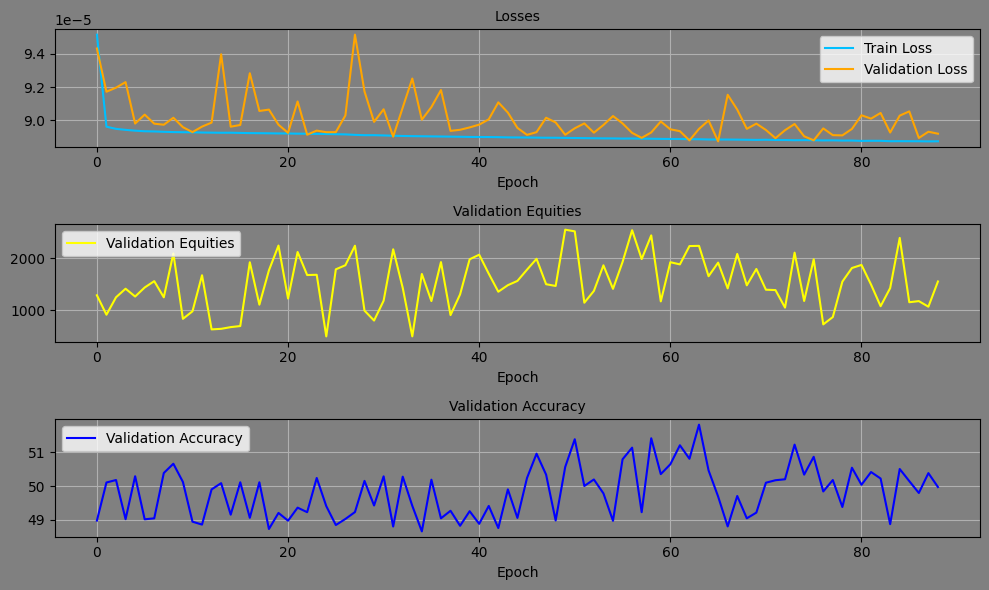

Epoch: 89, Val Equity: 612.42, Val Accuracy: 48.37 train_losses: 0.00026956380321969964, val_losses: 8.912676275940612e-05, Duration: 0:01:48.563138


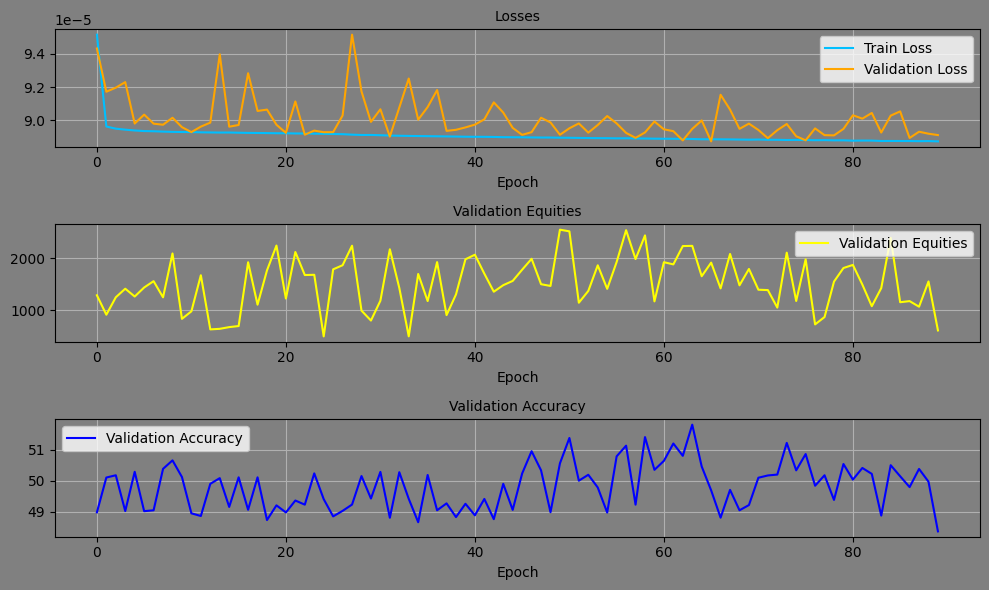

Epoch: 90, Val Equity: 1818.49, Val Accuracy: 49.83 train_losses: 0.0002696724371613468, val_losses: 8.97204372449778e-05, Duration: 0:01:49.016217


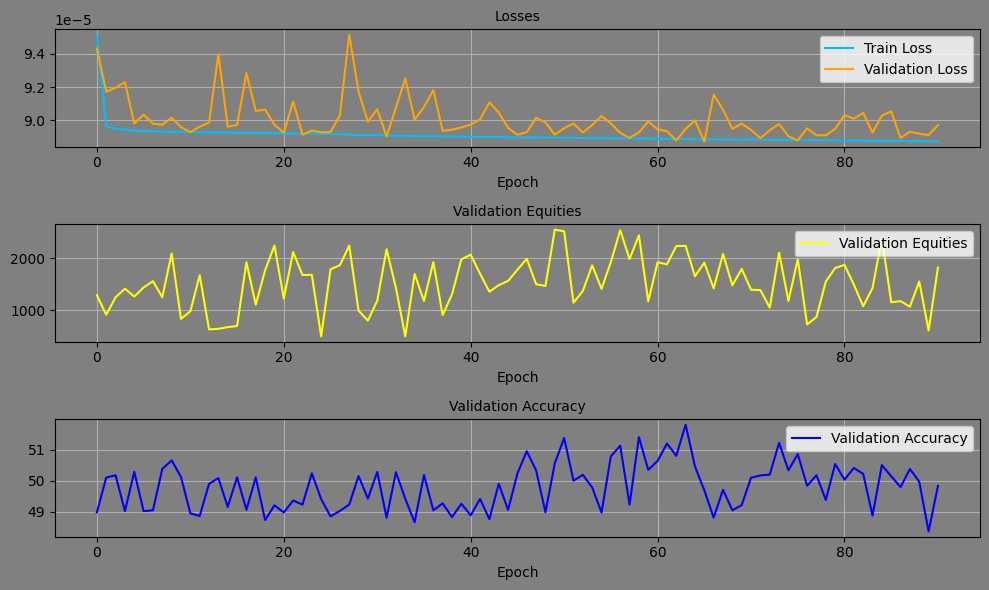

Epoch: 91, Val Equity: 1373.91, Val Accuracy: 50.43 train_losses: 0.00026948236541795445, val_losses: 8.90586306923069e-05, Duration: 0:01:50.685043


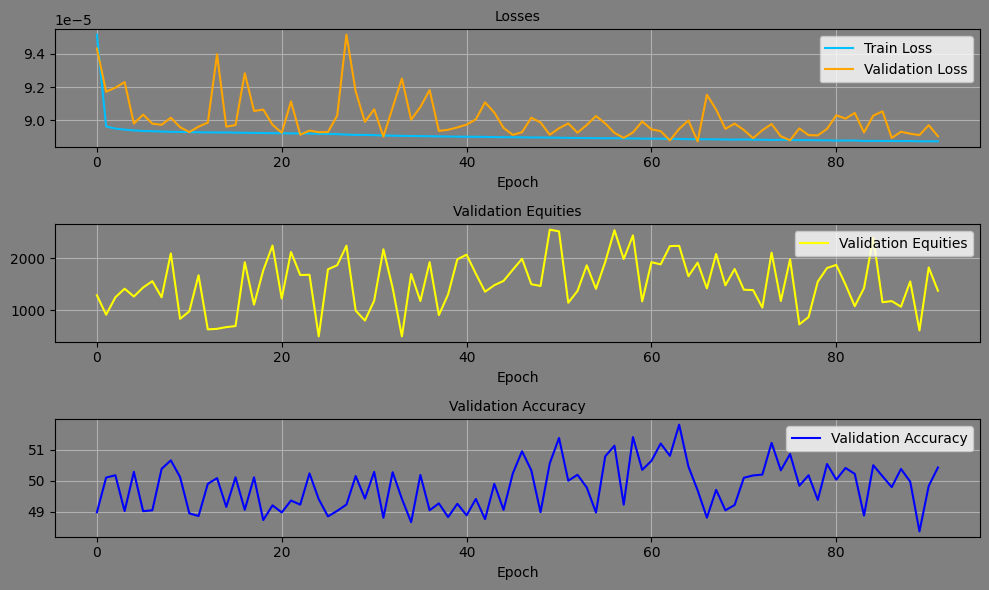

Epoch: 92, Val Equity: 1797.39, Val Accuracy: 49.25 train_losses: 0.00026925425799980416, val_losses: 9.123414201894775e-05, Duration: 0:01:49.057081


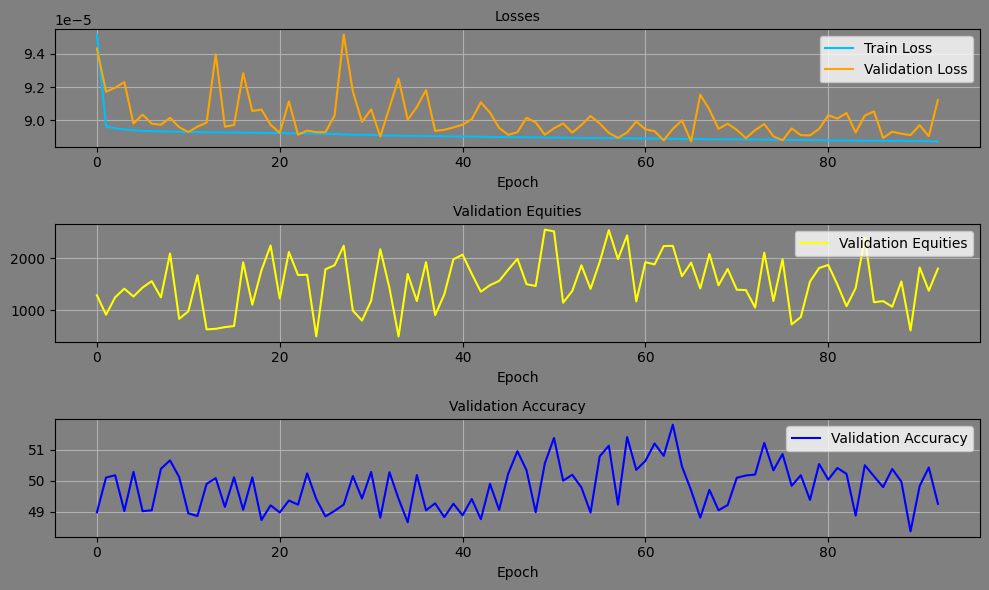

Epoch: 93, Val Equity: 2227.85, Val Accuracy: 51.34 train_losses: 0.0002693116289482369, val_losses: 8.896346116671339e-05, Duration: 0:01:48.206539


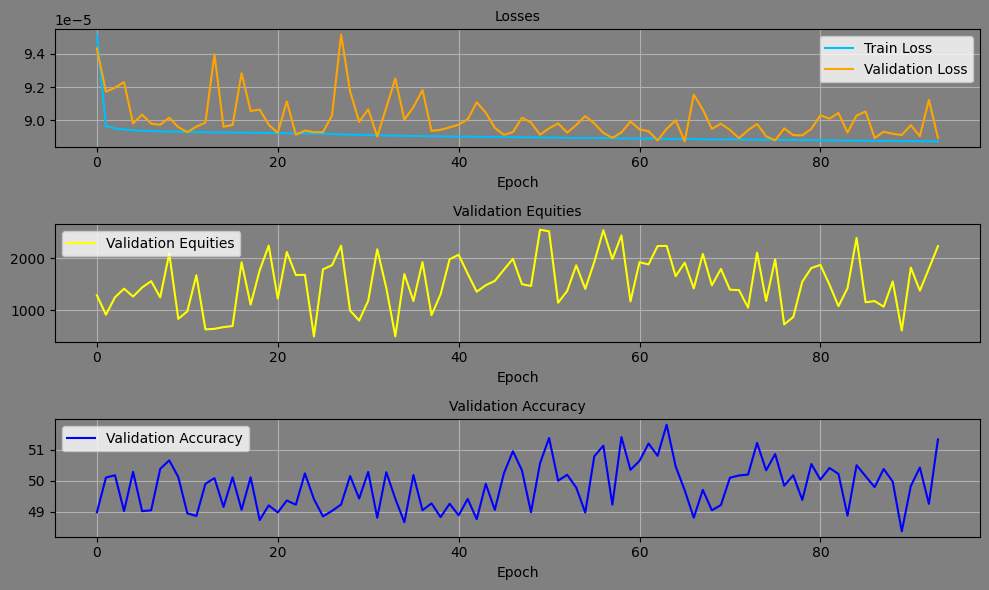

Epoch: 94, Val Equity: 1366.46, Val Accuracy: 50.32 train_losses: 0.0002691273237529436, val_losses: 8.93744218046777e-05, Duration: 0:01:49.718948


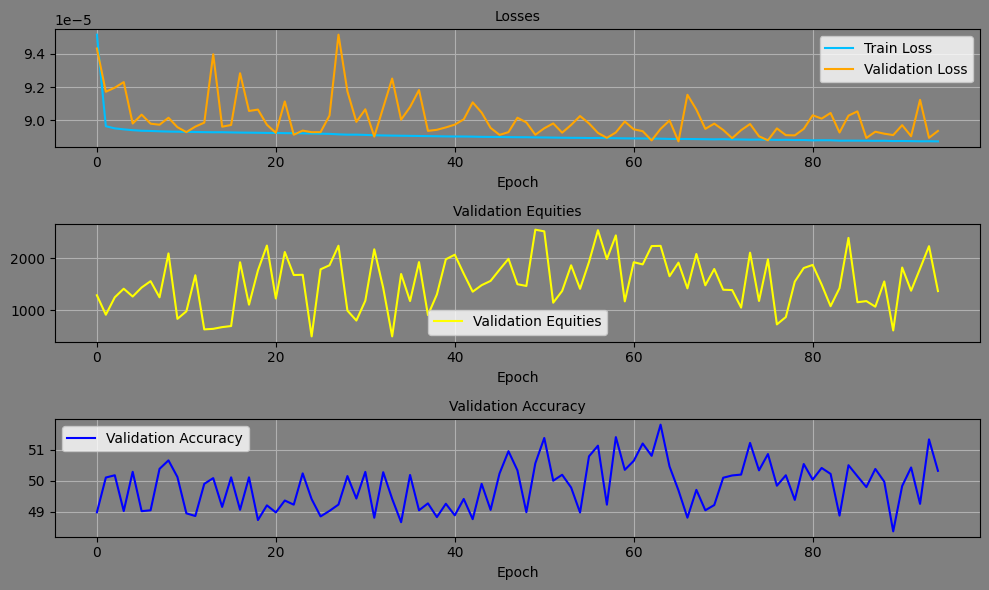

Epoch: 95, Val Equity: 1966.02, Val Accuracy: 51.03 train_losses: 0.00026916957997345, val_losses: 9.032287198351696e-05, Duration: 0:01:49.921934


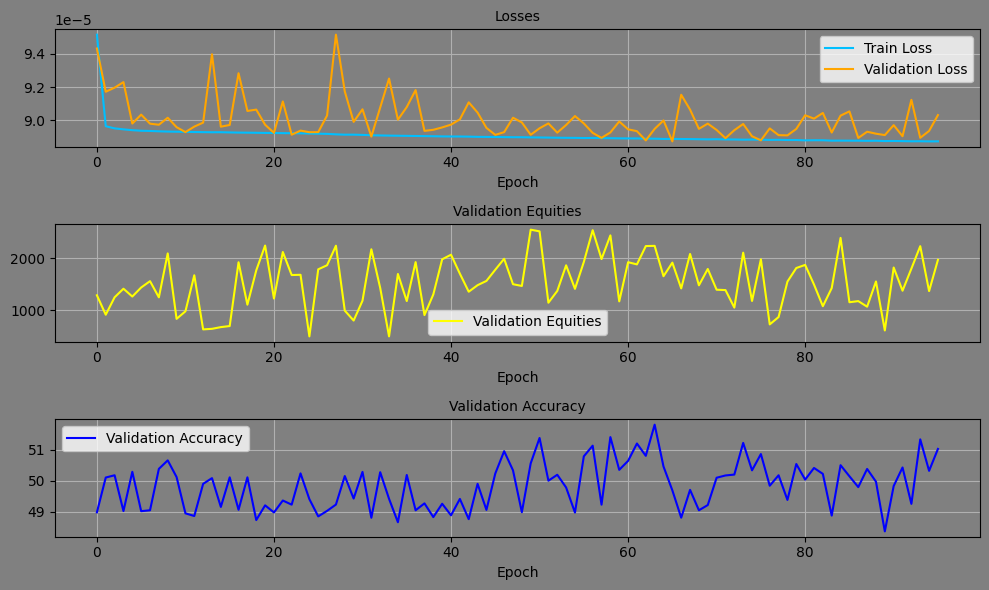

Epoch: 96, Val Equity: 884.83, Val Accuracy: 50.11 train_losses: 0.00026873931871734856, val_losses: 9.105529898079112e-05, Duration: 0:01:50.409672


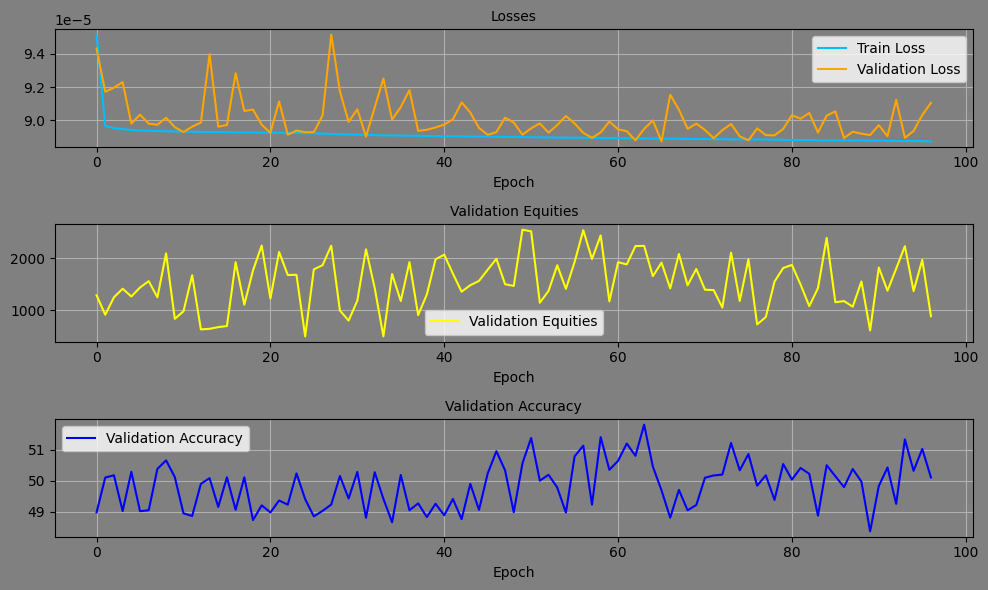

Epoch: 97, Val Equity: 2077.35, Val Accuracy: 49.78 train_losses: 0.00026879201828101365, val_losses: 8.920783147914335e-05, Duration: 0:01:50.267076


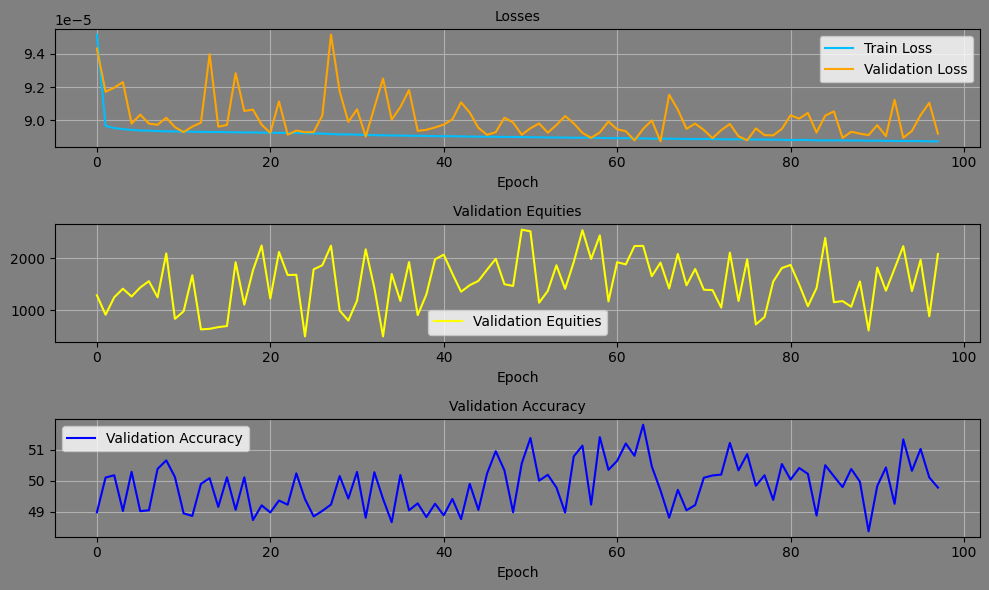

Epoch: 98, Val Equity: 1858.07, Val Accuracy: 49.47 train_losses: 0.00026875762622365263, val_losses: 8.913797501008958e-05, Duration: 0:01:51.015185


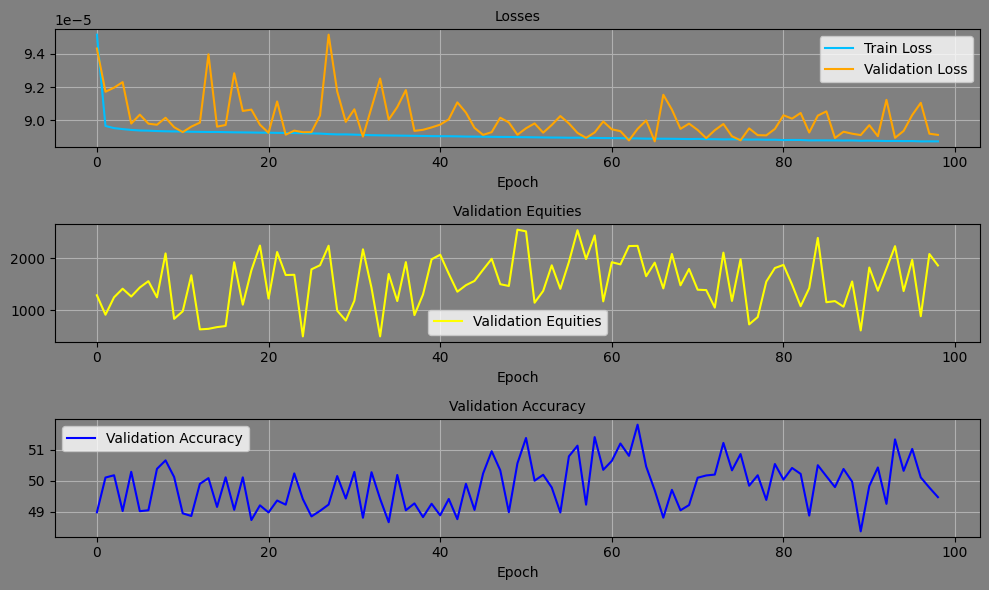

Epoch: 99, Val Equity: 877.35, Val Accuracy: 49.94 train_losses: 0.00026861628332130566, val_losses: 8.962421998148784e-05, Duration: 0:01:49.276820


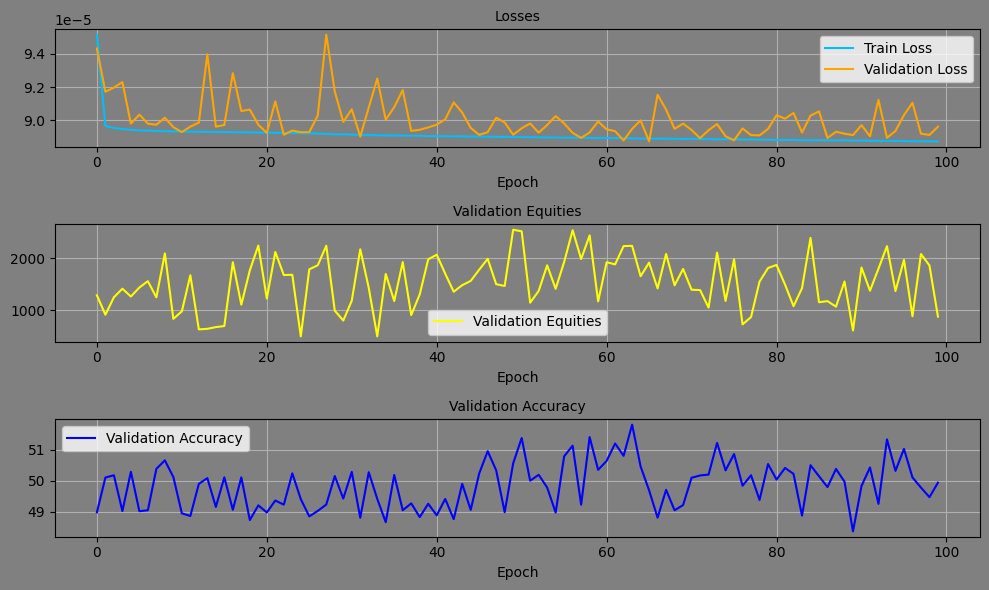

Epoch: 100, Val Equity: 1336.32, Val Accuracy: 49.11 train_losses: 0.00026852418592046725, val_losses: 8.906128641683608e-05, Duration: 0:01:52.242567


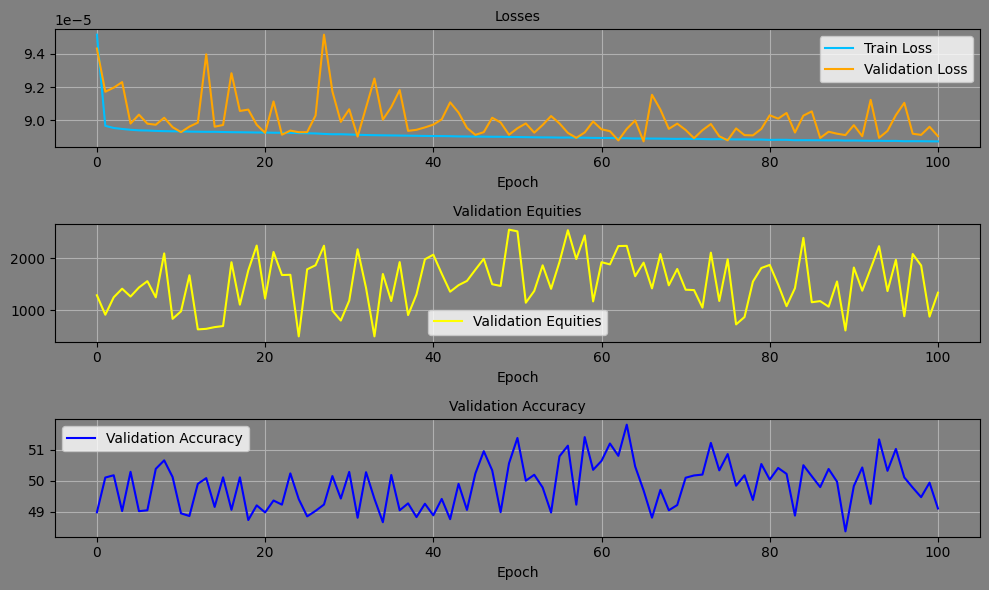

Epoch: 101, Val Equity: 1728.55, Val Accuracy: 51.12 train_losses: 0.0002681501447914417, val_losses: 8.902243280317634e-05, Duration: 0:01:49.473615


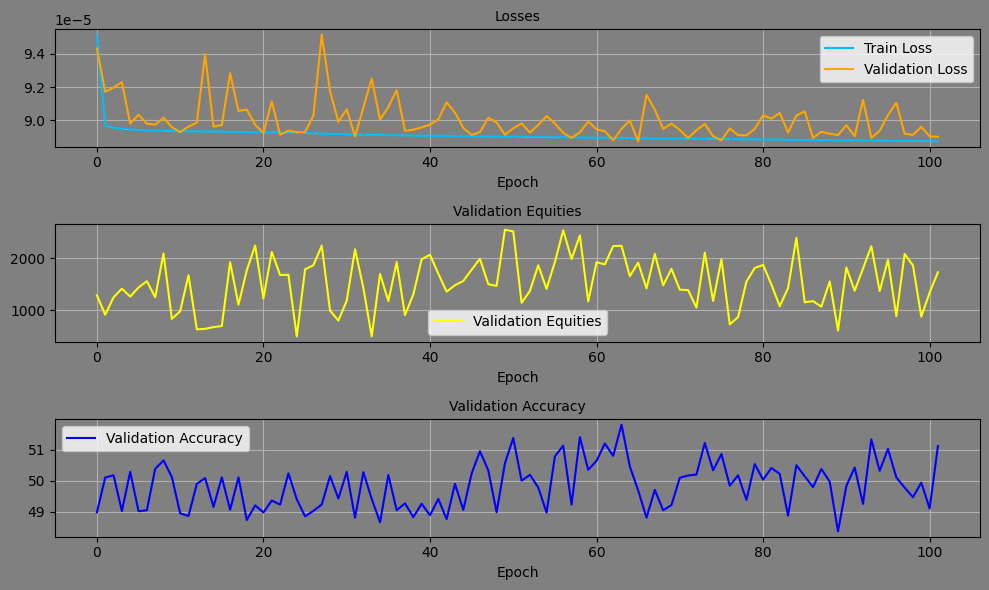

Epoch: 102, Val Equity: 1259.08, Val Accuracy: 48.93 train_losses: 0.00026821364031694037, val_losses: 8.967722533270717e-05, Duration: 0:01:49.802810


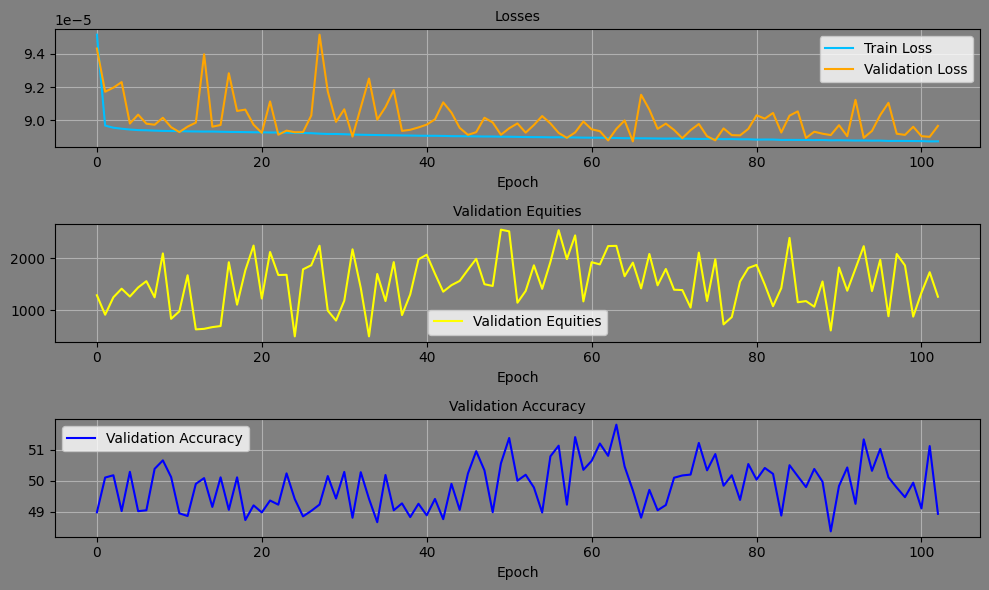

Epoch: 103, Val Equity: 1570.76, Val Accuracy: 49.72 train_losses: 0.0002681048602752289, val_losses: 8.939238614402711e-05, Duration: 0:01:50.858443


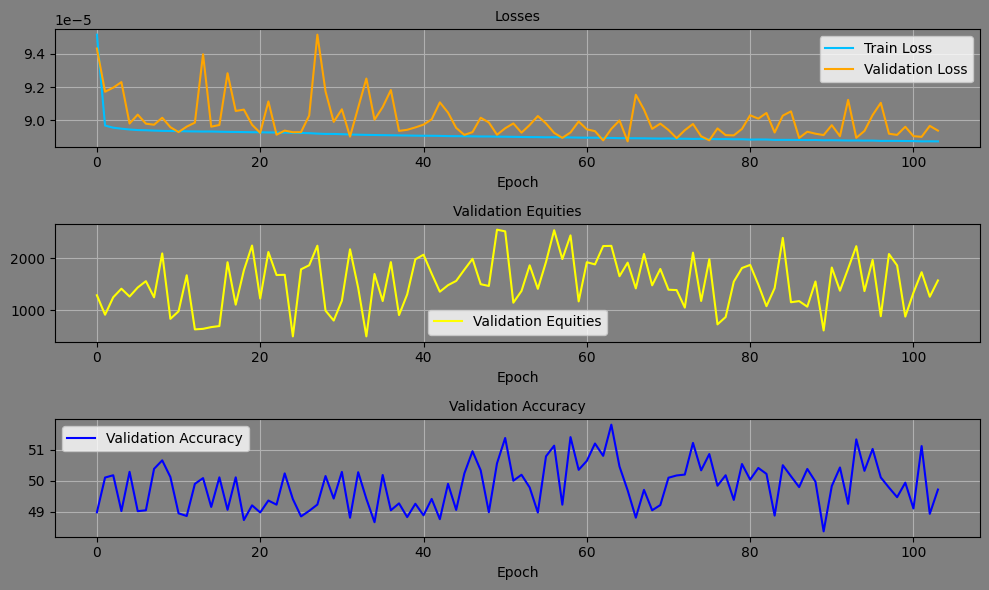

Epoch: 104, Val Equity: 1466.62, Val Accuracy: 50.39 train_losses: 0.00026779602182976645, val_losses: 9.003801096696407e-05, Duration: 0:01:49.993751


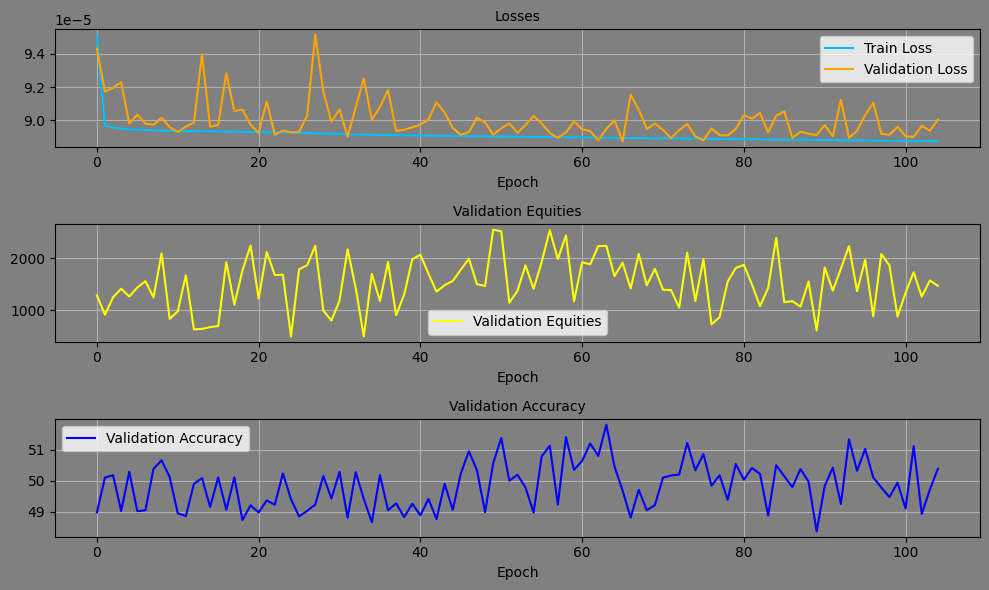

Epoch: 105, Val Equity: 1417.55, Val Accuracy: 49.07 train_losses: 0.0002677400627651035, val_losses: 8.914963837014511e-05, Duration: 0:01:51.142925


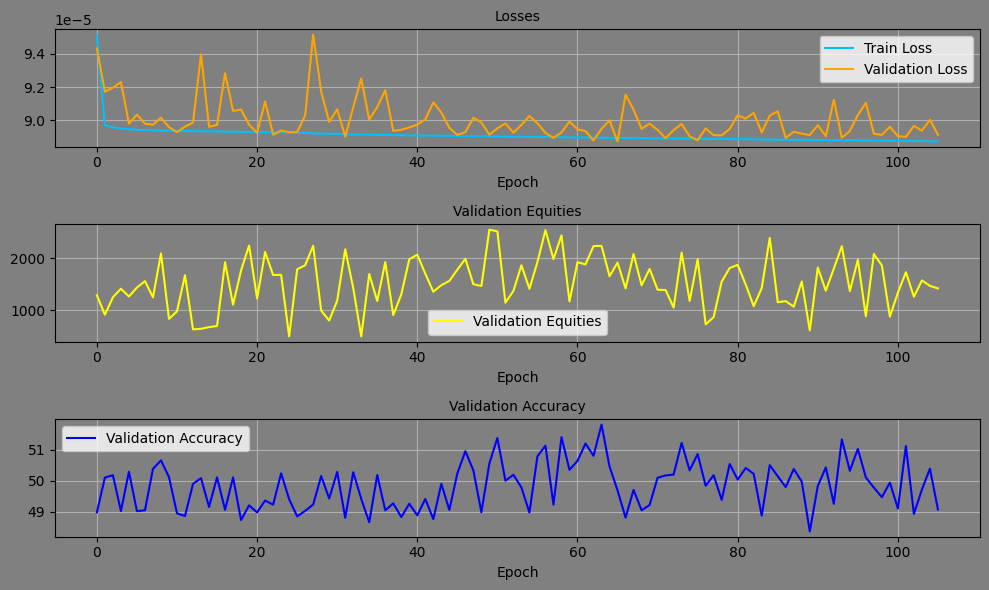

Epoch: 106, Val Equity: 1404.90, Val Accuracy: 49.05 train_losses: 0.00026783167103895184, val_losses: 8.934973448049277e-05, Duration: 0:01:49.961072


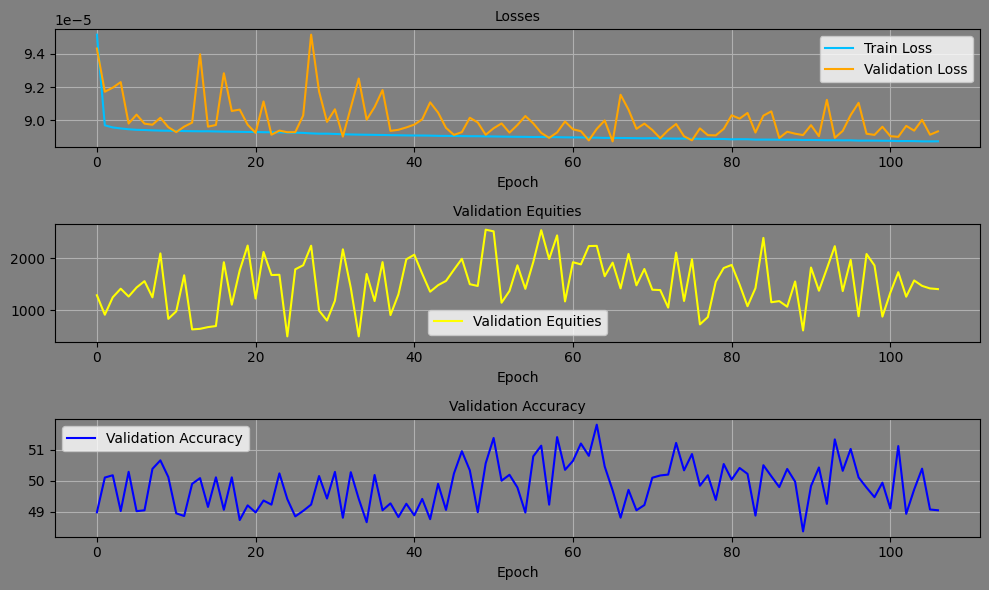

Epoch: 107, Val Equity: 1272.60, Val Accuracy: 50.24 train_losses: 0.0002677188852918867, val_losses: 9.019258868647739e-05, Duration: 0:01:51.117599


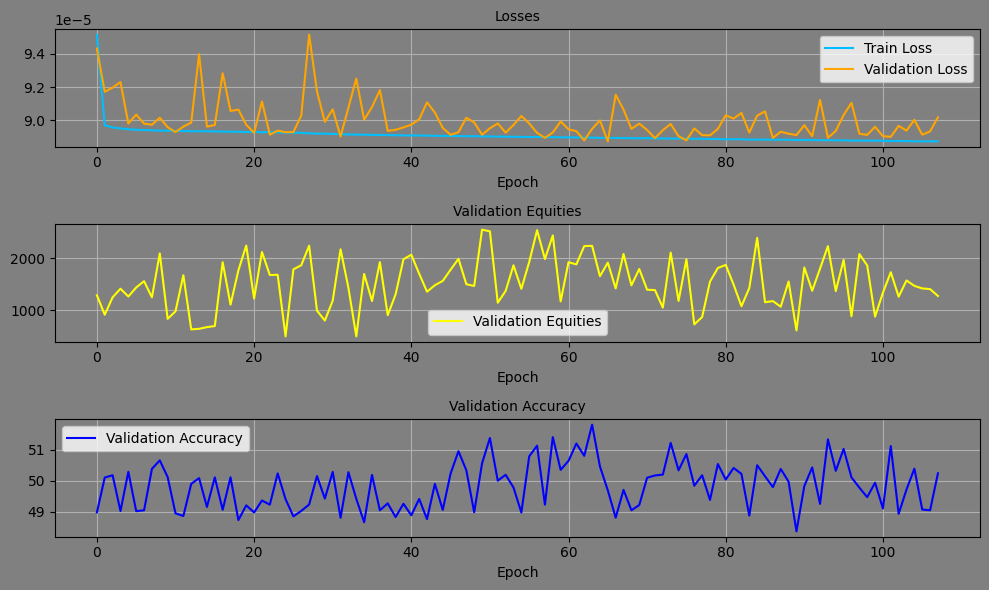

Epoch: 108, Val Equity: 1155.15, Val Accuracy: 50.21 train_losses: 0.0002675843202120994, val_losses: 8.975408127298579e-05, Duration: 0:01:53.226520


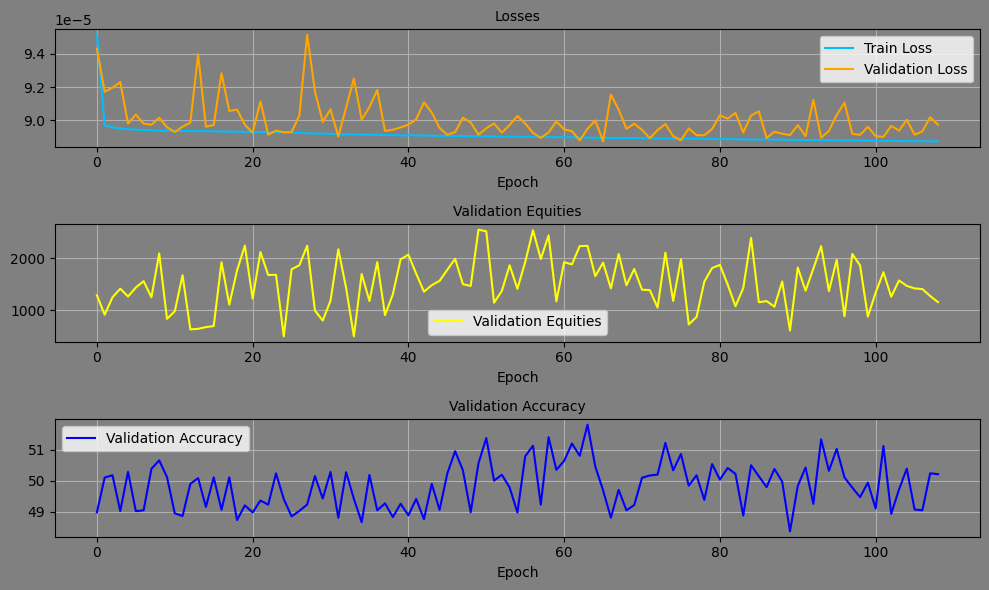

Epoch: 109, Val Equity: 2136.08, Val Accuracy: 50.95 train_losses: 0.0002673348935338357, val_losses: 8.995013195089996e-05, Duration: 0:01:54.261436


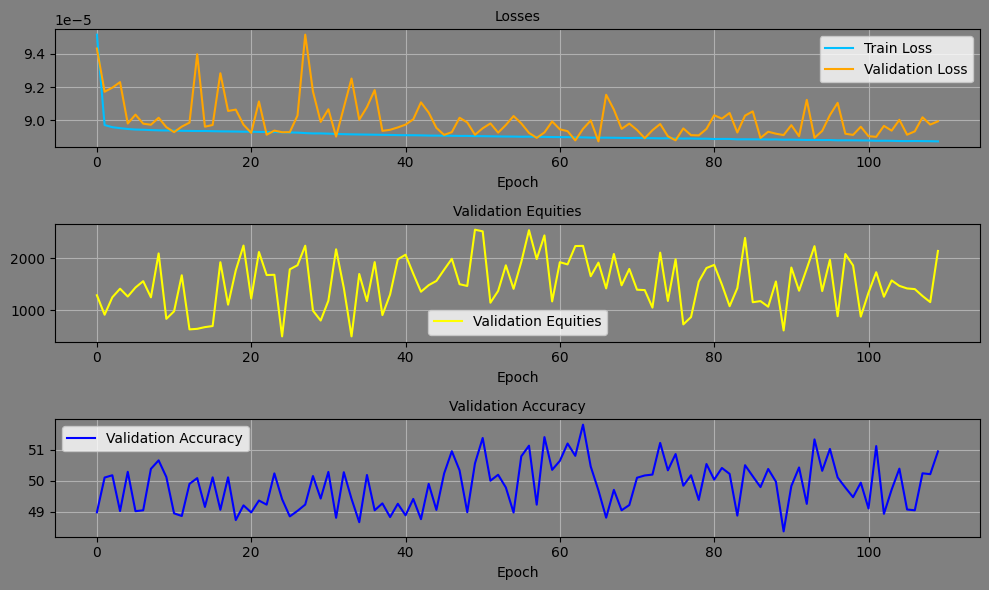

Epoch: 110, Val Equity: 2147.52, Val Accuracy: 50.12 train_losses: 0.0002671410418680737, val_losses: 9.242330270353705e-05, Duration: 0:01:51.653586


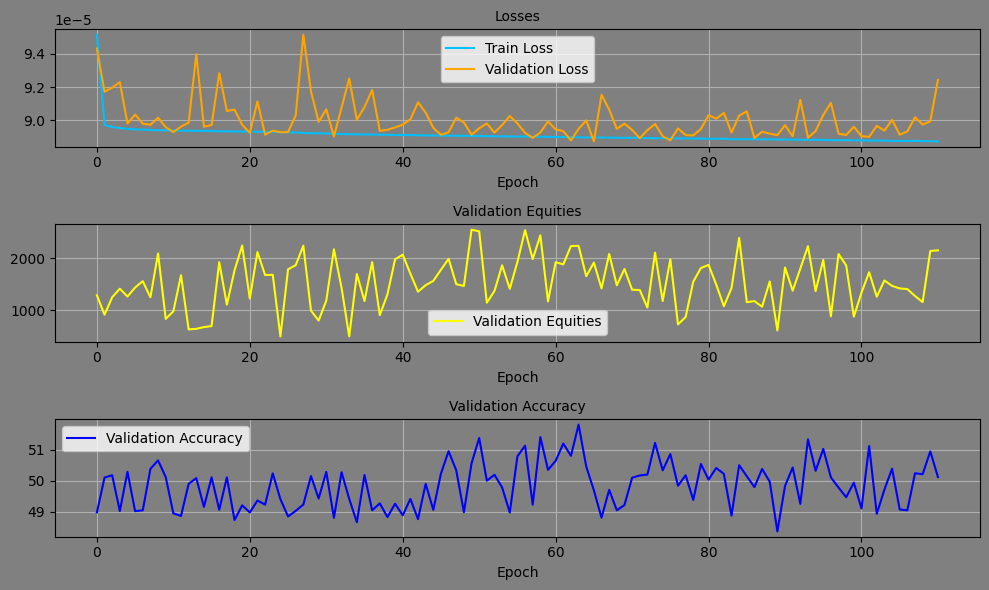

Epoch: 111, Val Equity: 828.70, Val Accuracy: 50.02 train_losses: 0.0002671815993322503, val_losses: 8.976081880973652e-05, Duration: 0:01:51.014032


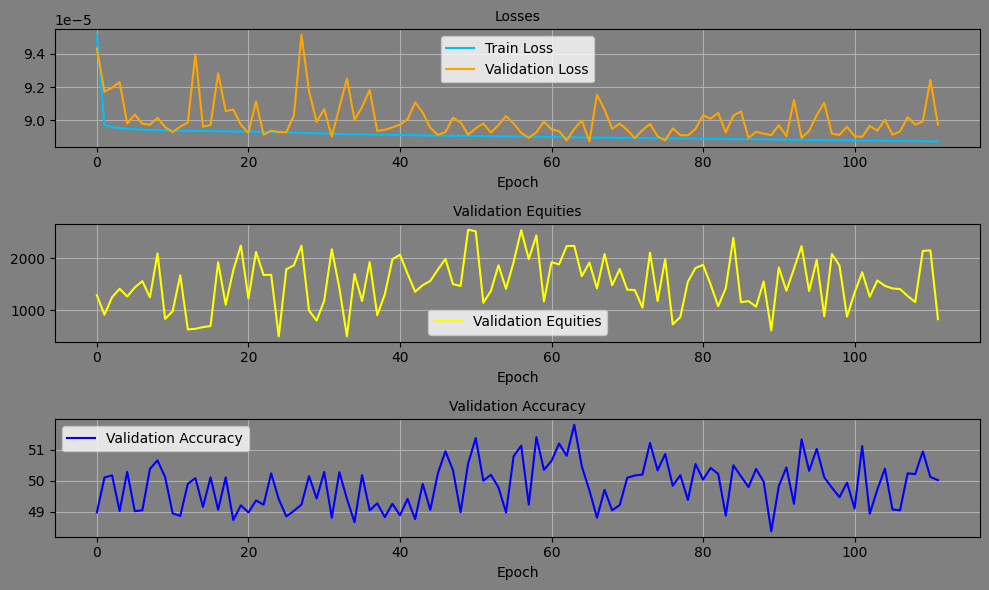

Epoch: 112, Val Equity: 1119.13, Val Accuracy: 50.23 train_losses: 0.0002670513406585782, val_losses: 9.013864473672584e-05, Duration: 0:01:50.896596


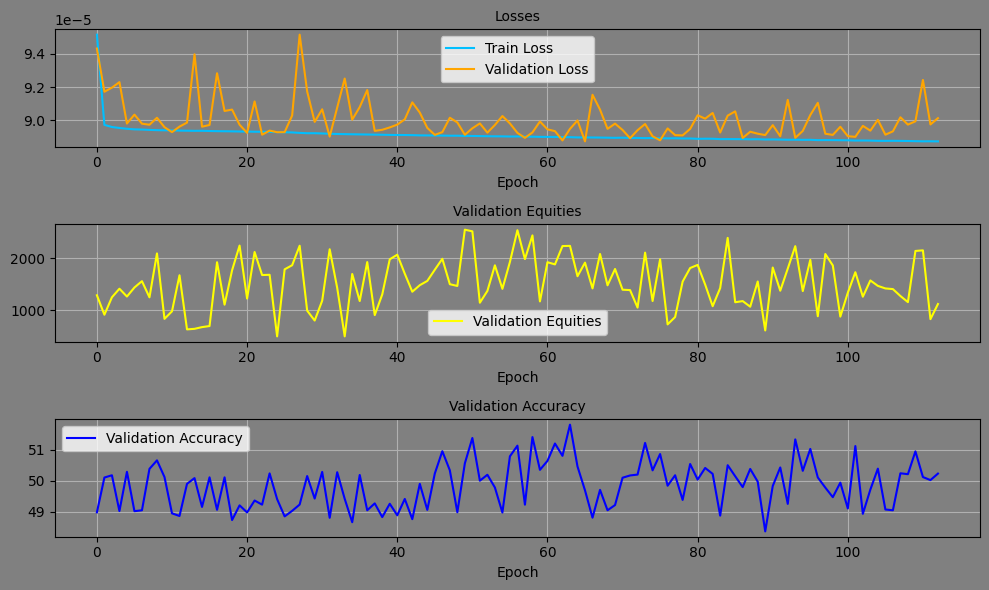

Epoch: 113, Val Equity: 1036.81, Val Accuracy: 50.28 train_losses: 0.00026696180111916023, val_losses: 9.112149564316496e-05, Duration: 0:01:51.325695


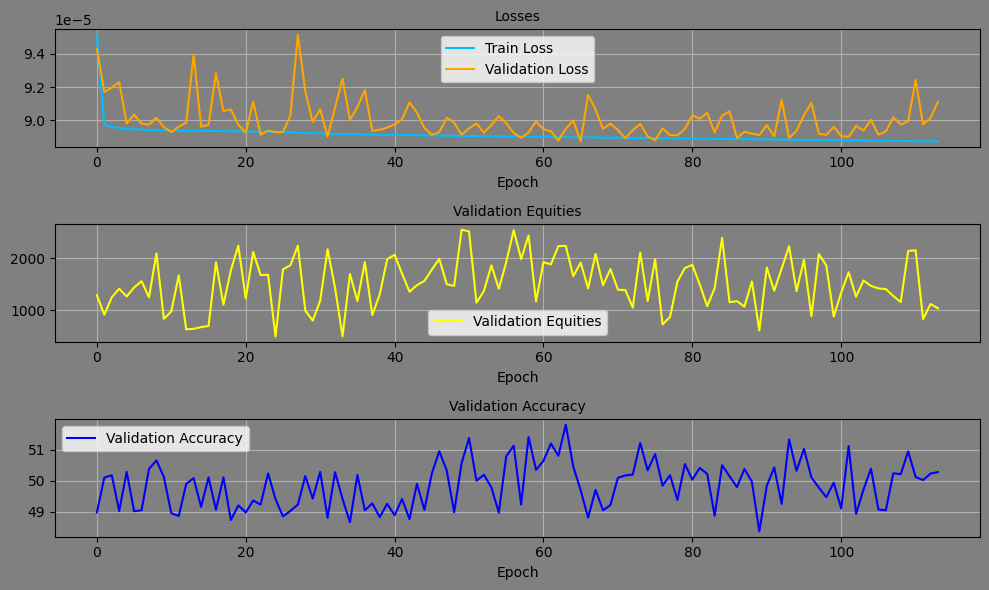

Epoch: 114, Val Equity: 1476.72, Val Accuracy: 49.49 train_losses: 0.00026678851698610134, val_losses: 8.890838216757402e-05, Duration: 0:01:53.787634


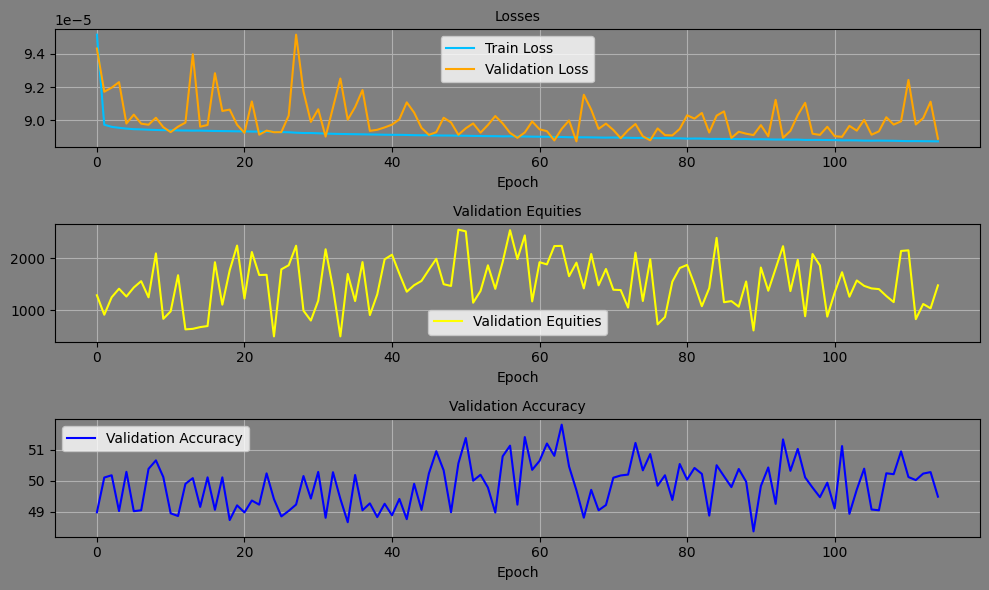

Epoch: 115, Val Equity: 1954.70, Val Accuracy: 50.35 train_losses: 0.00026678086112728183, val_losses: 8.909530879464e-05, Duration: 0:01:51.037394


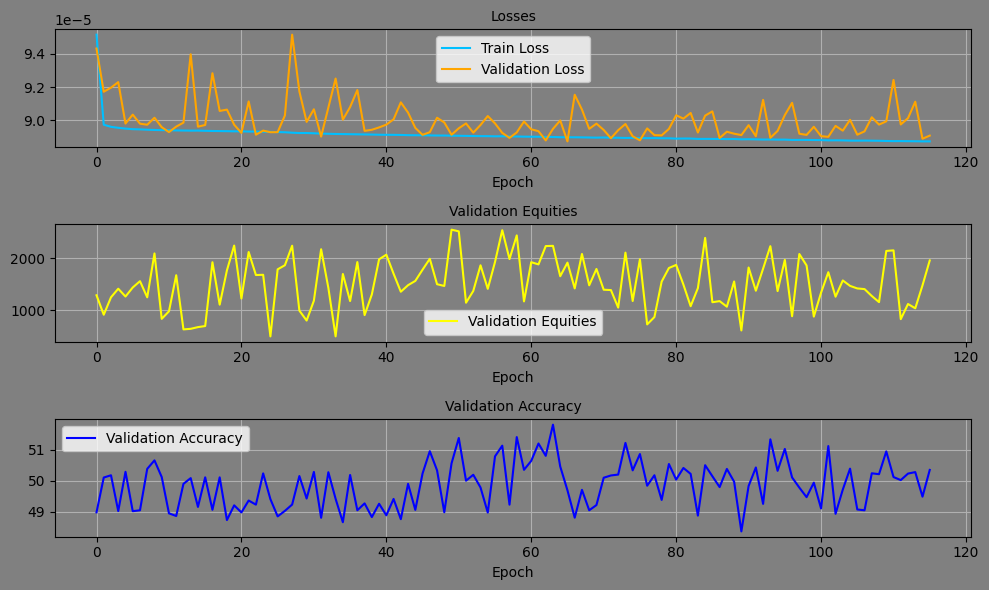

Epoch: 116, Val Equity: 1218.45, Val Accuracy: 51.15 train_losses: 0.0002665666610833034, val_losses: 9.10283561097458e-05, Duration: 0:01:54.968967


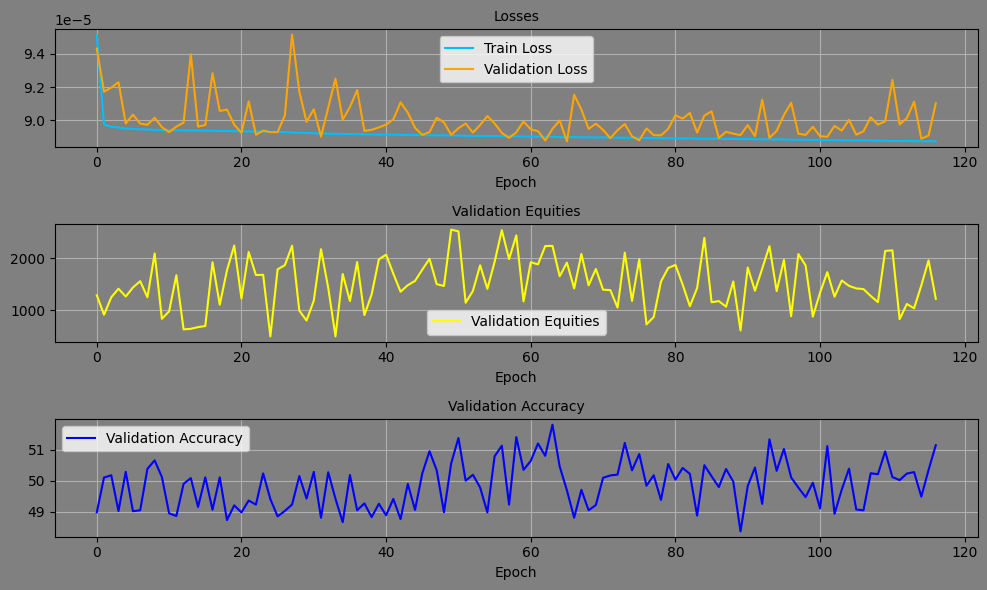

Epoch: 117, Val Equity: 1504.72, Val Accuracy: 49.03 train_losses: 0.0002665889302325309, val_losses: 8.90498049557209e-05, Duration: 0:01:52.305530


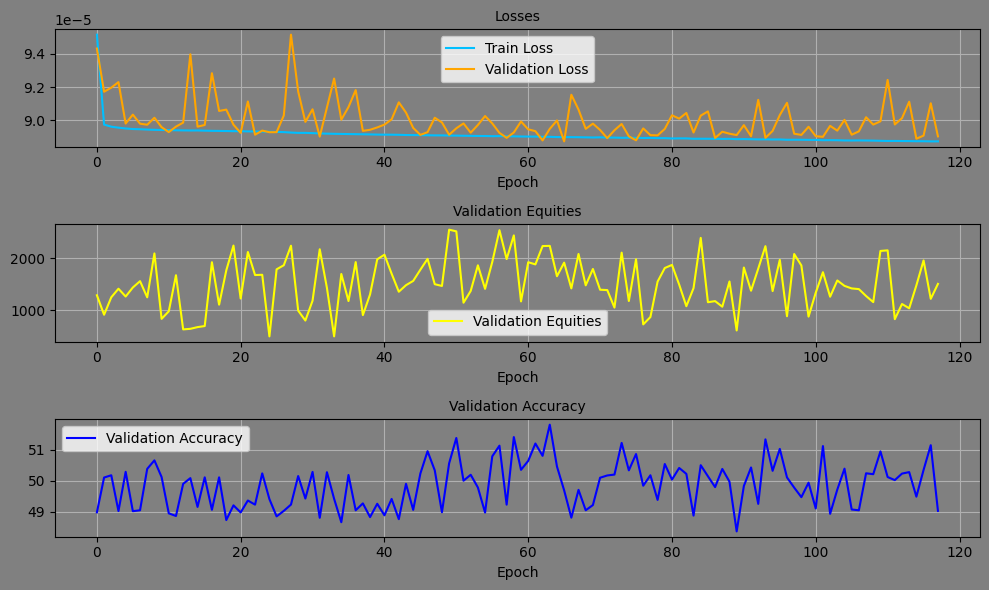

Epoch: 118, Val Equity: 988.78, Val Accuracy: 50.17 train_losses: 0.00026639924355015504, val_losses: 8.961557614384219e-05, Duration: 0:01:51.788482


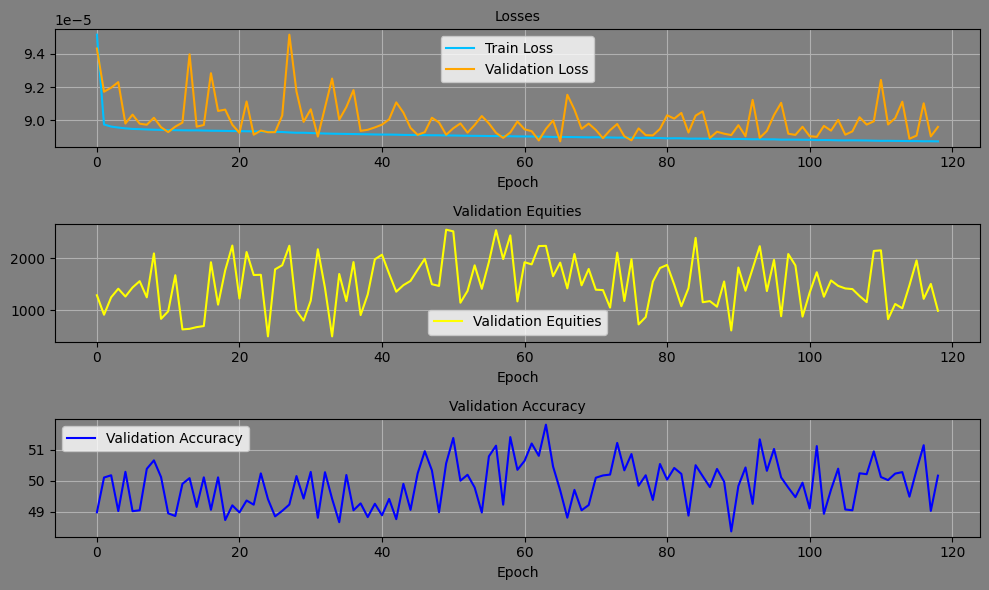

Epoch: 119, Val Equity: 555.79, Val Accuracy: 48.71 train_losses: 0.00026621830374636826, val_losses: 8.912786142900586e-05, Duration: 0:01:52.157141


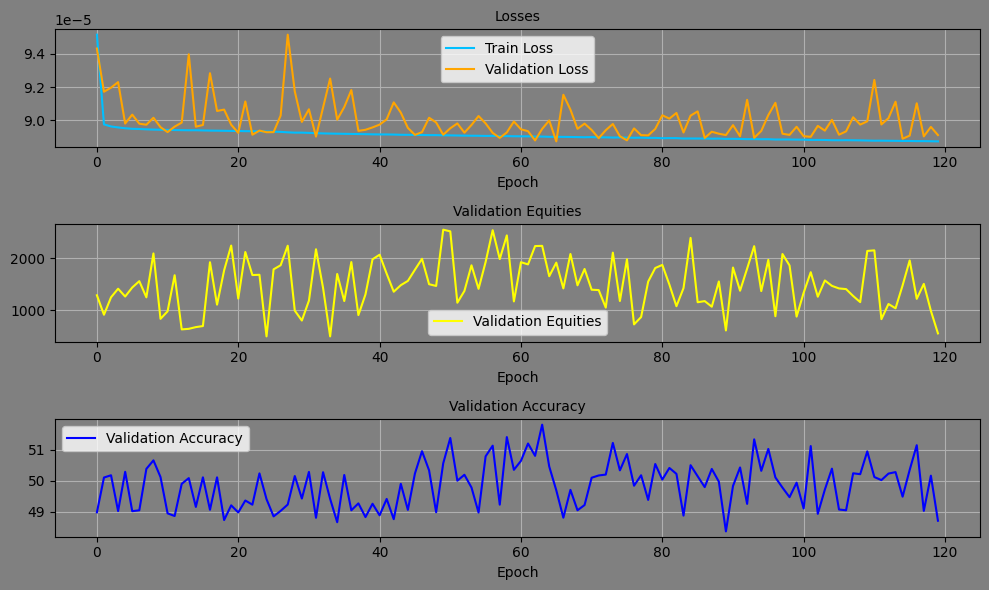

Epoch: 120, Val Equity: 1140.13, Val Accuracy: 50.39 train_losses: 0.0002662823790460866, val_losses: 8.963295113062486e-05, Duration: 0:01:50.134732


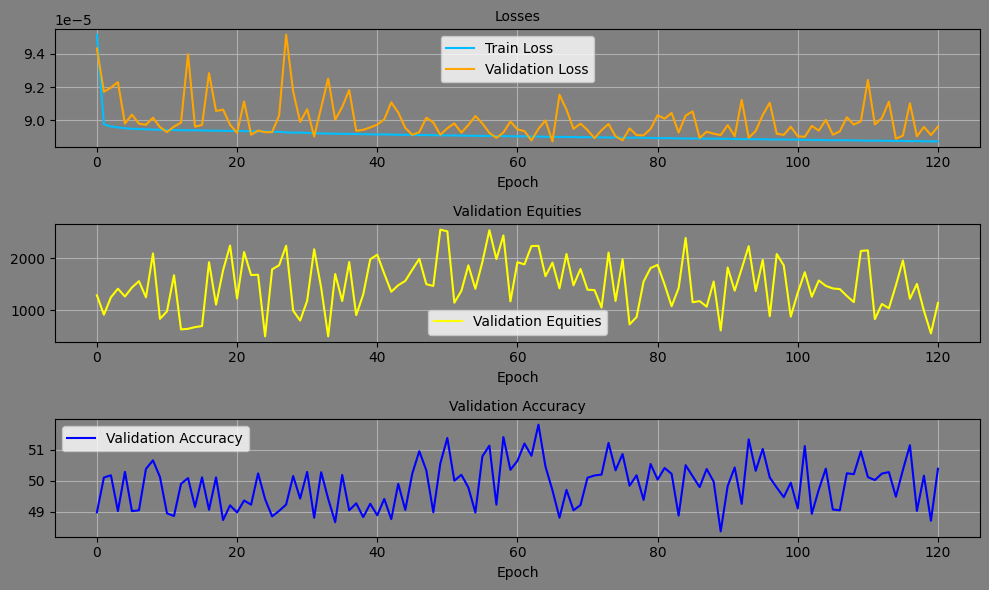

Epoch: 121, Val Equity: 1794.31, Val Accuracy: 50.46 train_losses: 0.0002662073919020621, val_losses: 8.893662743503228e-05, Duration: 0:01:51.399977


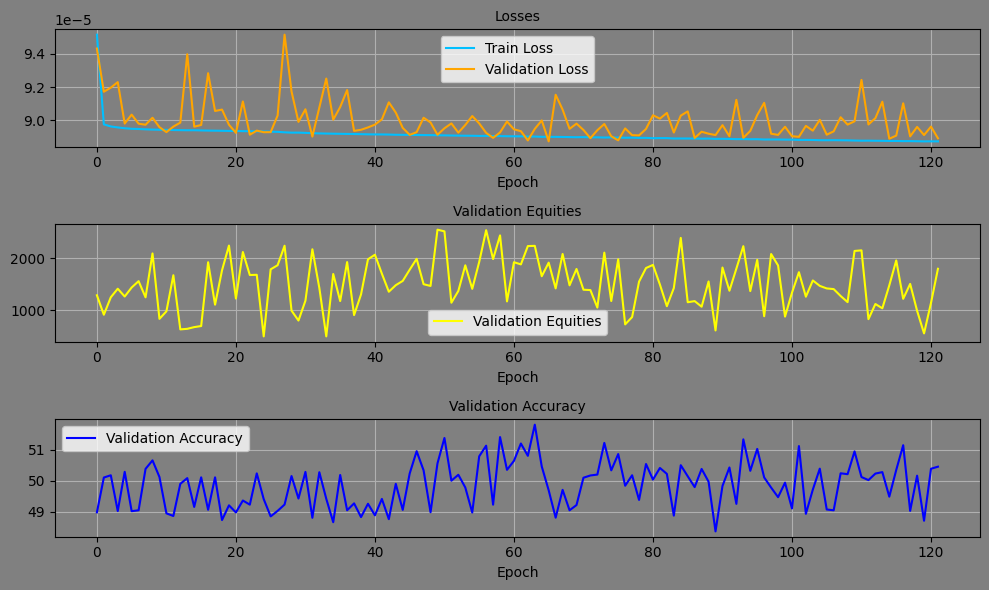

Epoch: 122, Val Equity: 1925.55, Val Accuracy: 51.01 train_losses: 0.00026603676917232857, val_losses: 8.907403389457613e-05, Duration: 0:01:55.518848


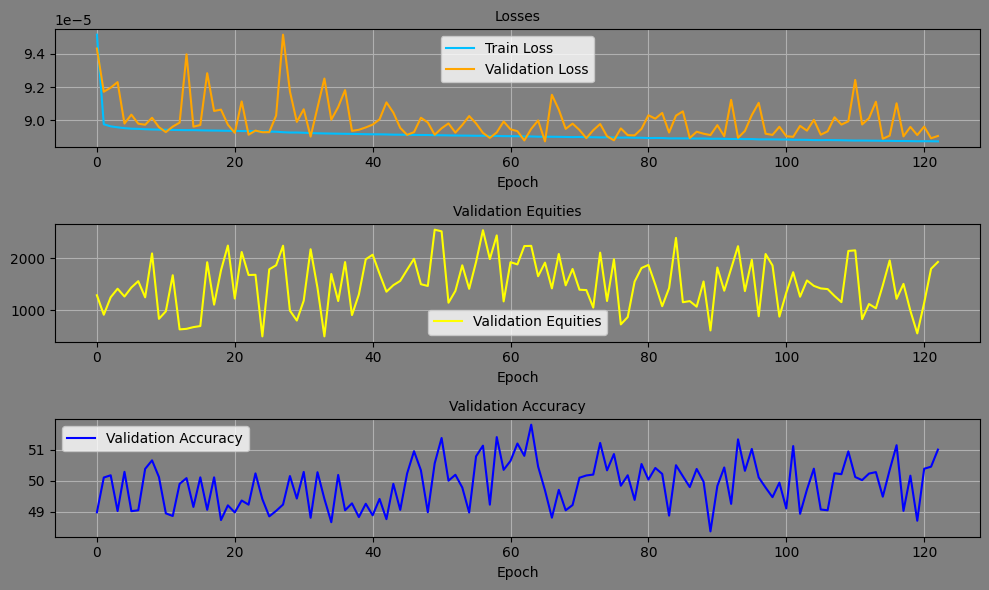

Epoch: 123, Val Equity: 1372.97, Val Accuracy: 50.22 train_losses: 0.0002658989023180633, val_losses: 8.97236168384552e-05, Duration: 0:01:50.108119


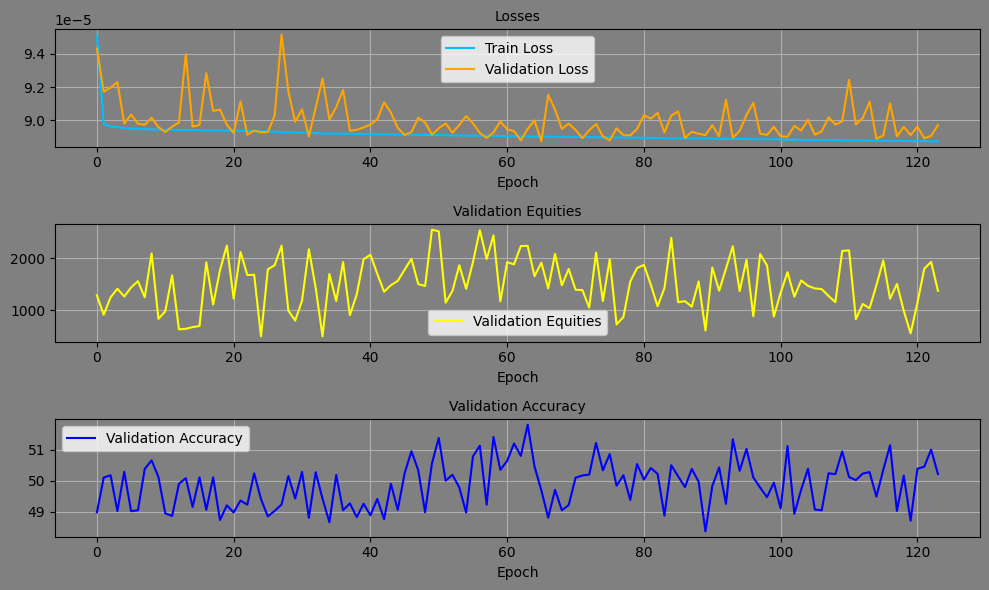

Epoch: 124, Val Equity: 1470.12, Val Accuracy: 48.97 train_losses: 0.0002656942831791876, val_losses: 8.94616314326413e-05, Duration: 0:01:50.142959


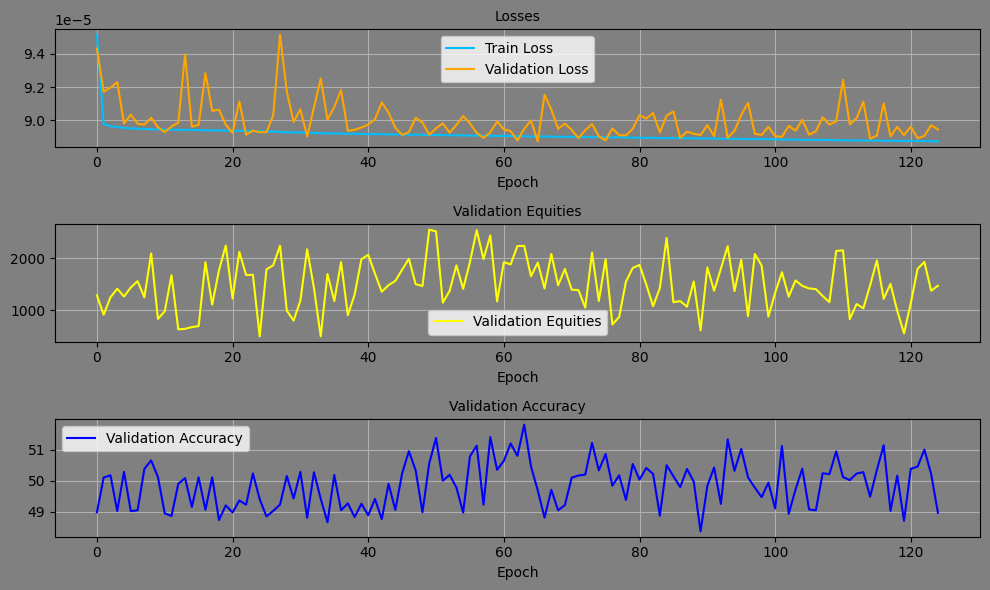

Epoch: 125, Val Equity: 1598.61, Val Accuracy: 50.46 train_losses: 0.00026562304030099636, val_losses: 8.942114072851837e-05, Duration: 0:01:51.680325


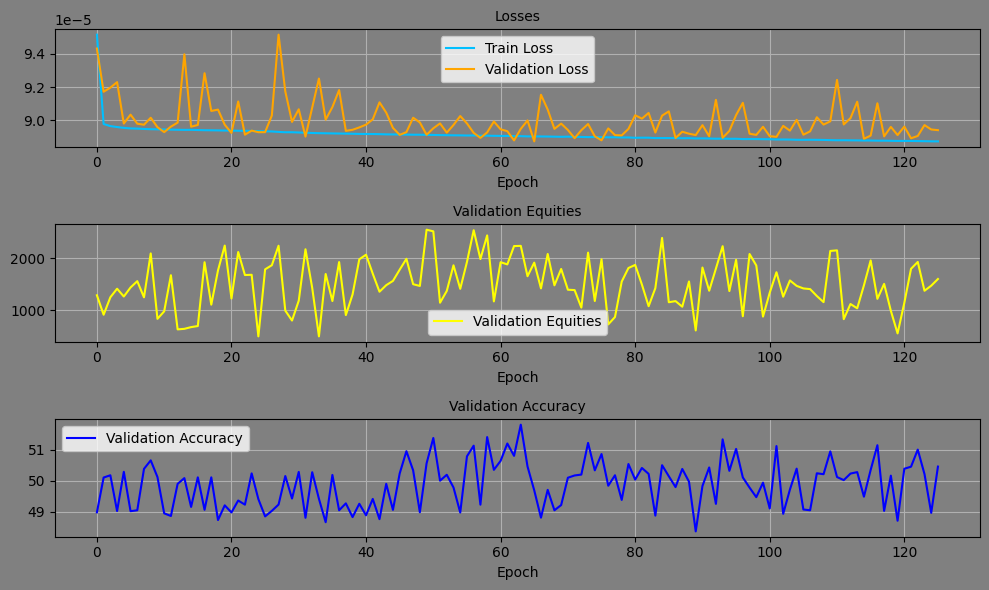

Epoch: 126, Val Equity: 1138.10, Val Accuracy: 50.34 train_losses: 0.0002653942974247209, val_losses: 8.917378727346659e-05, Duration: 0:01:49.649084


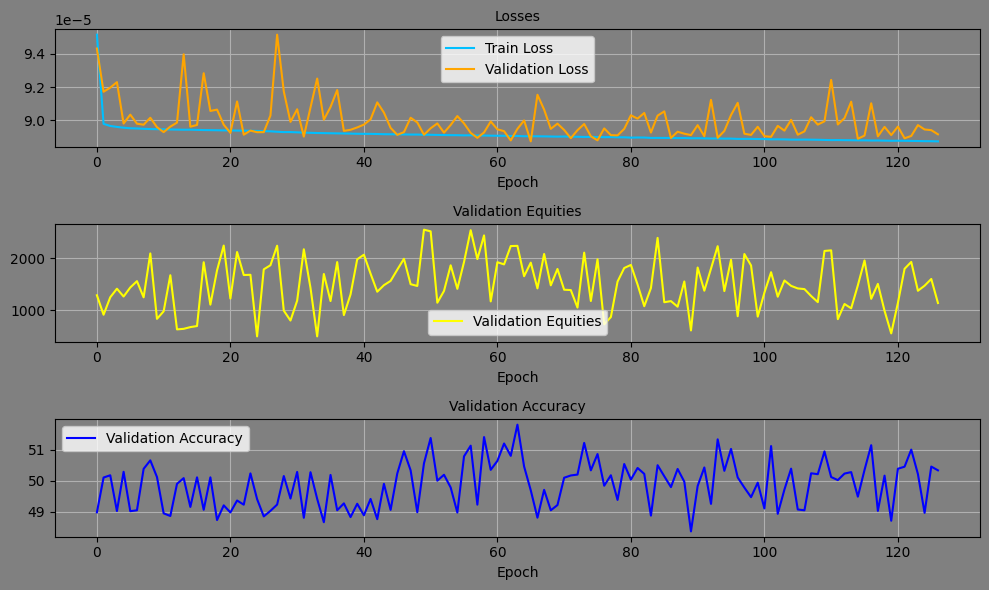

Epoch: 127, Val Equity: 2193.84, Val Accuracy: 50.29 train_losses: 0.00026561710080194297, val_losses: 8.917101513361558e-05, Duration: 0:01:50.903823


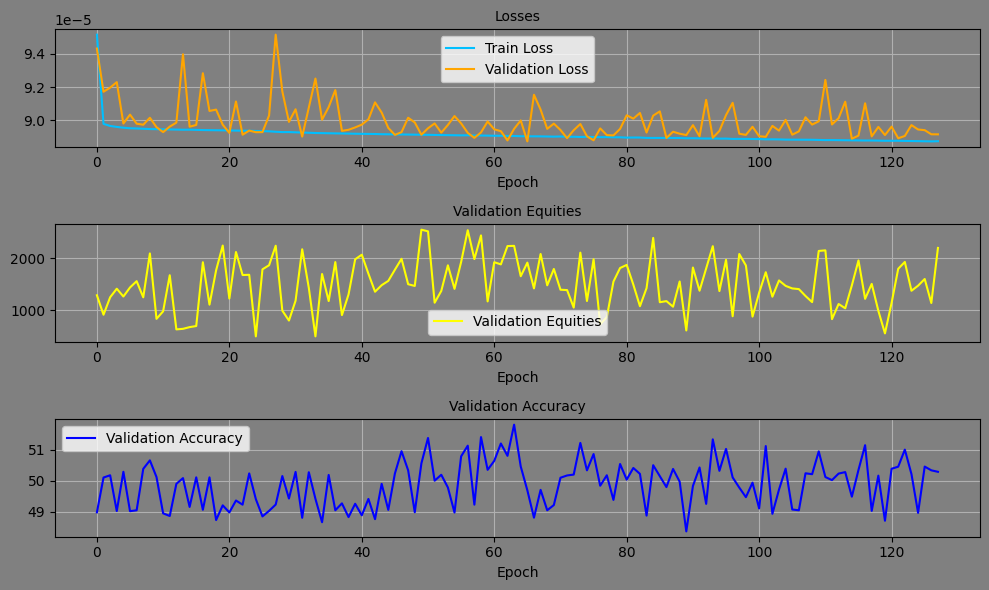

Epoch: 128, Val Equity: 1310.28, Val Accuracy: 50.37 train_losses: 0.0002653390866556045, val_losses: 9.188727563014254e-05, Duration: 0:01:50.541977


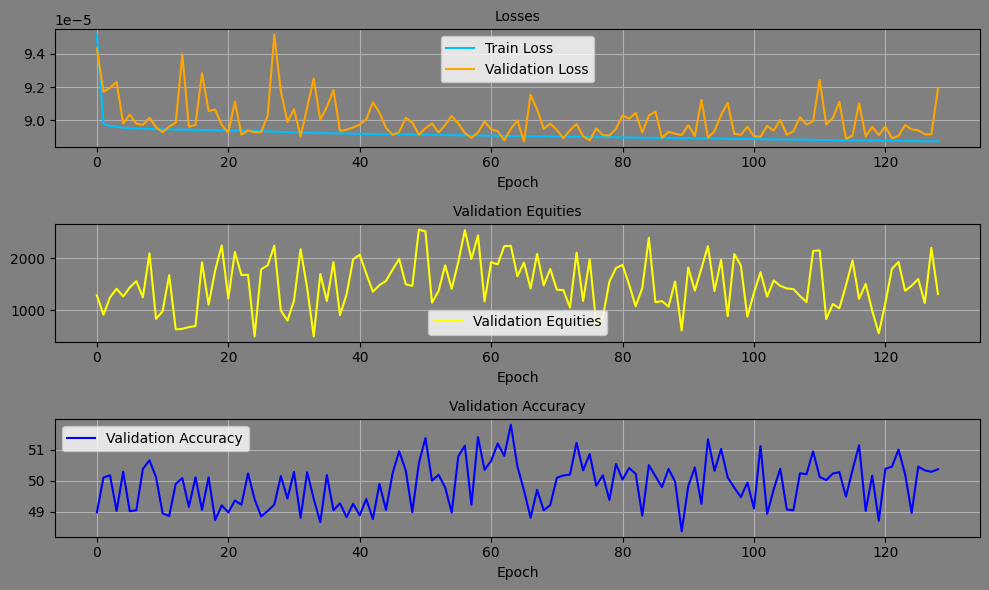

Epoch: 129, Val Equity: 2017.98, Val Accuracy: 49.40 train_losses: 0.00026520170998478495, val_losses: 8.88757494976744e-05, Duration: 0:01:50.895545


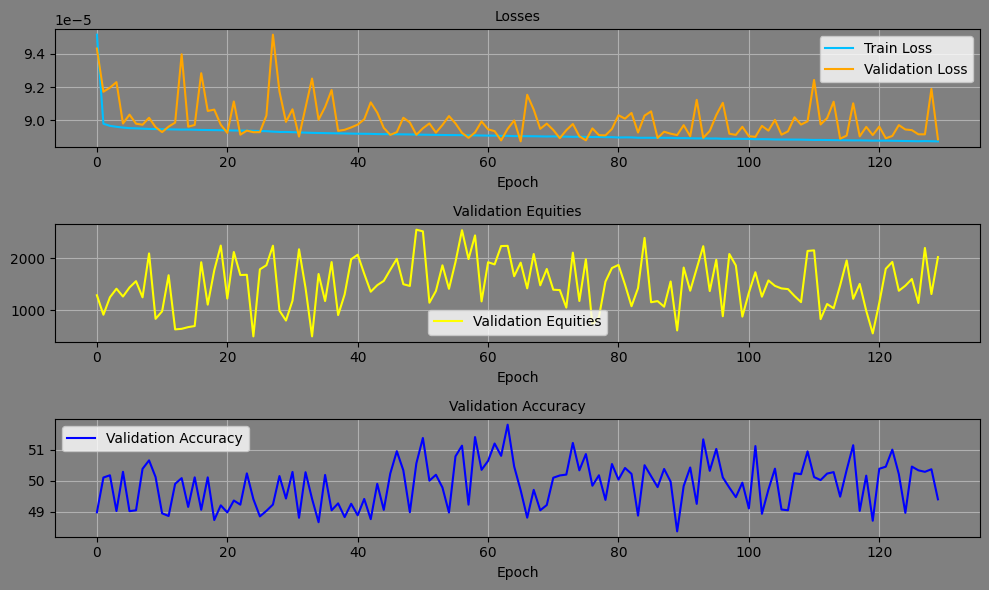

Epoch: 130, Val Equity: 1811.12, Val Accuracy: 49.16 train_losses: 0.0002652499517530598, val_losses: 8.940172119764611e-05, Duration: 0:01:51.499994


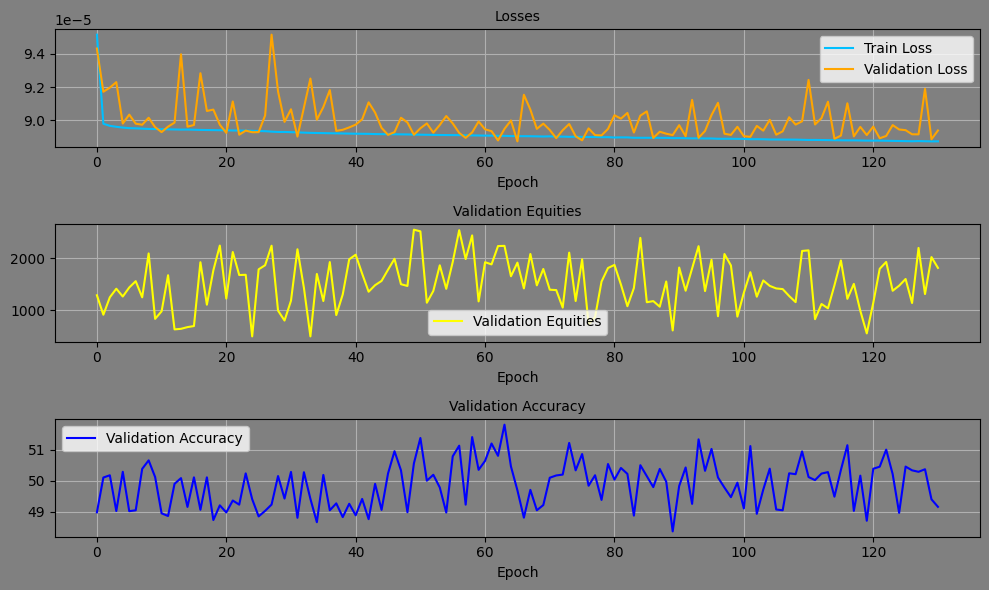

Epoch: 131, Val Equity: 1474.34, Val Accuracy: 50.96 train_losses: 0.00026487249415571183, val_losses: 9.059120202437043e-05, Duration: 0:01:50.493236


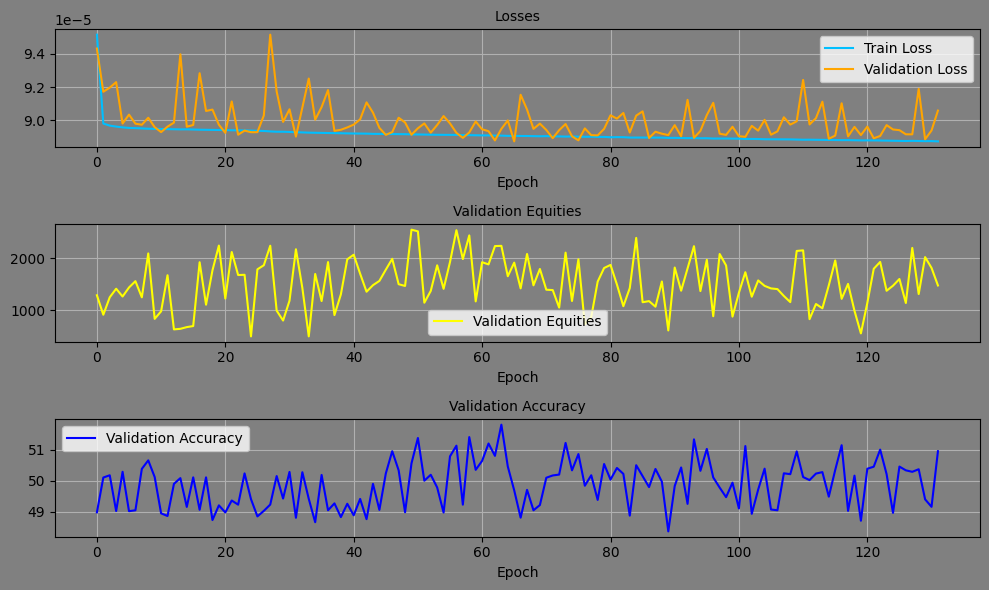

Epoch: 132, Val Equity: 1934.22, Val Accuracy: 50.78 train_losses: 0.00026474038174882945, val_losses: 9.155541920335963e-05, Duration: 0:01:52.758624


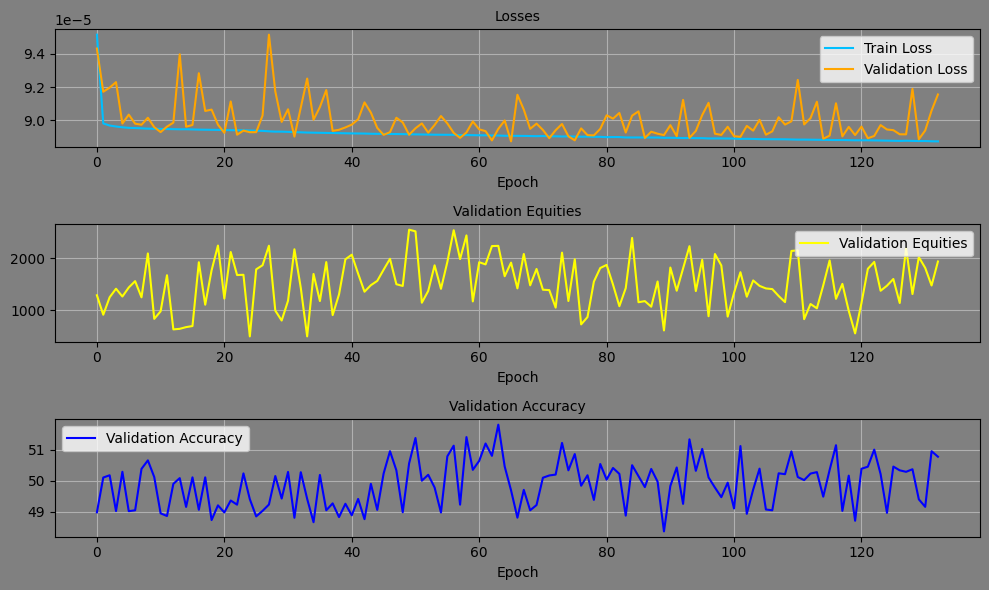

Epoch: 133, Val Equity: 1985.62, Val Accuracy: 49.31 train_losses: 0.0002646397453915368, val_losses: 8.922915731091052e-05, Duration: 0:01:49.778897


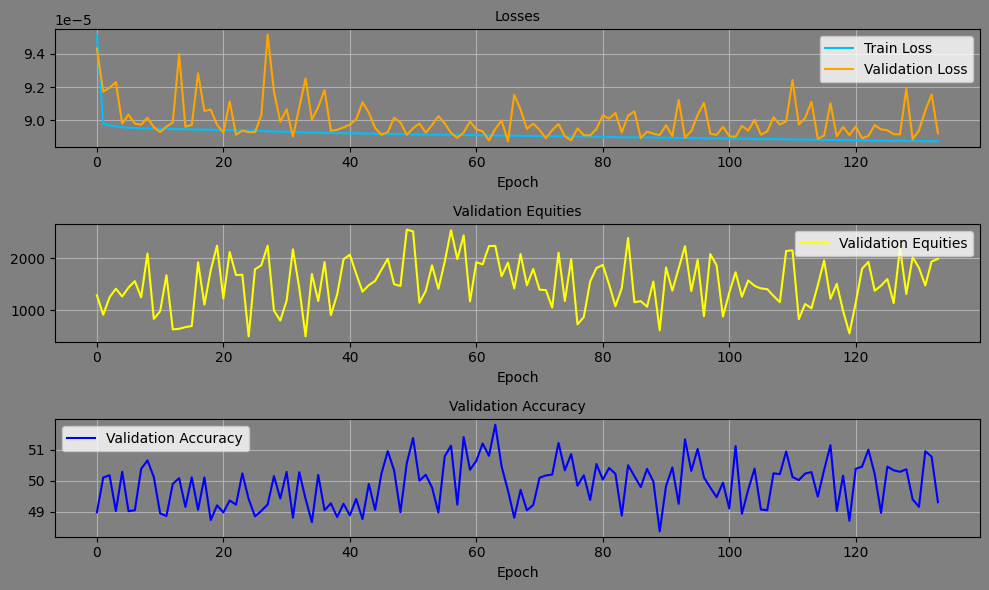

Epoch: 134, Val Equity: 1477.44, Val Accuracy: 50.46 train_losses: 0.000264851692963283, val_losses: 8.934809739002958e-05, Duration: 0:01:49.532392


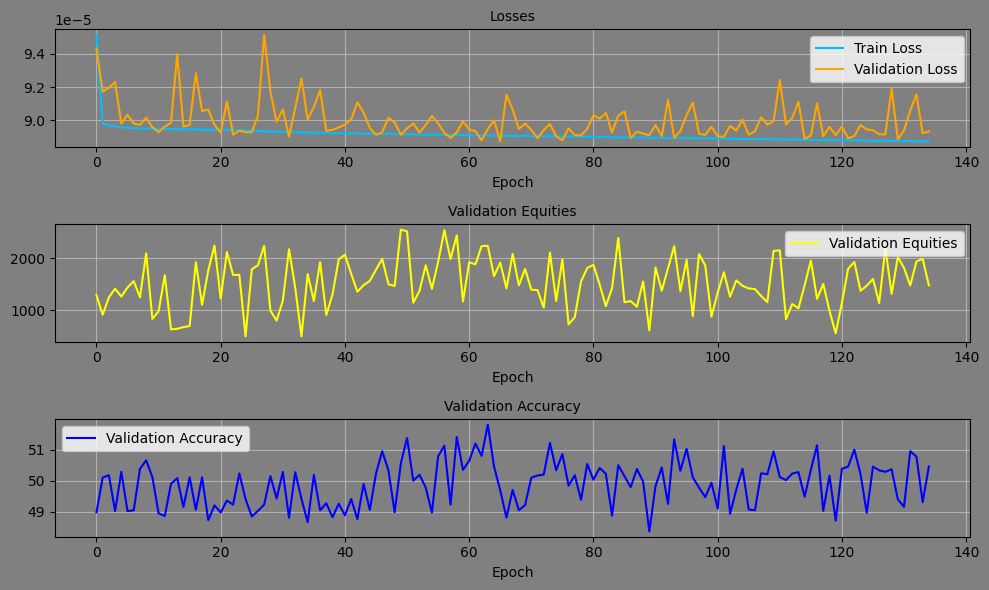

Epoch: 135, Val Equity: 1513.96, Val Accuracy: 50.38 train_losses: 0.00026448647238561443, val_losses: 8.899607200874016e-05, Duration: 0:01:50.862394


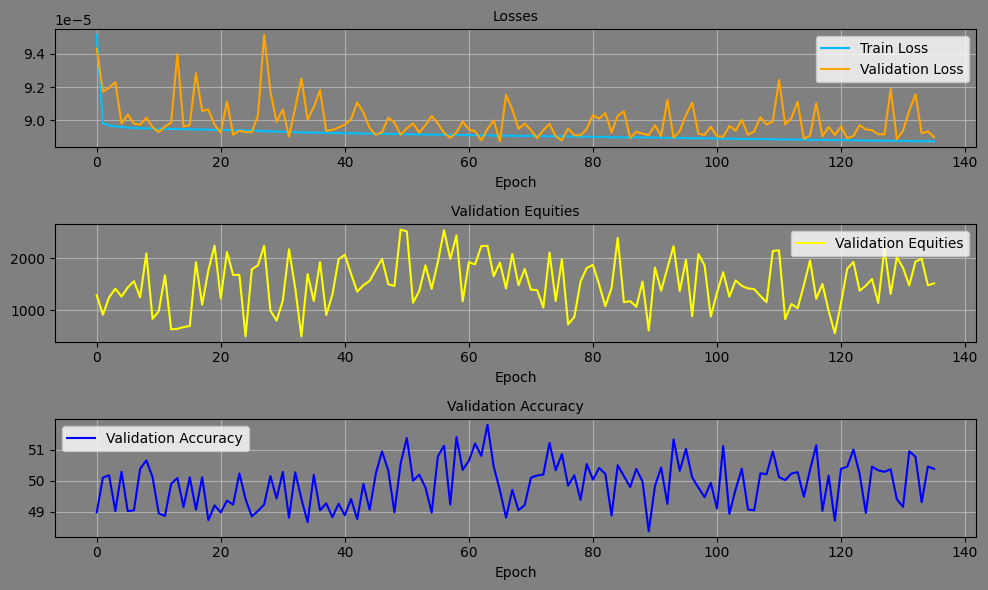

Epoch: 136, Val Equity: 2167.04, Val Accuracy: 49.75 train_losses: 0.0002645536492388039, val_losses: 8.911384793464094e-05, Duration: 0:01:50.674330


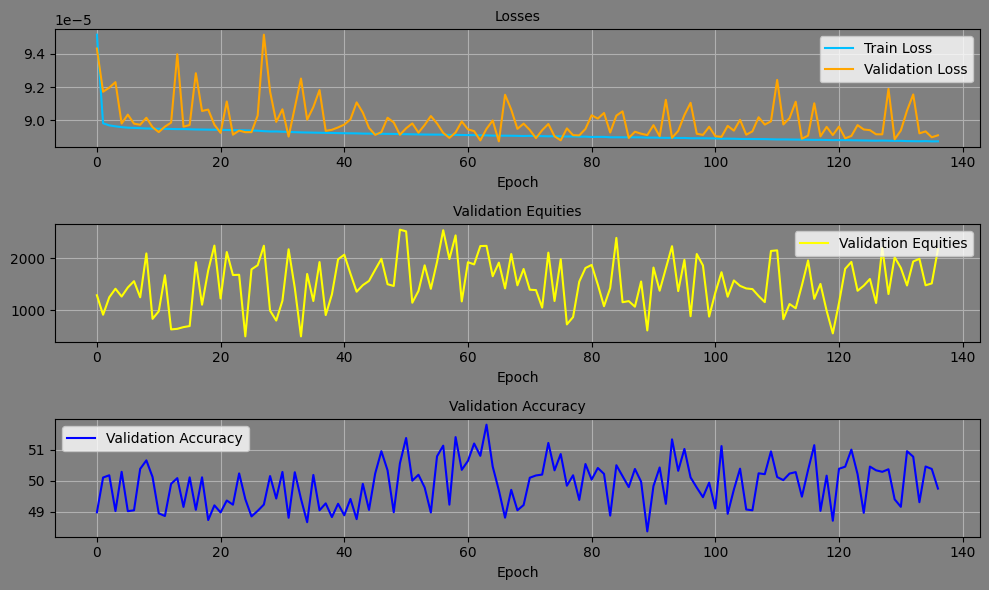

Epoch: 137, Val Equity: 1931.09, Val Accuracy: 50.27 train_losses: 0.0002642310581113708, val_losses: 8.990739297587425e-05, Duration: 0:01:49.520137


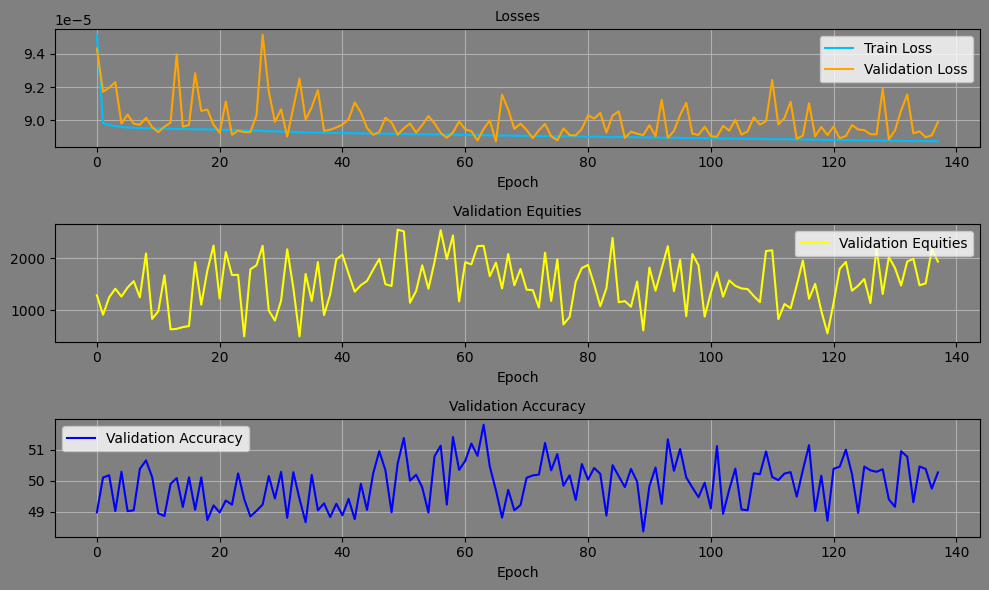

Epoch: 138, Val Equity: 1043.04, Val Accuracy: 48.78 train_losses: 0.00026393297371427016, val_losses: 9.006692562252283e-05, Duration: 0:01:48.581358


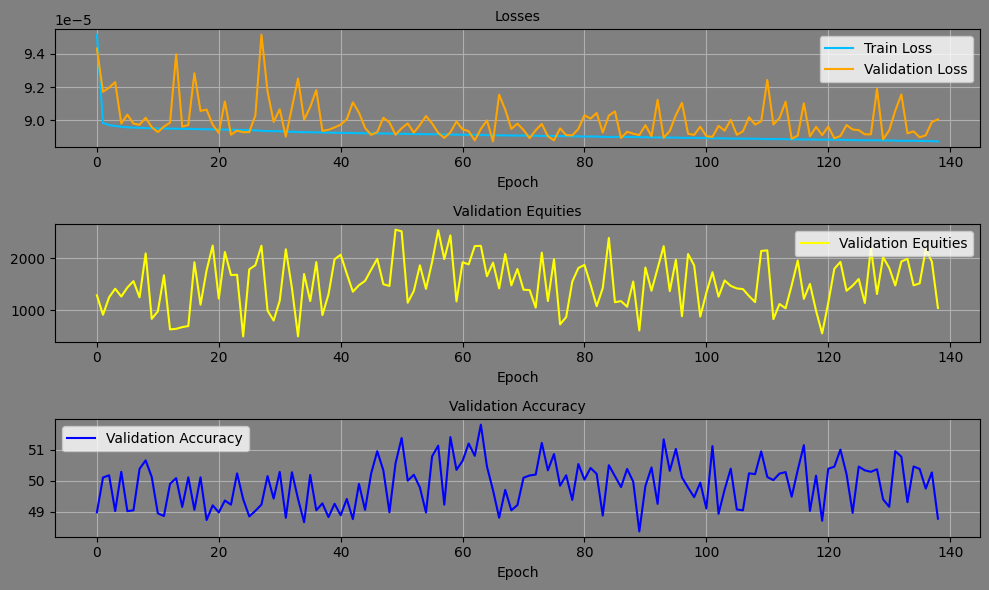

Epoch: 139, Val Equity: 1748.72, Val Accuracy: 50.42 train_losses: 0.00026430056218819896, val_losses: 8.897140651242808e-05, Duration: 0:01:49.755514


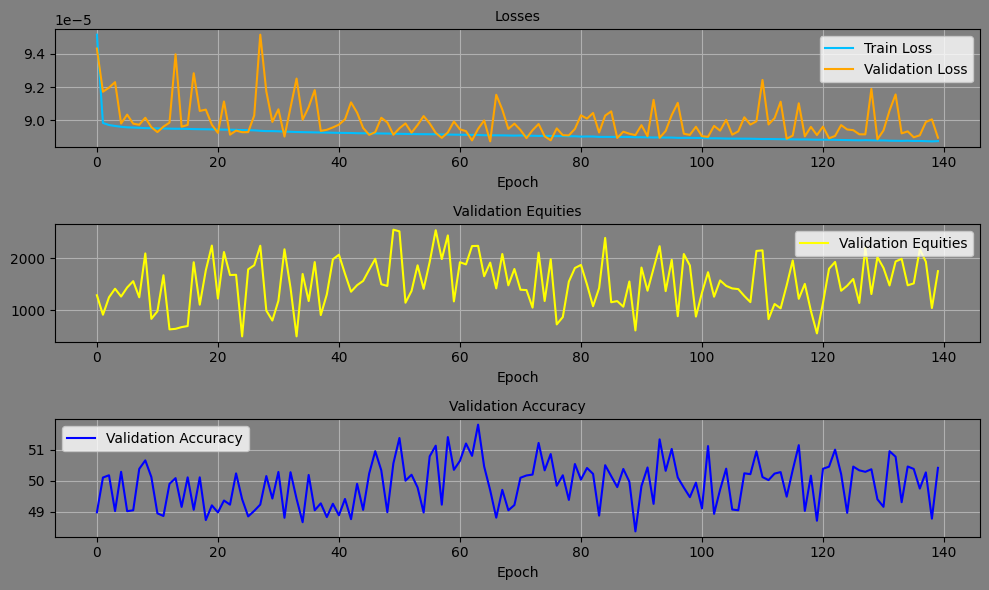

Epoch: 140, Val Equity: 2035.05, Val Accuracy: 49.96 train_losses: 0.00026423881995728656, val_losses: 8.898253145162016e-05, Duration: 0:01:50.203225


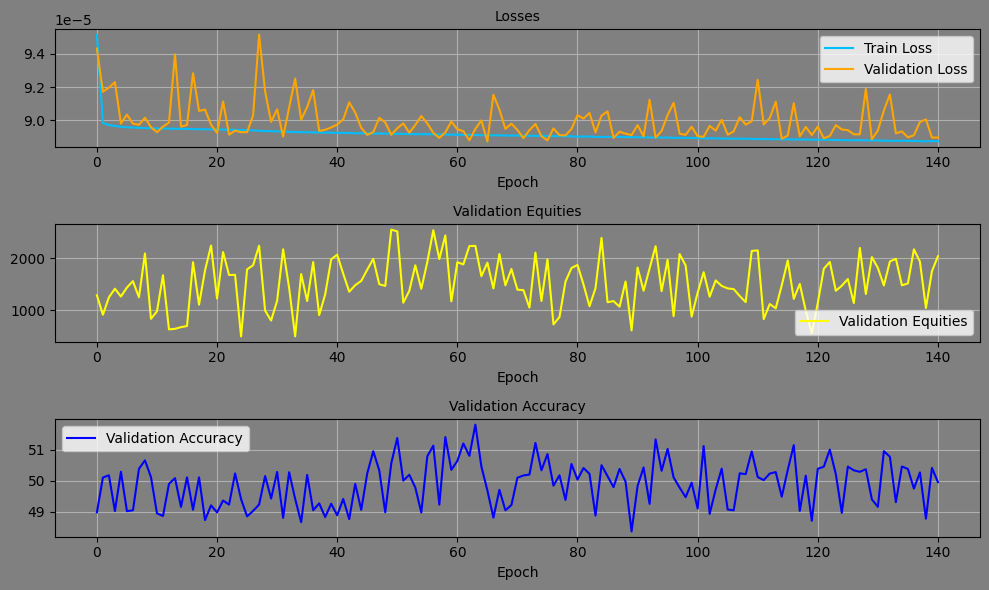

Epoch: 141, Val Equity: 1623.41, Val Accuracy: 49.52 train_losses: 0.0002639020711519255, val_losses: 8.964565495261922e-05, Duration: 0:01:50.320153


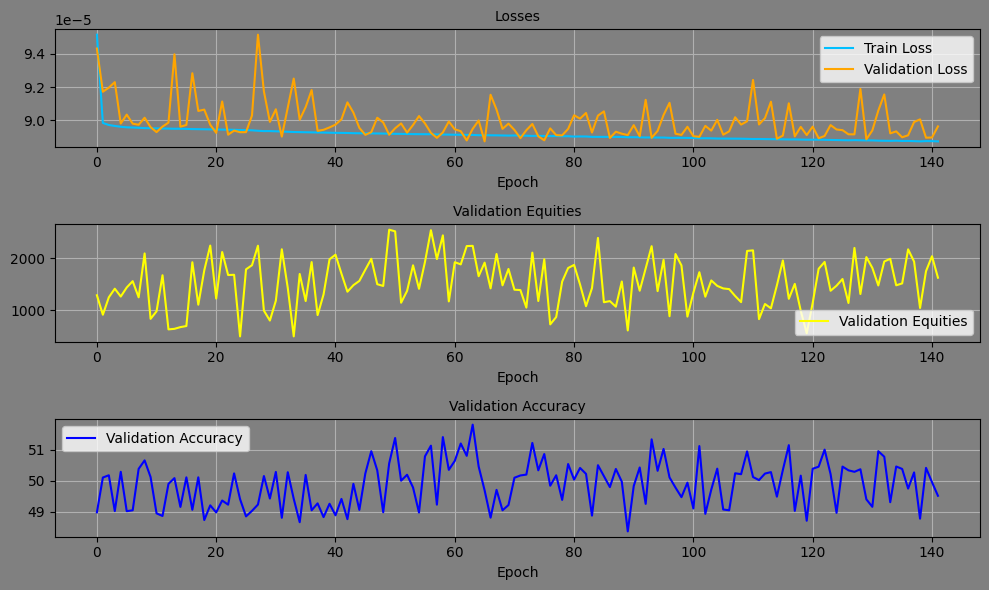

Epoch: 142, Val Equity: 1141.03, Val Accuracy: 49.50 train_losses: 0.00026342253773336557, val_losses: 8.962601714301854e-05, Duration: 0:01:50.780712


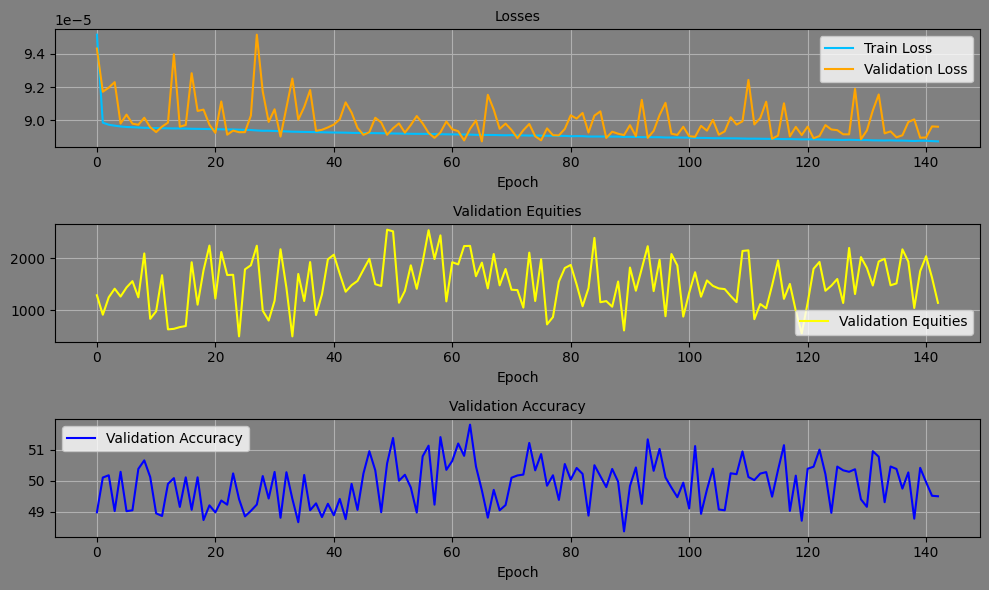

Epoch: 143, Val Equity: 1715.30, Val Accuracy: 50.90 train_losses: 0.00026380057438353, val_losses: 8.912989142118022e-05, Duration: 0:01:52.486673


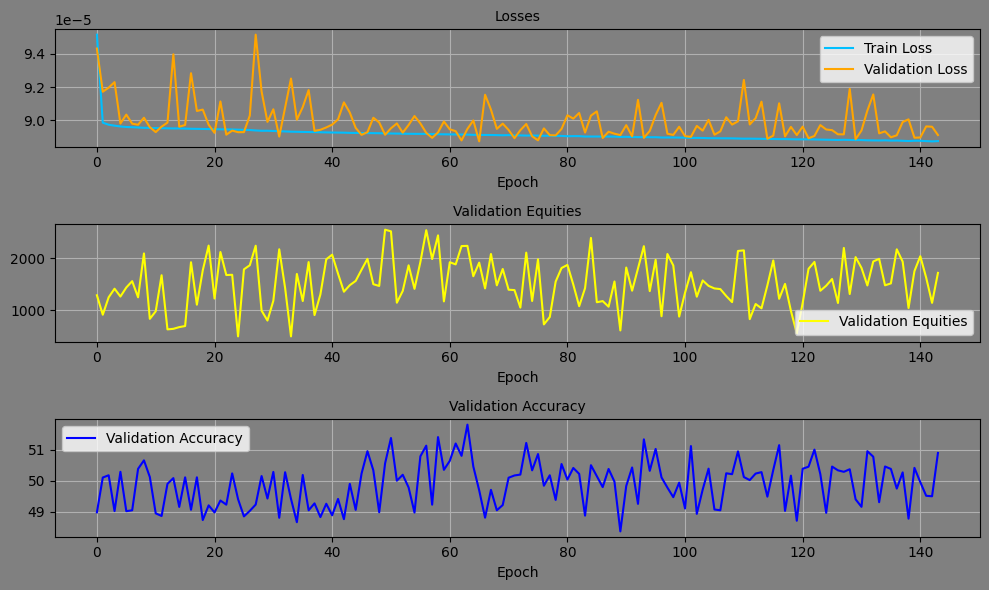

Epoch: 144, Val Equity: 1572.97, Val Accuracy: 49.05 train_losses: 0.0002637702817797225, val_losses: 9.027429769048467e-05, Duration: 0:01:49.614120


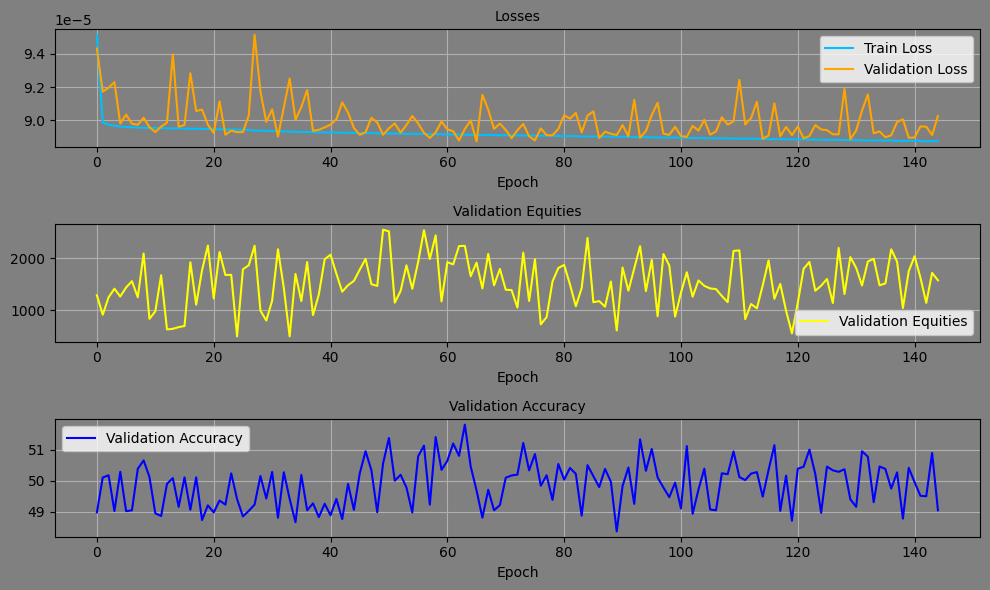

Epoch: 145, Val Equity: 2424.91, Val Accuracy: 51.09 train_losses: 0.00026346200418378044, val_losses: 8.915129728848115e-05, Duration: 0:01:49.339273


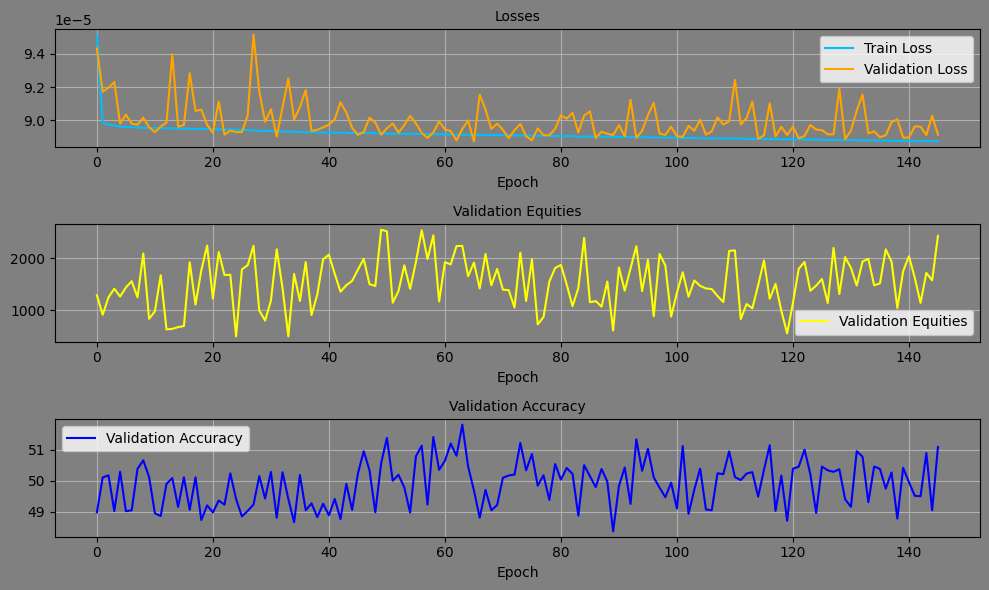

Epoch: 146, Val Equity: 2101.69, Val Accuracy: 49.18 train_losses: 0.0002636211847177991, val_losses: 8.916015212889761e-05, Duration: 0:01:49.960926


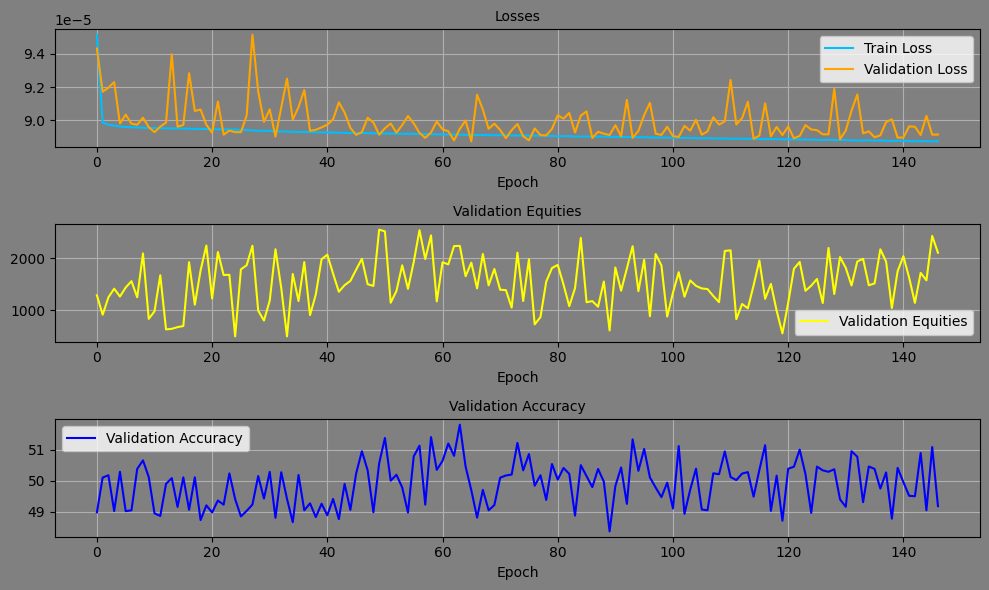

Epoch: 147, Val Equity: 2119.97, Val Accuracy: 51.20 train_losses: 0.0002631424842997984, val_losses: 8.961997082224116e-05, Duration: 0:01:49.498041


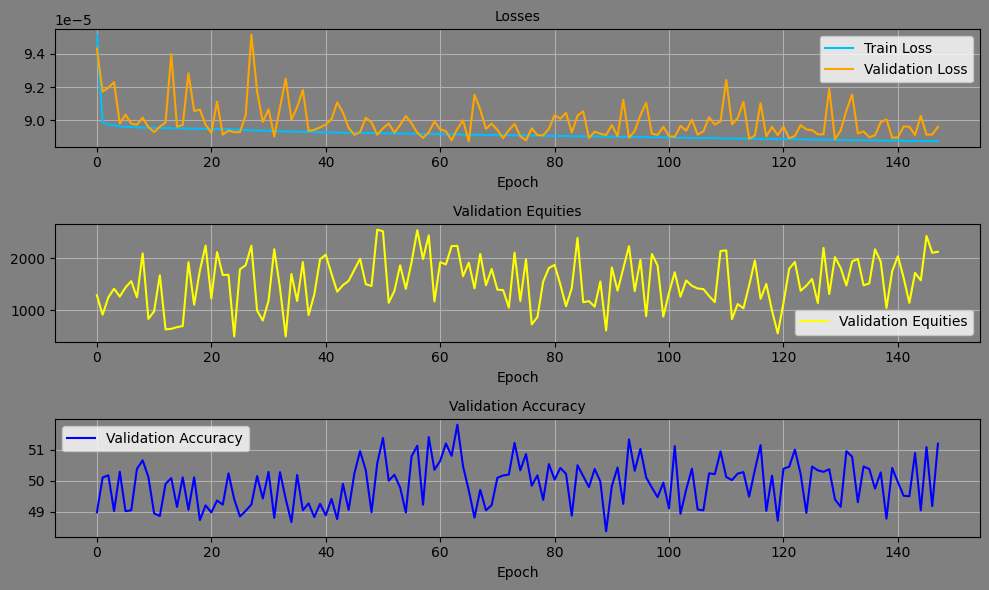

Epoch: 148, Val Equity: 1720.03, Val Accuracy: 49.08 train_losses: 0.0002631673989403532, val_losses: 8.909593452699482e-05, Duration: 0:01:49.987011


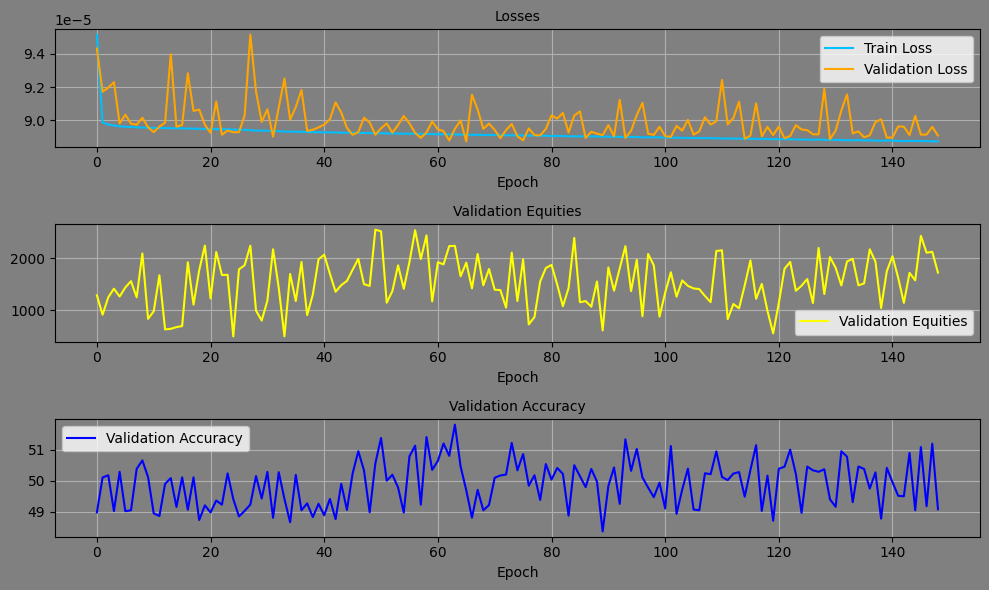

Epoch: 149, Val Equity: 1850.01, Val Accuracy: 50.85 train_losses: 0.00026304969620335816, val_losses: 8.916503429645672e-05, Duration: 0:01:49.928750


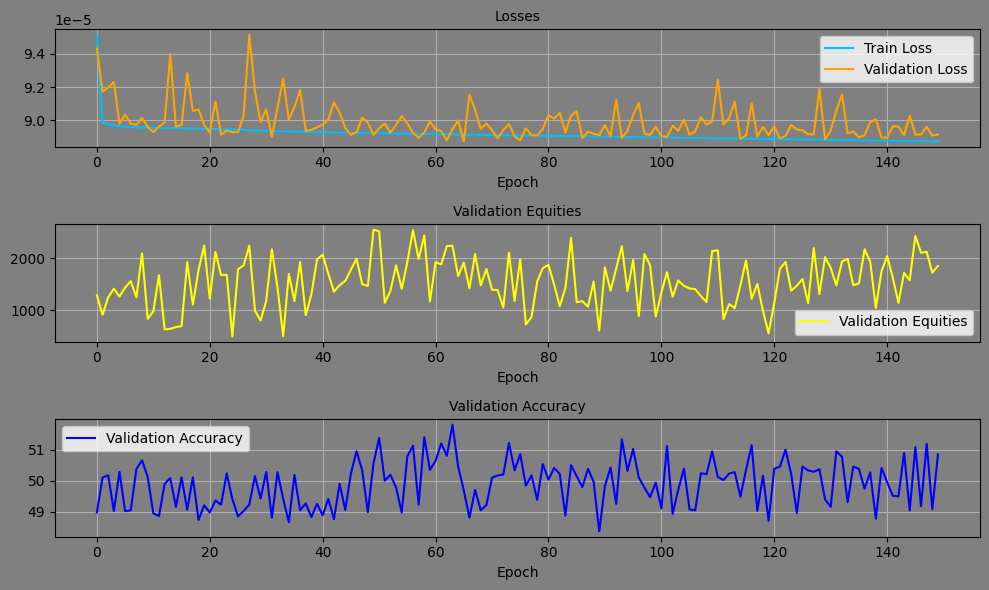

Epoch: 150, Val Equity: 1656.77, Val Accuracy: 49.24 train_losses: 0.00026283789581632263, val_losses: 8.919071115087718e-05, Duration: 0:01:49.657346


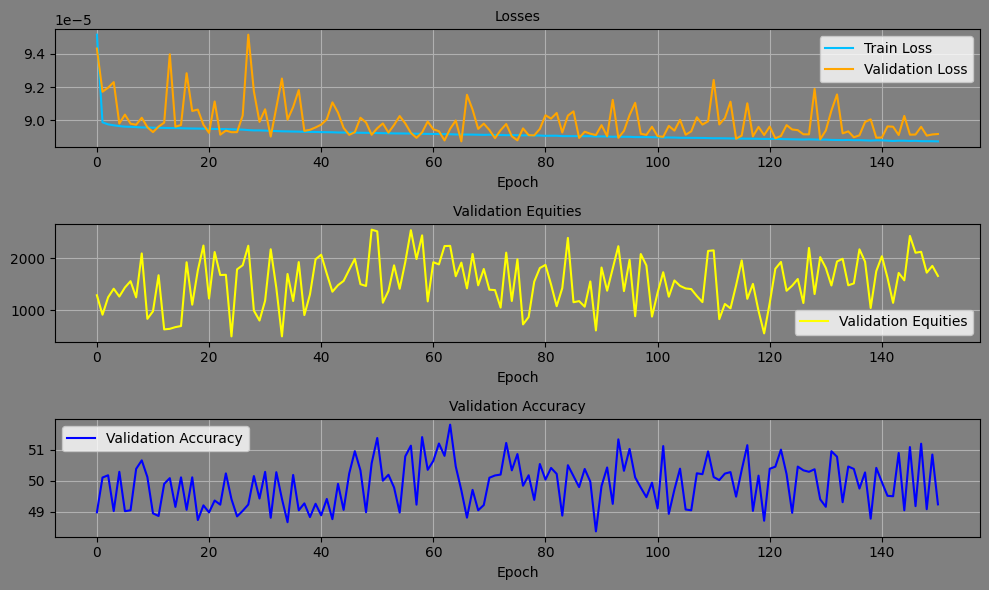

Epoch: 151, Val Equity: 2513.35, Val Accuracy: 50.60 train_losses: 0.00026285555379598643, val_losses: 8.929475734476e-05, Duration: 0:01:51.921486


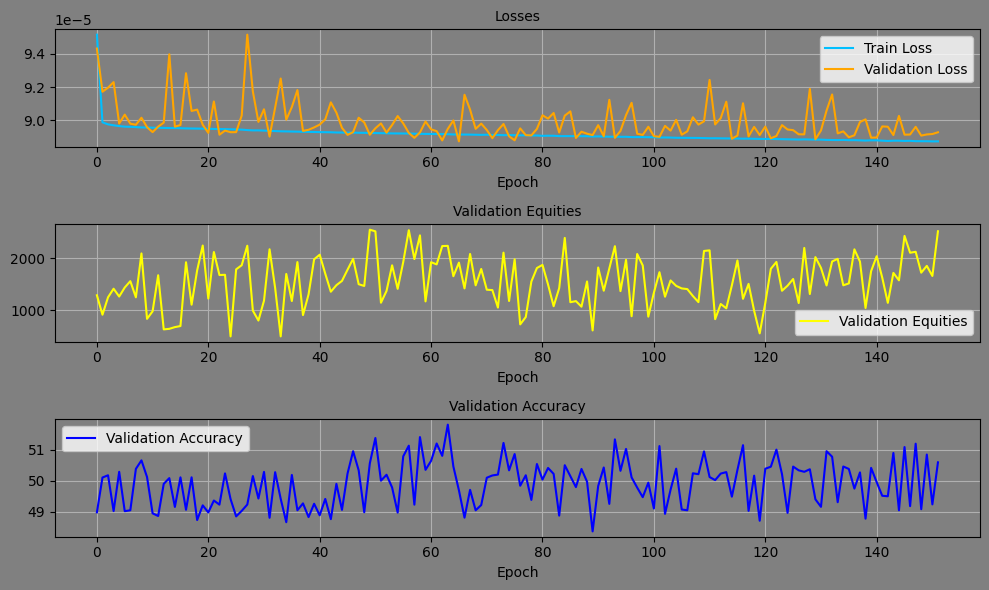

Epoch: 152, Val Equity: 1645.92, Val Accuracy: 50.82 train_losses: 0.00026259002879900495, val_losses: 9.022869926411659e-05, Duration: 0:01:54.099926


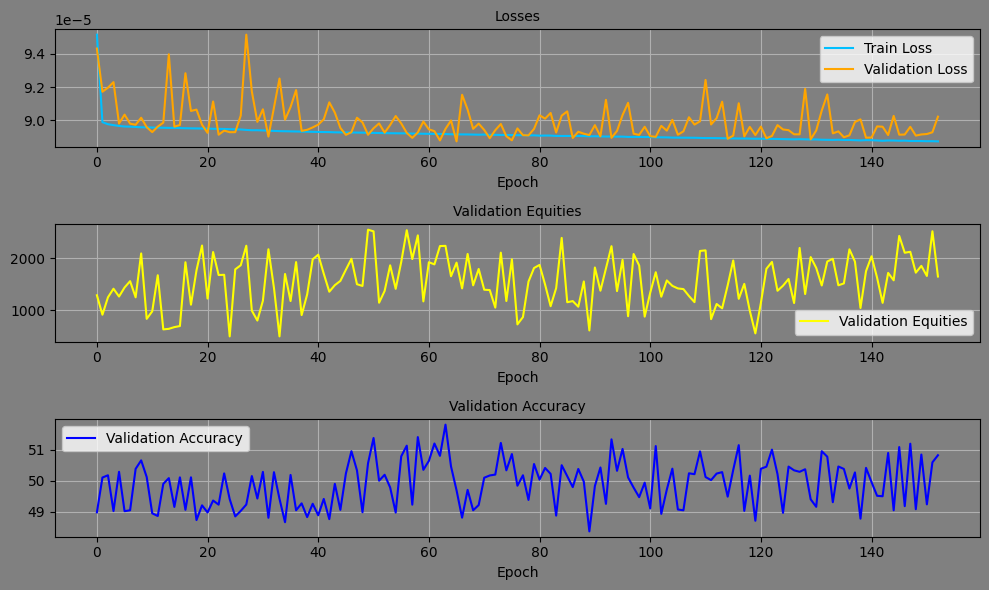

Epoch: 153, Val Equity: 1384.25, Val Accuracy: 48.95 train_losses: 0.00026287327962543387, val_losses: 8.919535321183503e-05, Duration: 0:01:51.807170


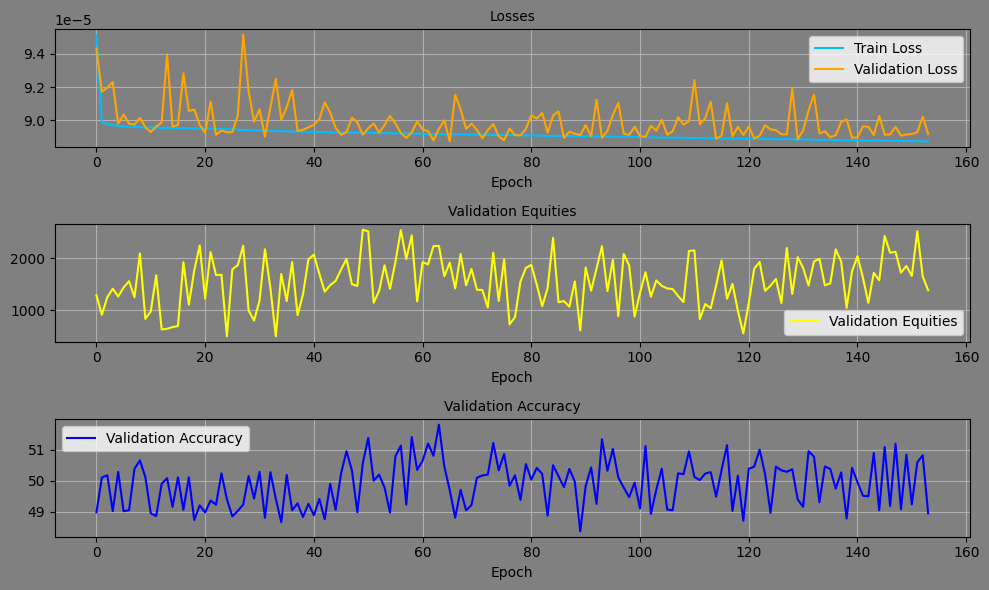

Epoch: 154, Val Equity: 1133.92, Val Accuracy: 50.17 train_losses: 0.000262561632319734, val_losses: 8.946174057200551e-05, Duration: 0:01:50.822255


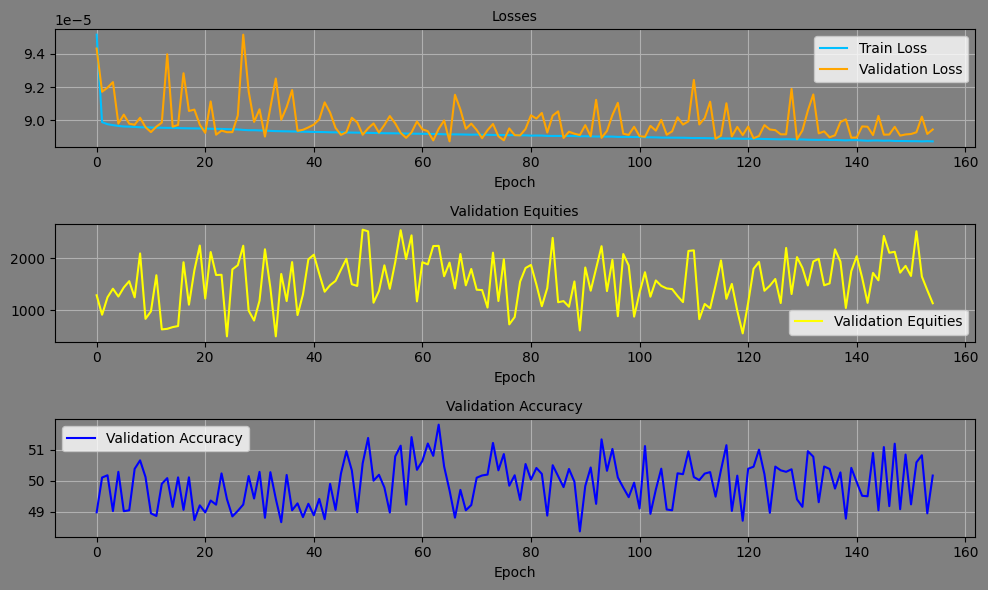

Epoch: 155, Val Equity: 1410.98, Val Accuracy: 50.46 train_losses: 0.0002623512461447377, val_losses: 8.943420834839344e-05, Duration: 0:01:50.374586


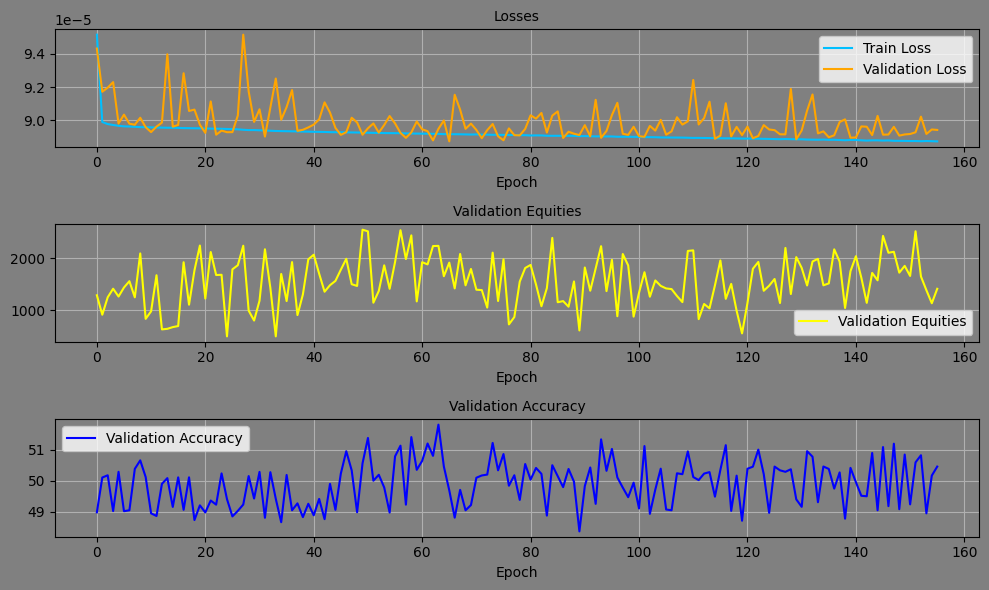

Epoch: 156, Val Equity: 2137.12, Val Accuracy: 50.13 train_losses: 0.0002623388221707508, val_losses: 8.917085506254807e-05, Duration: 0:01:56.498134


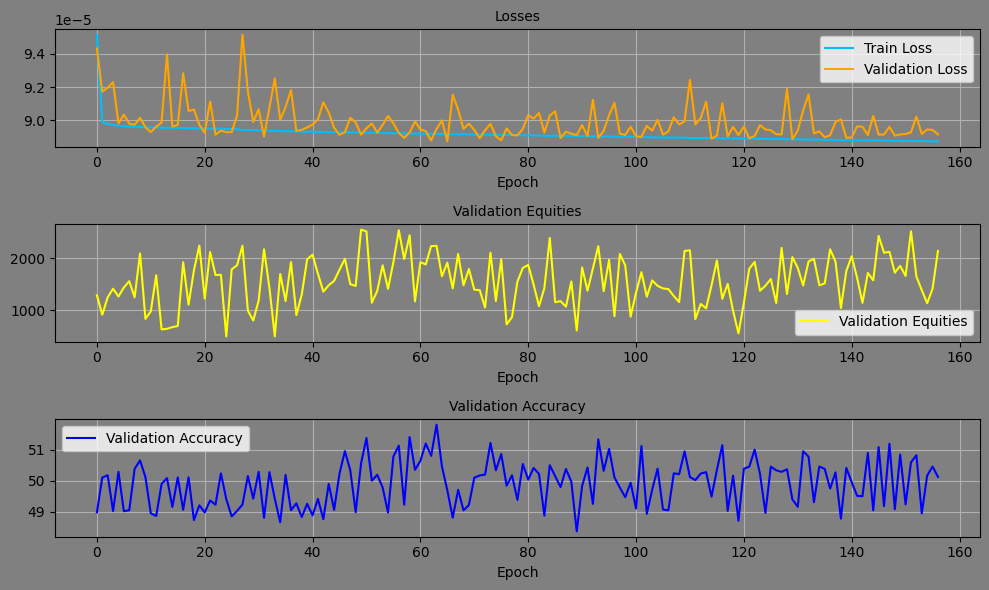

Epoch: 157, Val Equity: 1659.99, Val Accuracy: 51.20 train_losses: 0.0002622789006118996, val_losses: 8.891057223081589e-05, Duration: 0:01:49.511200


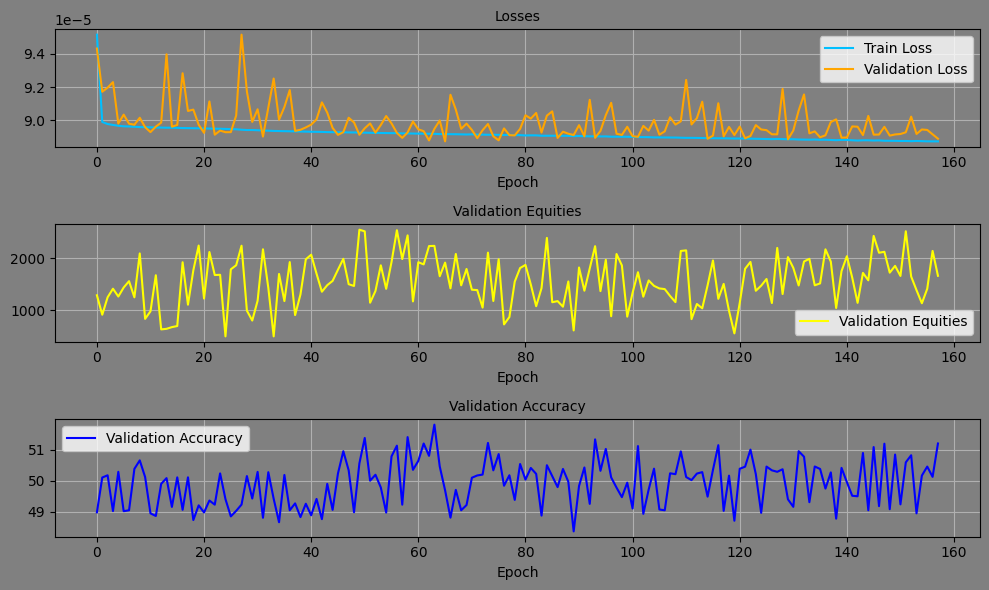

Epoch: 158, Val Equity: 914.10, Val Accuracy: 50.17 train_losses: 0.0002621344195470711, val_losses: 8.929322939366102e-05, Duration: 0:01:50.962568


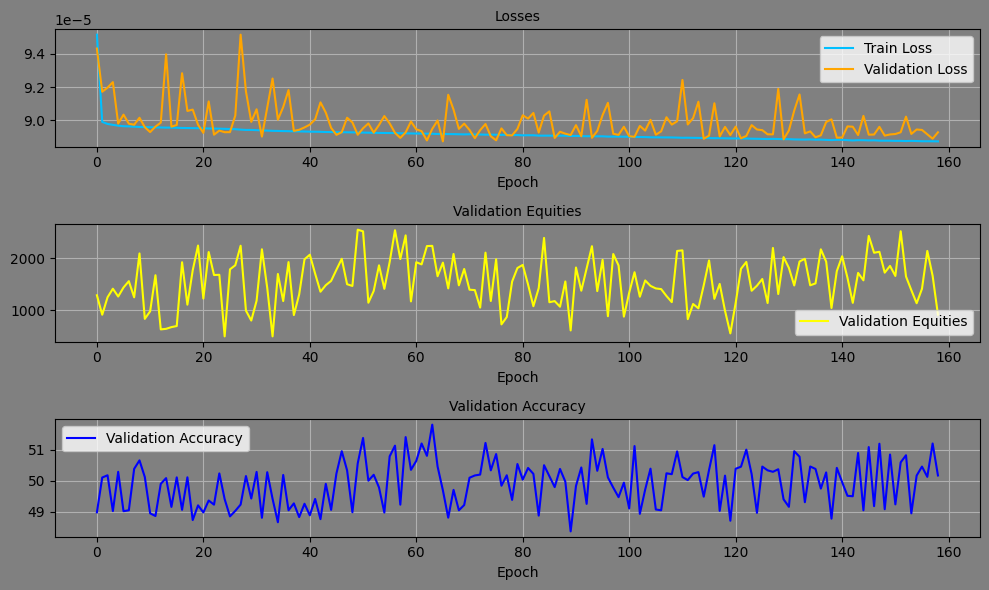

Epoch: 159, Val Equity: 1388.10, Val Accuracy: 49.74 train_losses: 0.0002619738712175929, val_losses: 9.016265539685264e-05, Duration: 0:01:49.408549


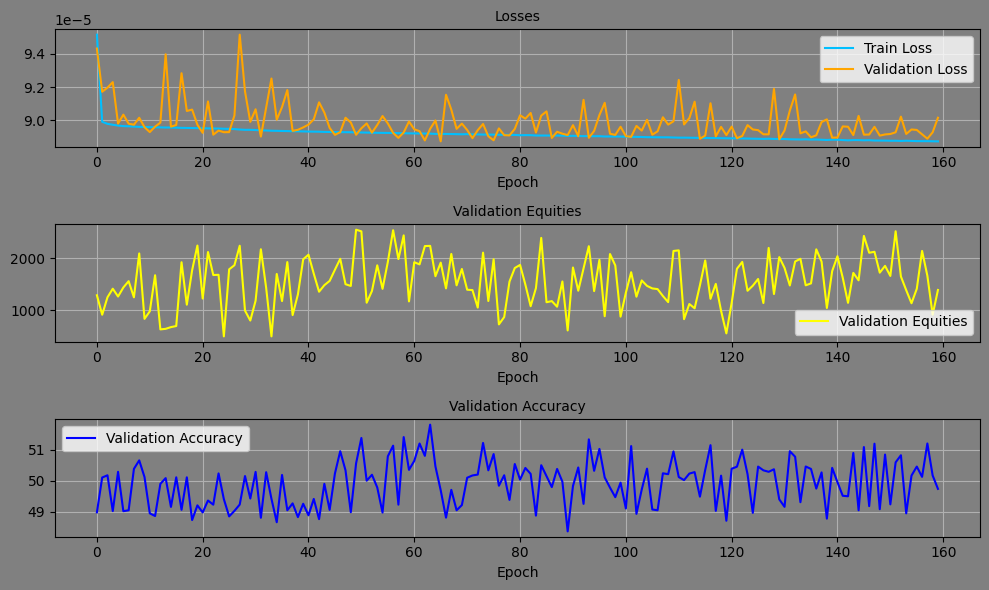

Epoch: 160, Val Equity: 1860.59, Val Accuracy: 49.51 train_losses: 0.0002619278083476807, val_losses: 9.002635488286614e-05, Duration: 0:01:49.899330


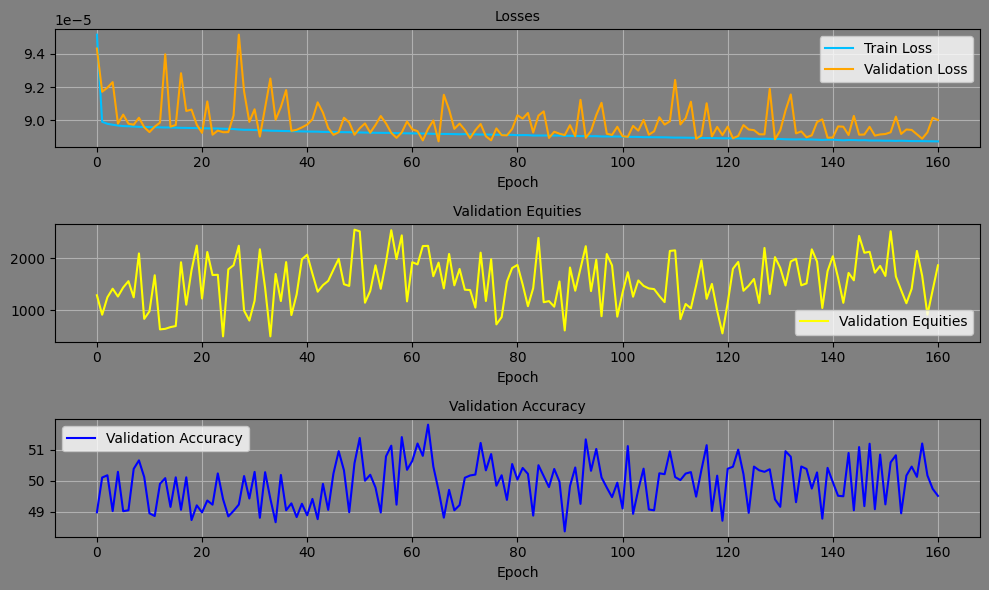

Epoch: 161, Val Equity: 1694.29, Val Accuracy: 51.14 train_losses: 0.0002619102101927113, val_losses: 8.964660082710907e-05, Duration: 0:01:49.102868


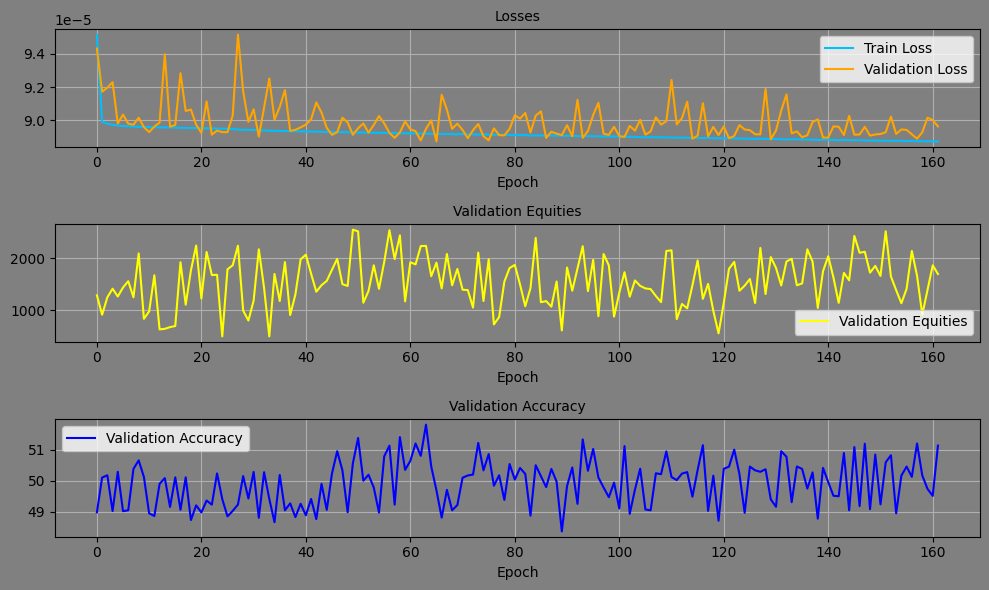

Epoch: 162, Val Equity: 1919.55, Val Accuracy: 51.33 train_losses: 0.00026170354113457683, val_losses: 8.988574700197205e-05, Duration: 0:01:50.111815


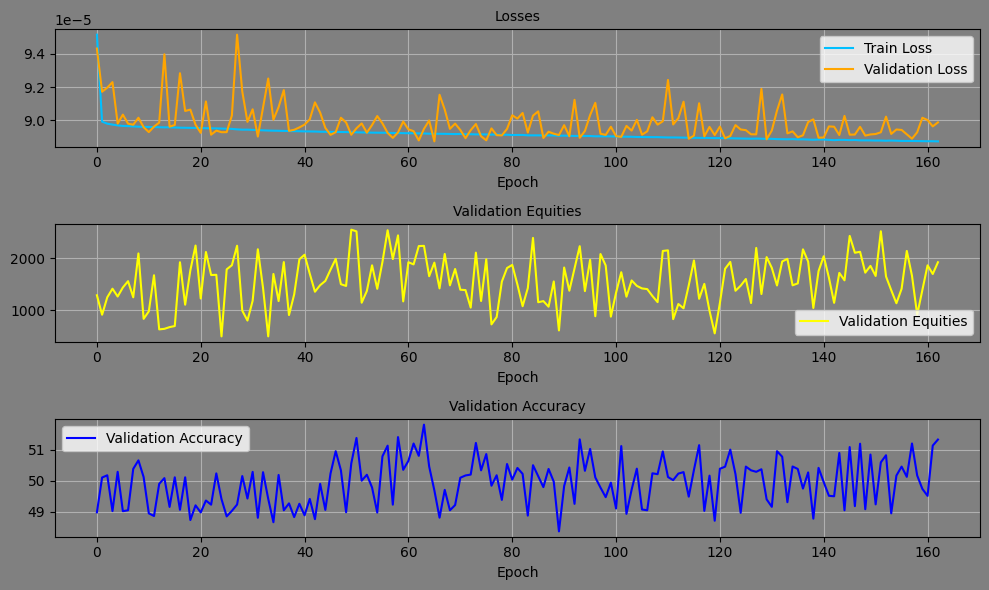

Epoch: 163, Val Equity: 2312.58, Val Accuracy: 51.20 train_losses: 0.0002616437073969592, val_losses: 8.920187974581495e-05, Duration: 0:01:50.188118


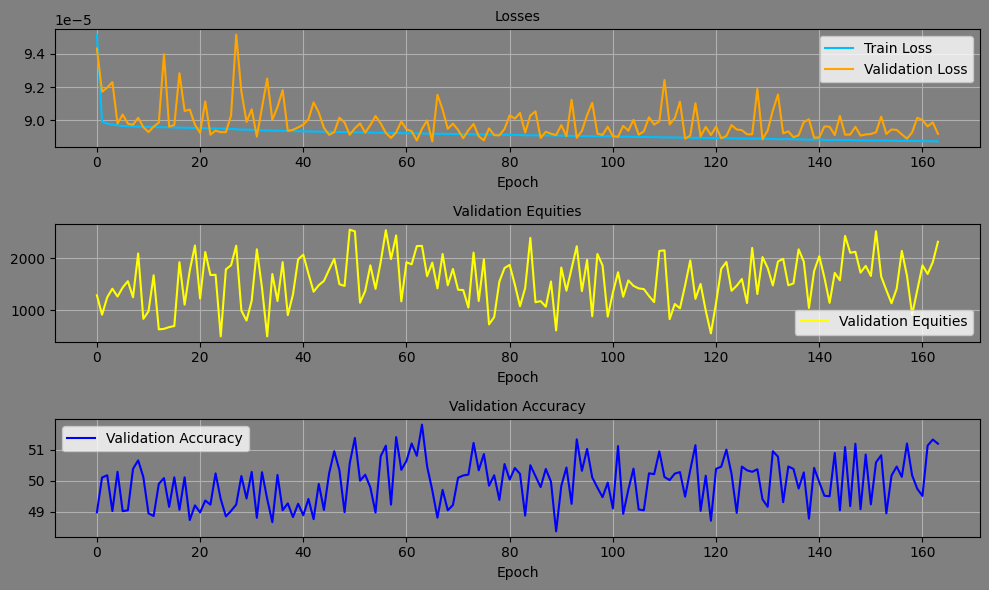

Epoch: 164, Val Equity: 1871.64, Val Accuracy: 51.11 train_losses: 0.00026168399702234036, val_losses: 8.92228345037438e-05, Duration: 0:01:48.906706


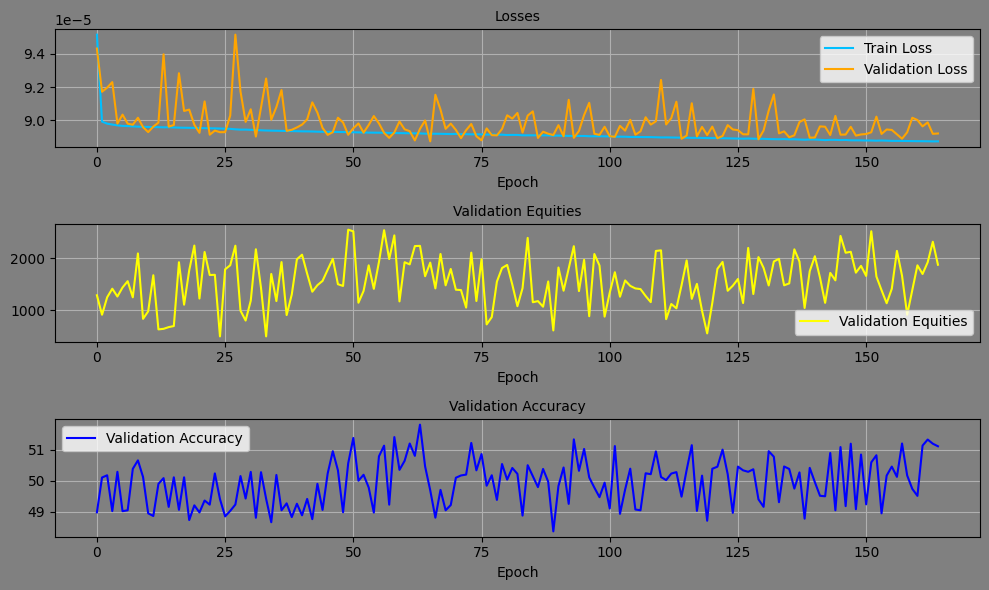

Epoch: 165, Val Equity: 1179.41, Val Accuracy: 50.33 train_losses: 0.0002612694468024255, val_losses: 9.084708290174603e-05, Duration: 0:01:52.887548


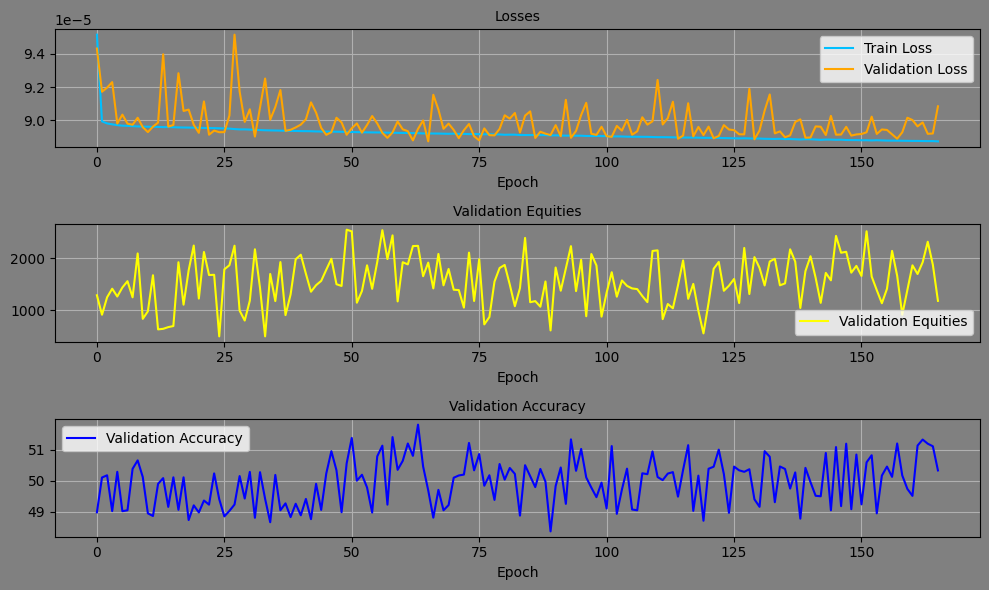

Epoch: 166, Val Equity: 1267.96, Val Accuracy: 48.32 train_losses: 0.0002612583971724449, val_losses: 8.93819669727236e-05, Duration: 0:01:49.831188


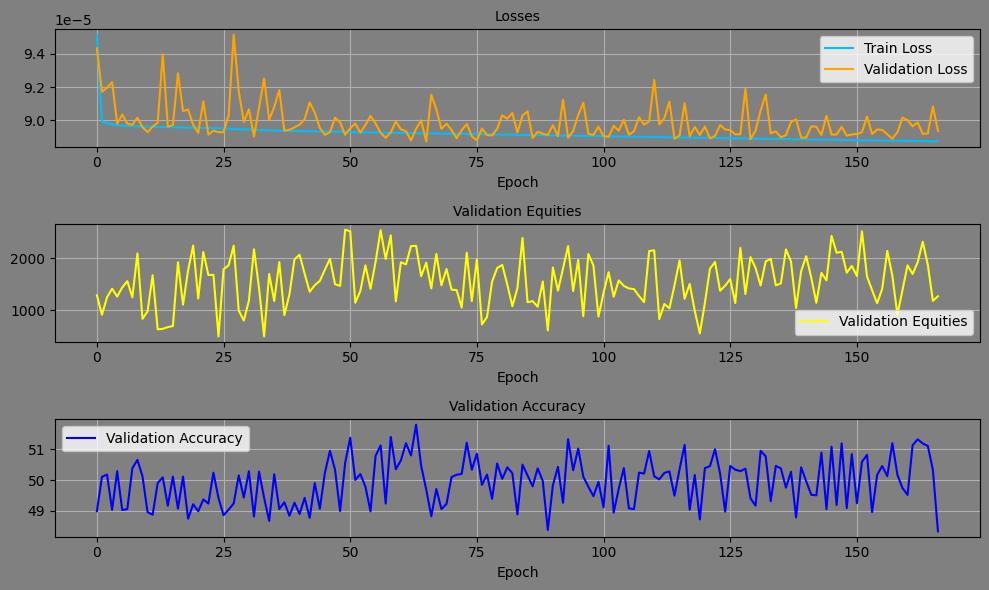

Epoch: 167, Val Equity: 1671.16, Val Accuracy: 50.45 train_losses: 0.0002611478603881085, val_losses: 8.96102937986143e-05, Duration: 0:01:49.726734


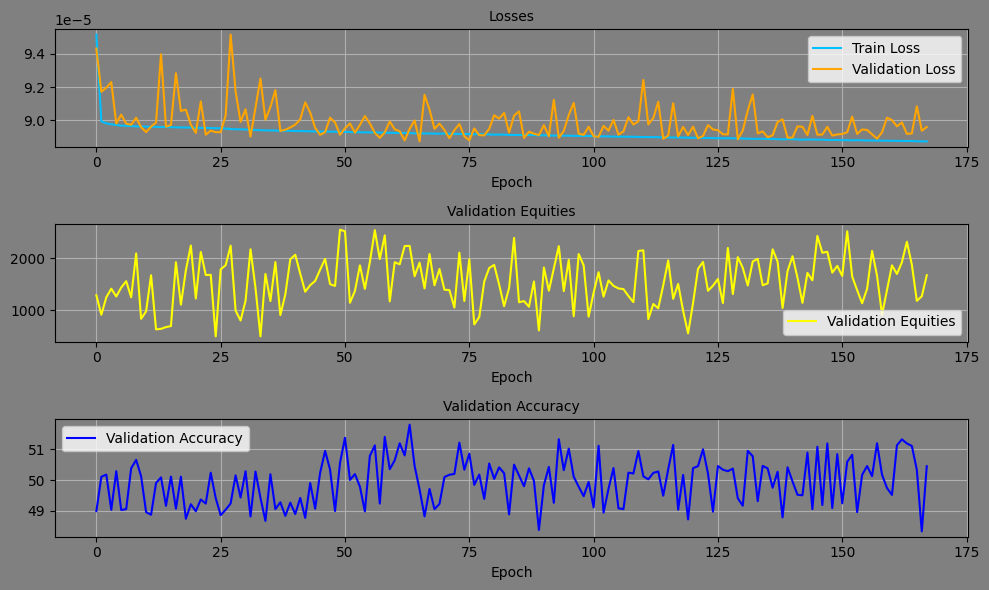

Epoch: 168, Val Equity: 1777.24, Val Accuracy: 49.64 train_losses: 0.00026113387787664186, val_losses: 9.001723083201796e-05, Duration: 0:01:50.324662


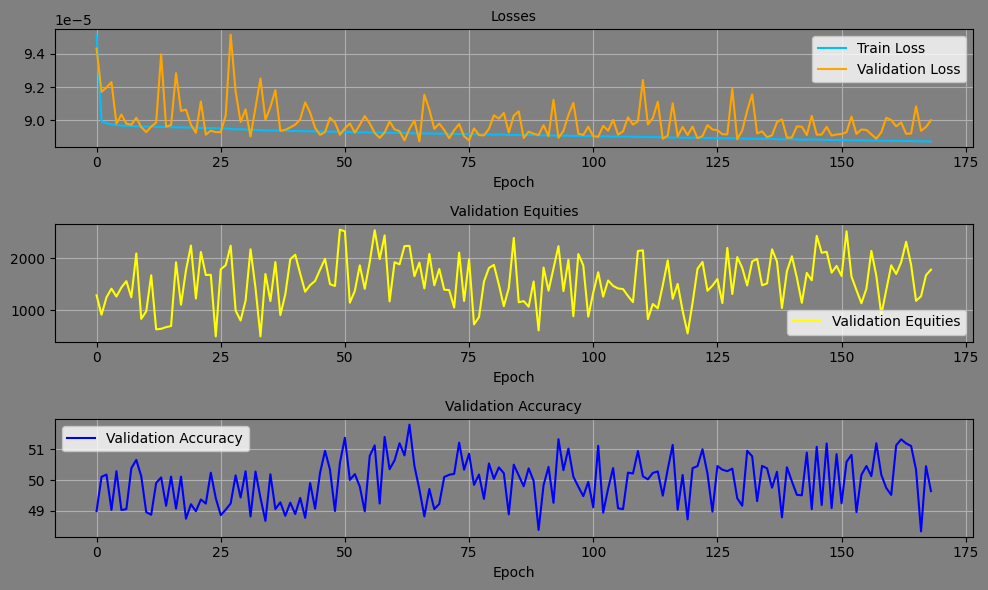

Epoch: 169, Val Equity: 1971.03, Val Accuracy: 49.73 train_losses: 0.00026067820632247237, val_losses: 8.888261072570458e-05, Duration: 0:01:49.316408


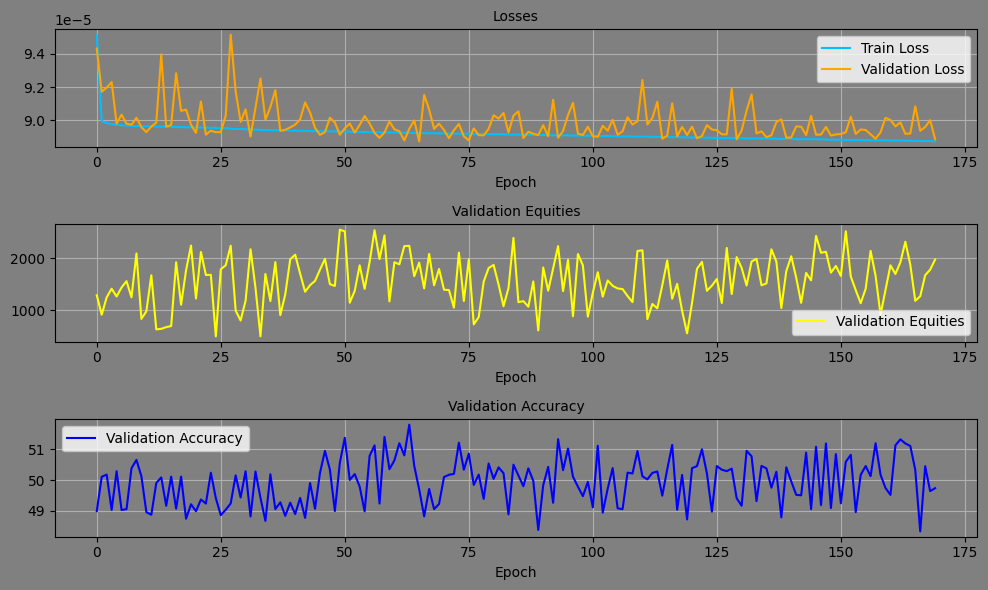

Epoch: 170, Val Equity: 1314.65, Val Accuracy: 49.03 train_losses: 0.00026073585931547176, val_losses: 8.894572238205001e-05, Duration: 0:01:50.738490


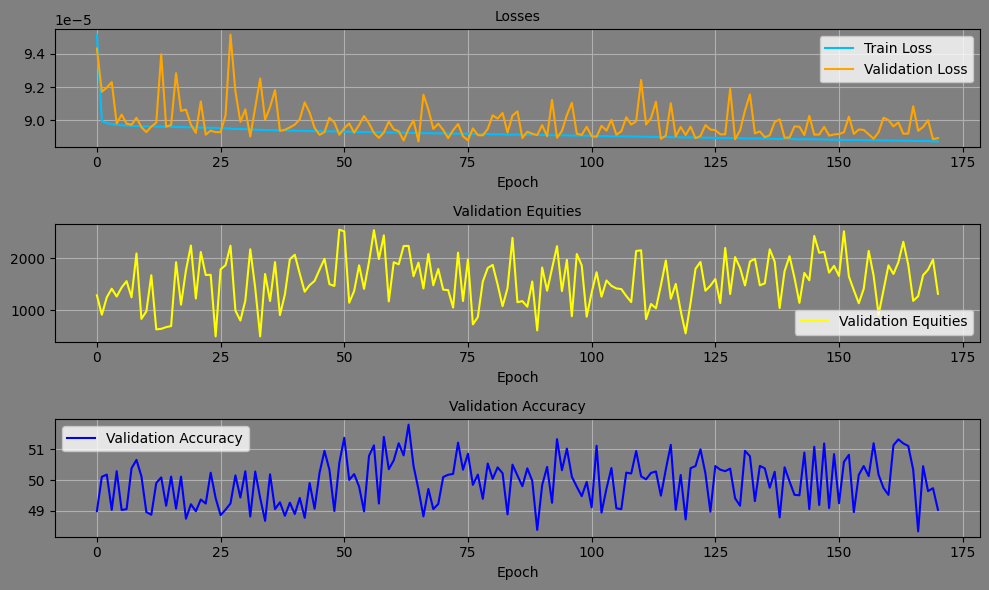

Epoch: 171, Val Equity: 1145.57, Val Accuracy: 50.31 train_losses: 0.00026086725521614295, val_losses: 9.222704829880968e-05, Duration: 0:01:50.743288


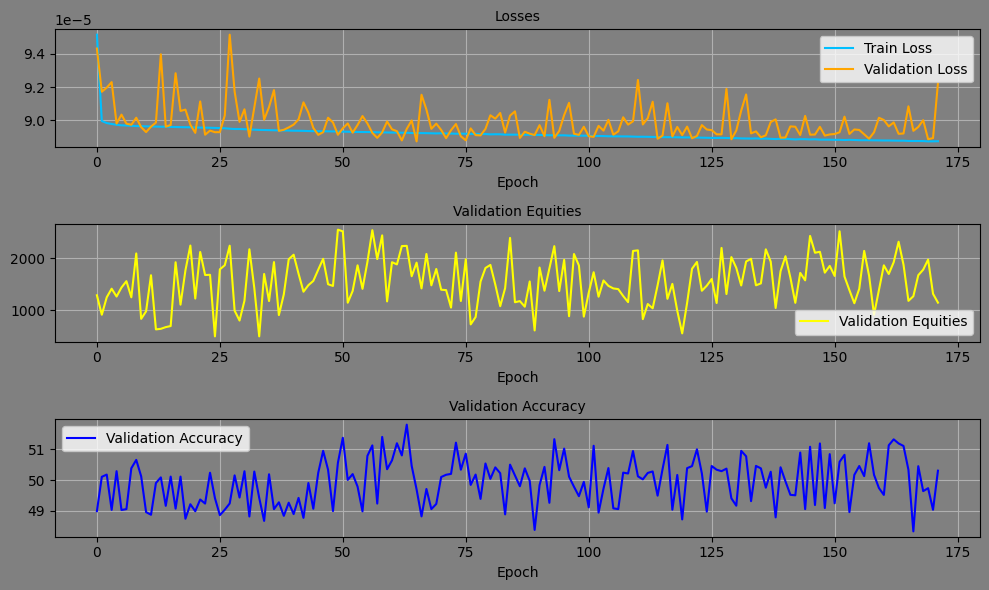

Epoch: 172, Val Equity: 1708.79, Val Accuracy: 49.11 train_losses: 0.0002606312000884236, val_losses: 9.034452523337677e-05, Duration: 0:01:50.839070


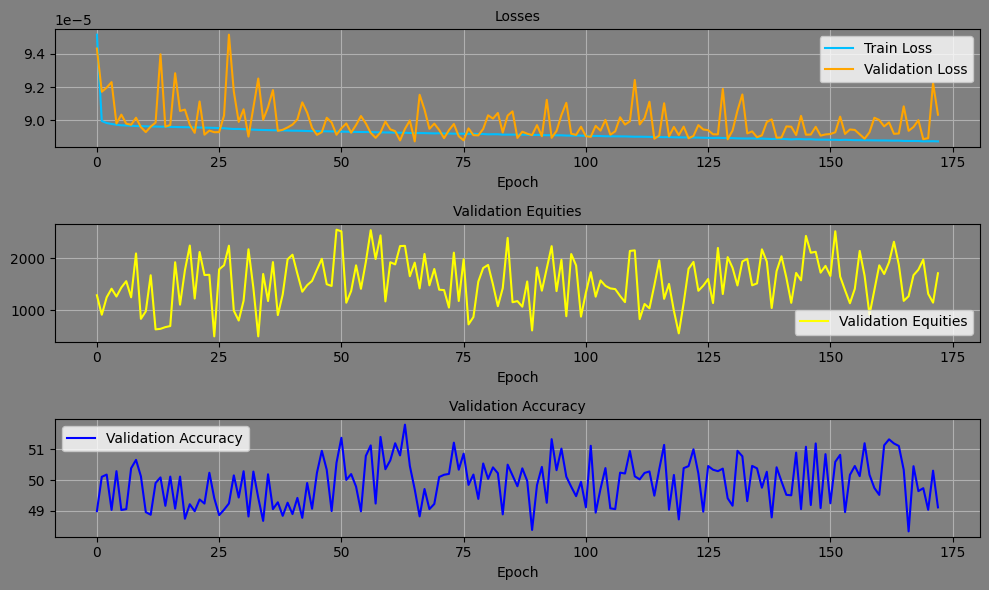

Epoch: 173, Val Equity: 1596.79, Val Accuracy: 49.52 train_losses: 0.0002605880668881131, val_losses: 8.937236270867288e-05, Duration: 0:01:49.737033


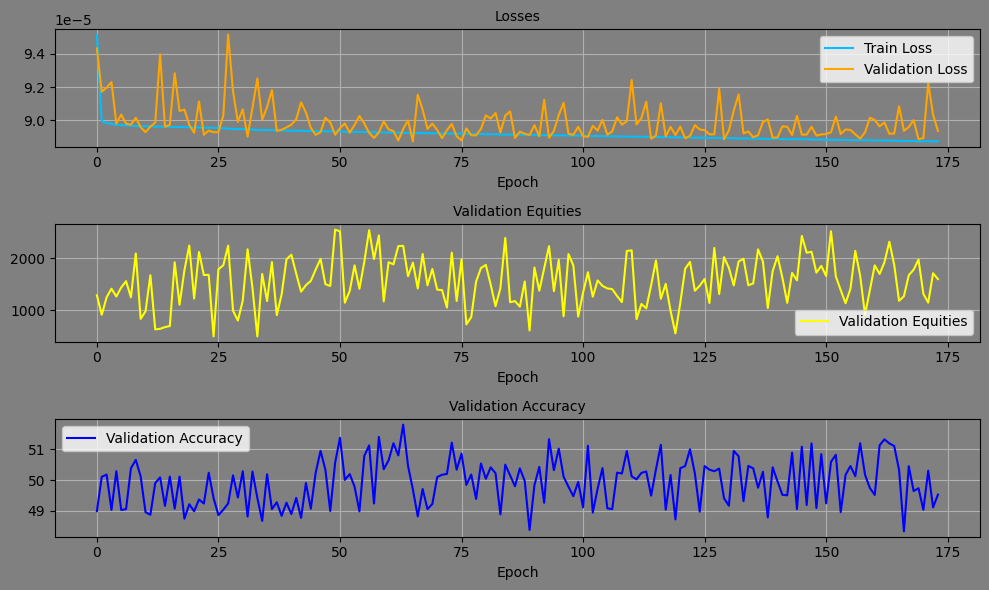

Epoch: 174, Val Equity: 2083.56, Val Accuracy: 51.37 train_losses: 0.0002603669486243382, val_losses: 8.98256475920789e-05, Duration: 0:01:50.221234


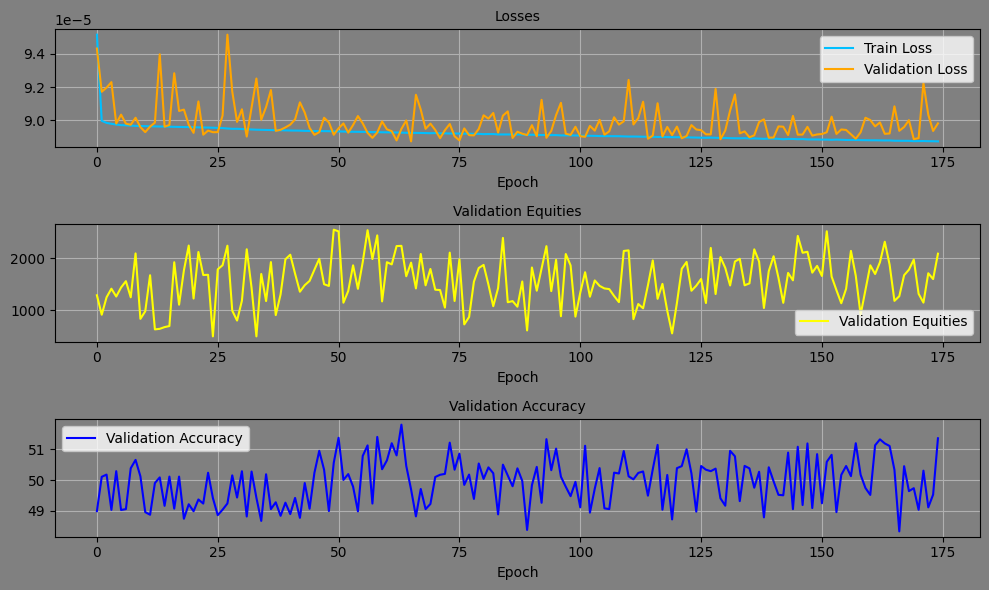

Epoch: 175, Val Equity: 1228.36, Val Accuracy: 50.11 train_losses: 0.0002603741873864844, val_losses: 8.958433318184689e-05, Duration: 0:01:50.102717


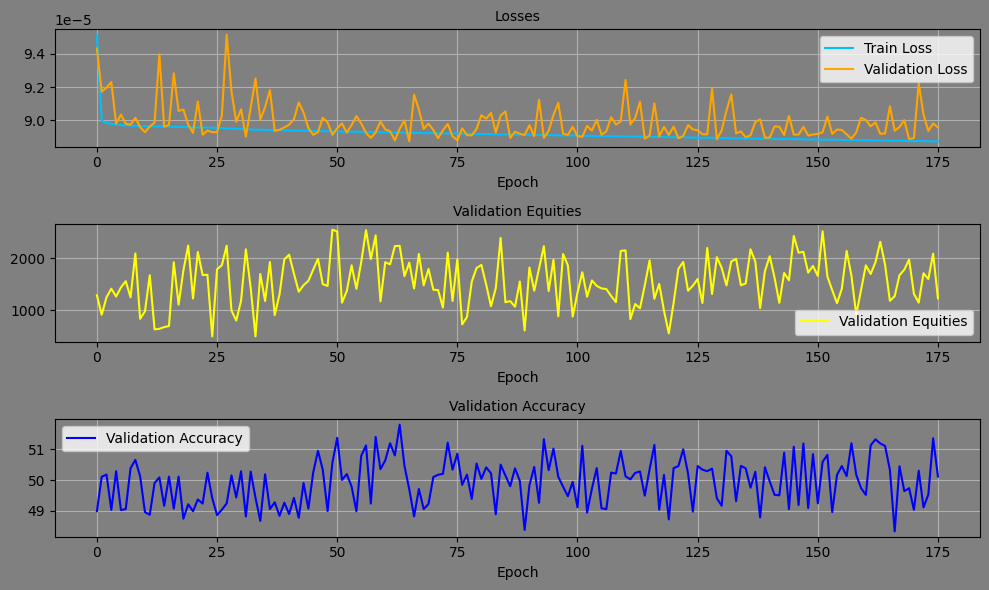

Epoch: 176, Val Equity: 2282.57, Val Accuracy: 50.89 train_losses: 0.0002602396727286582, val_losses: 8.921449625631794e-05, Duration: 0:01:49.613180


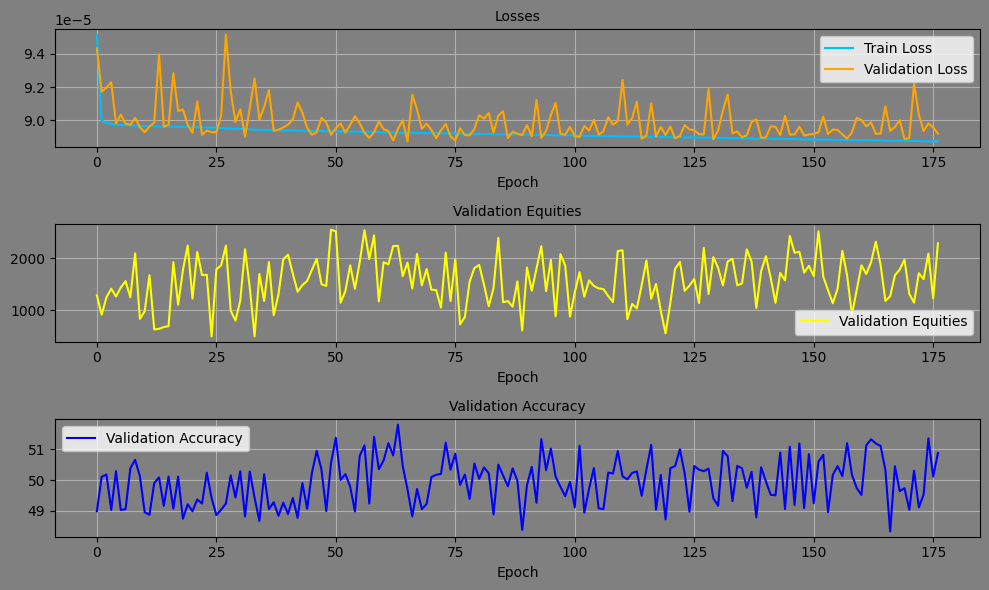

Epoch: 177, Val Equity: 2014.44, Val Accuracy: 49.71 train_losses: 0.00026007637158100786, val_losses: 8.914509089663625e-05, Duration: 0:01:48.789342


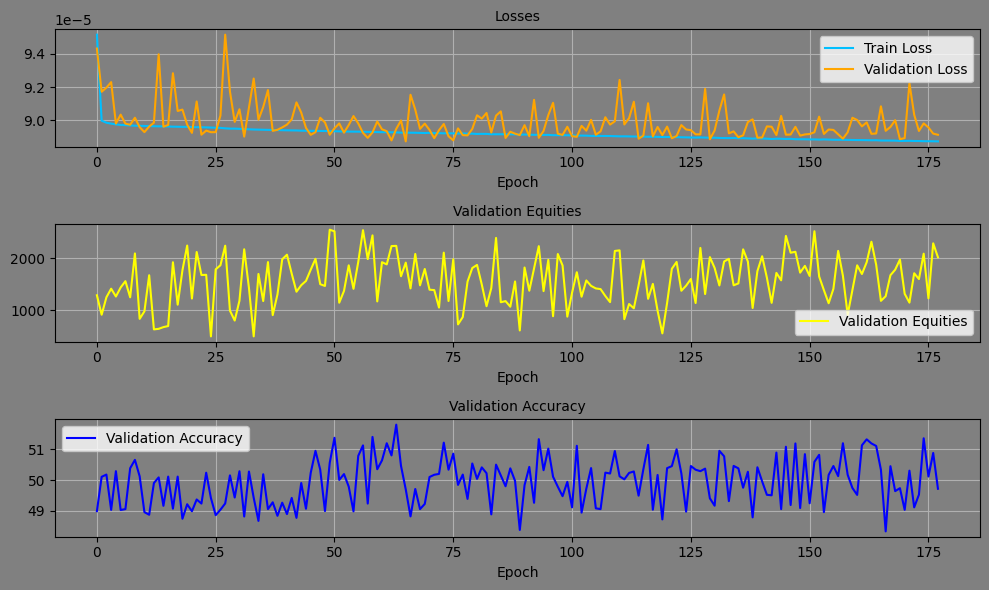

Epoch: 178, Val Equity: 1450.45, Val Accuracy: 49.50 train_losses: 0.0002601331720419568, val_losses: 8.917741070035845e-05, Duration: 0:01:49.976895


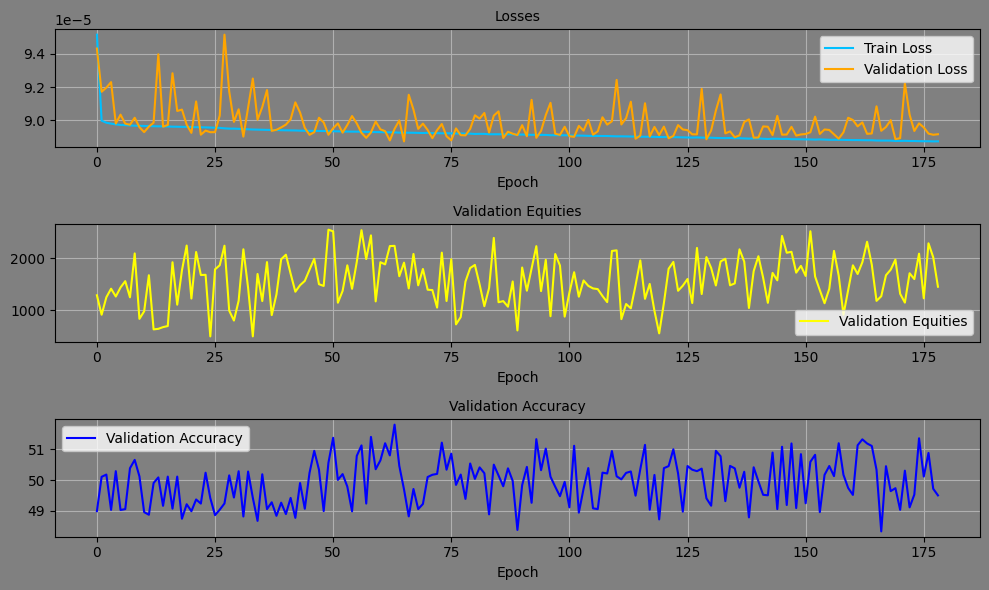

Epoch: 179, Val Equity: 1520.07, Val Accuracy: 50.63 train_losses: 0.0002599985069260709, val_losses: 8.986805187305436e-05, Duration: 0:01:49.188684


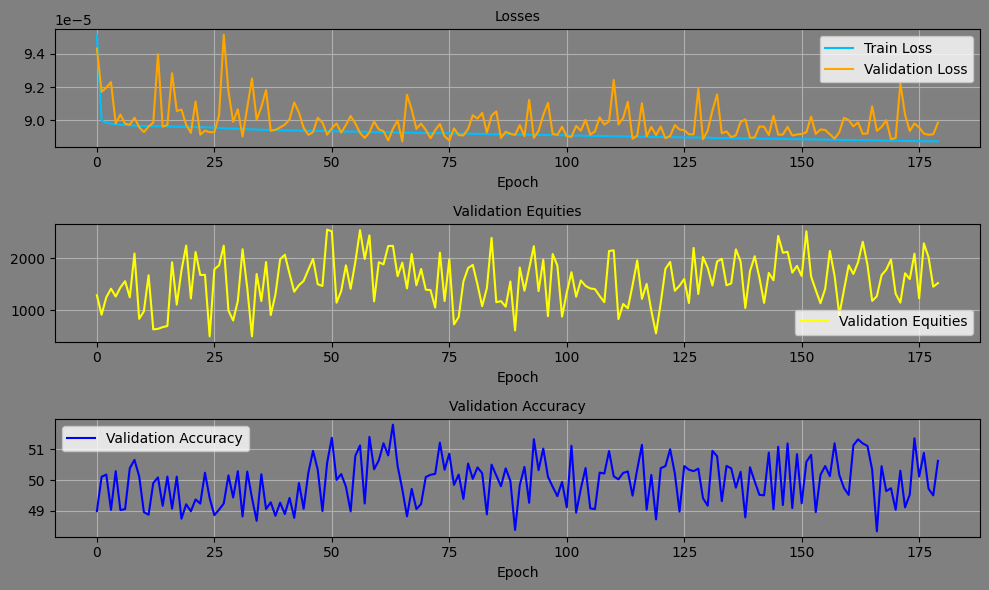

Epoch: 180, Val Equity: 1376.94, Val Accuracy: 50.24 train_losses: 0.00025991895715722467, val_losses: 9.069011139217764e-05, Duration: 0:01:51.134607


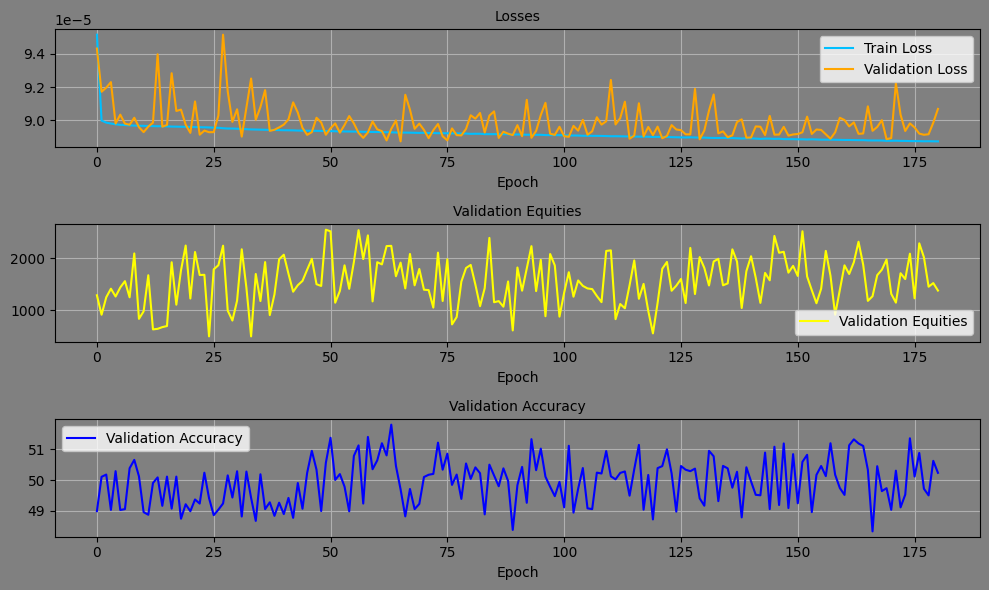

Epoch: 181, Val Equity: 2359.07, Val Accuracy: 51.37 train_losses: 0.00025990472843426596, val_losses: 9.083966870093718e-05, Duration: 0:01:49.613652


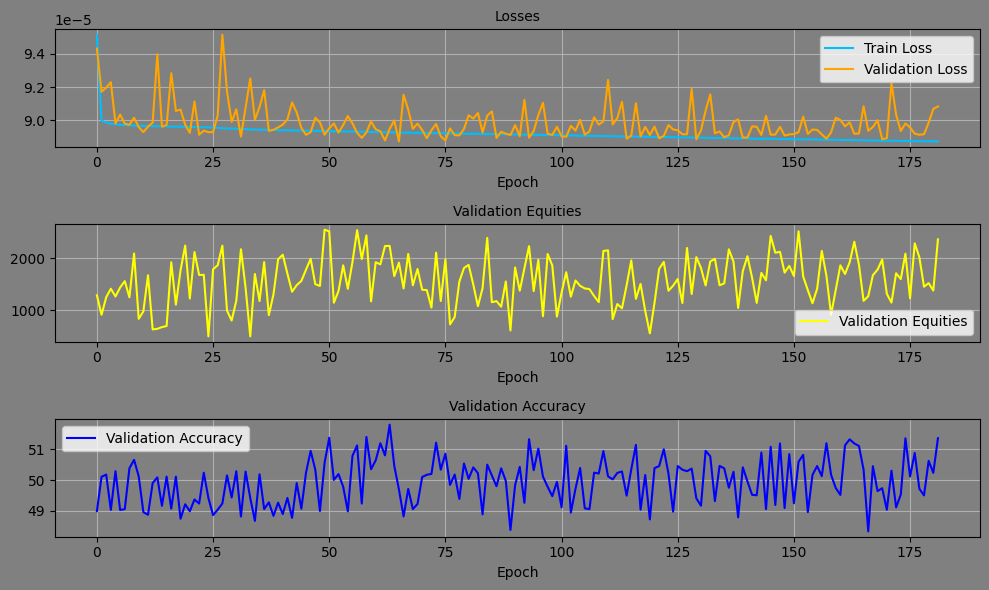

Epoch: 182, Val Equity: 2316.69, Val Accuracy: 51.23 train_losses: 0.0002595286588436791, val_losses: 8.937804523156956e-05, Duration: 0:01:50.954469


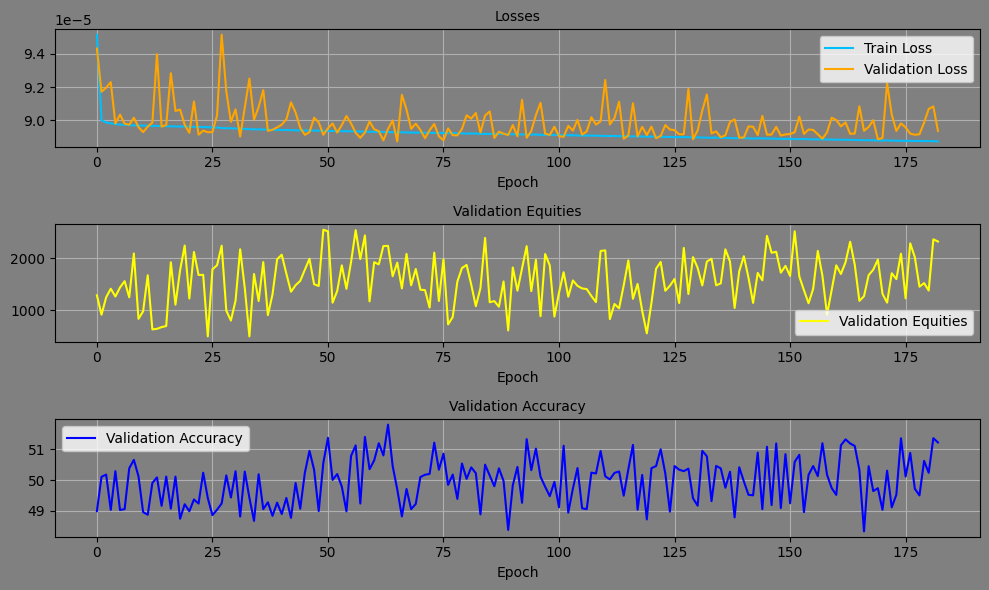

Epoch: 183, Val Equity: 1609.17, Val Accuracy: 51.36 train_losses: 0.0002596043266183232, val_losses: 8.976023673312739e-05, Duration: 0:01:50.181412


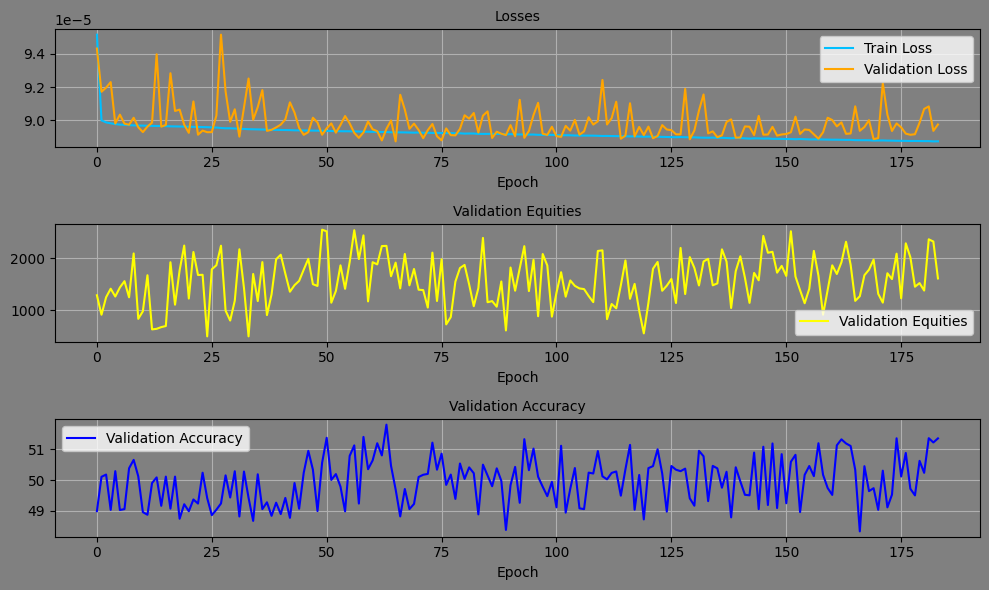

Epoch: 184, Val Equity: 1708.41, Val Accuracy: 50.14 train_losses: 0.0002595384399499166, val_losses: 8.91127492650412e-05, Duration: 0:01:49.593487


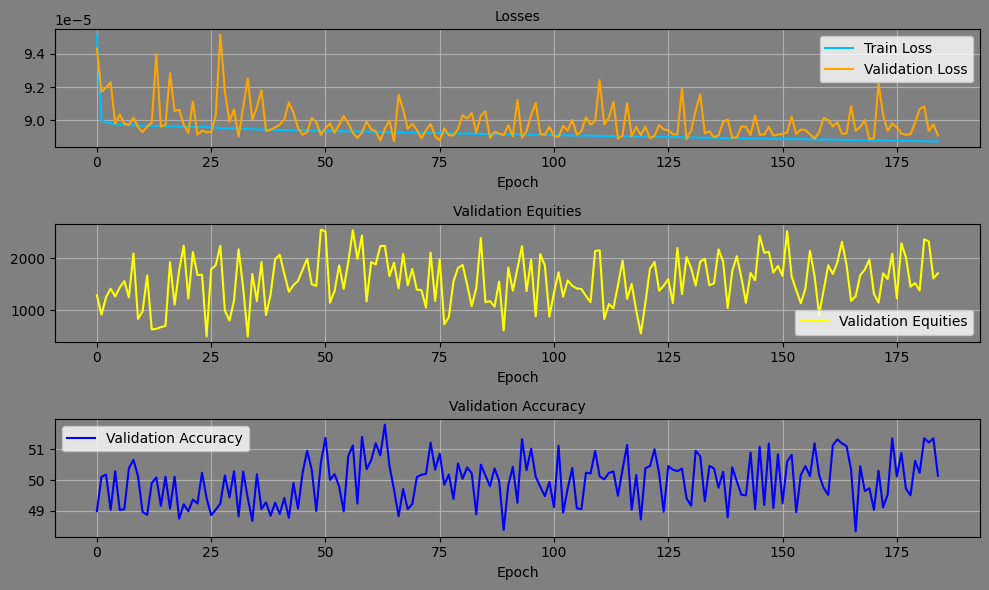

Epoch: 185, Val Equity: 1592.93, Val Accuracy: 50.61 train_losses: 0.0002595545452192443, val_losses: 9.04495973372832e-05, Duration: 0:01:50.227232


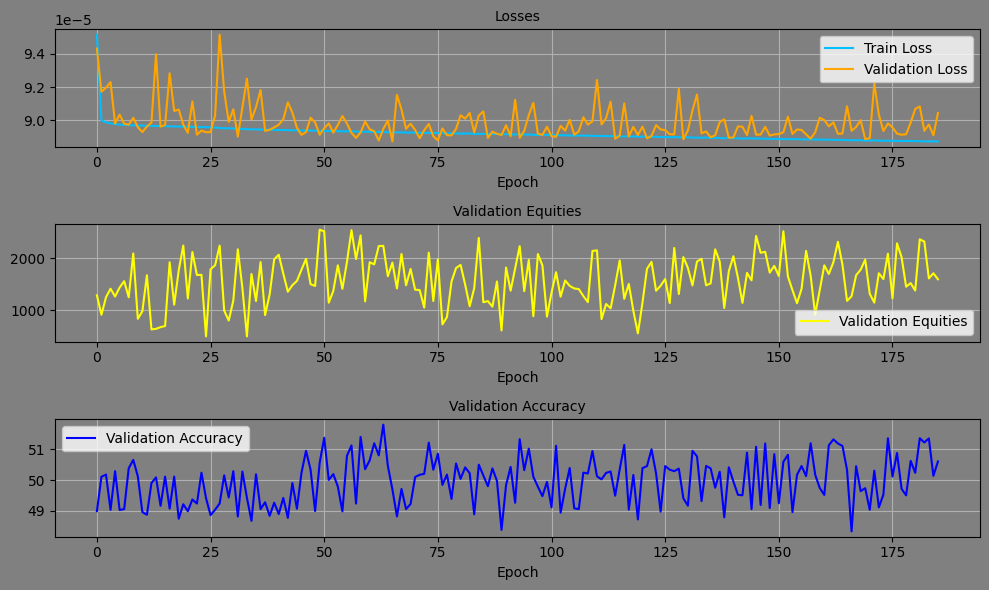

Epoch: 186, Val Equity: 2042.11, Val Accuracy: 51.37 train_losses: 0.0002591849671193628, val_losses: 8.923815039452165e-05, Duration: 0:01:49.500769


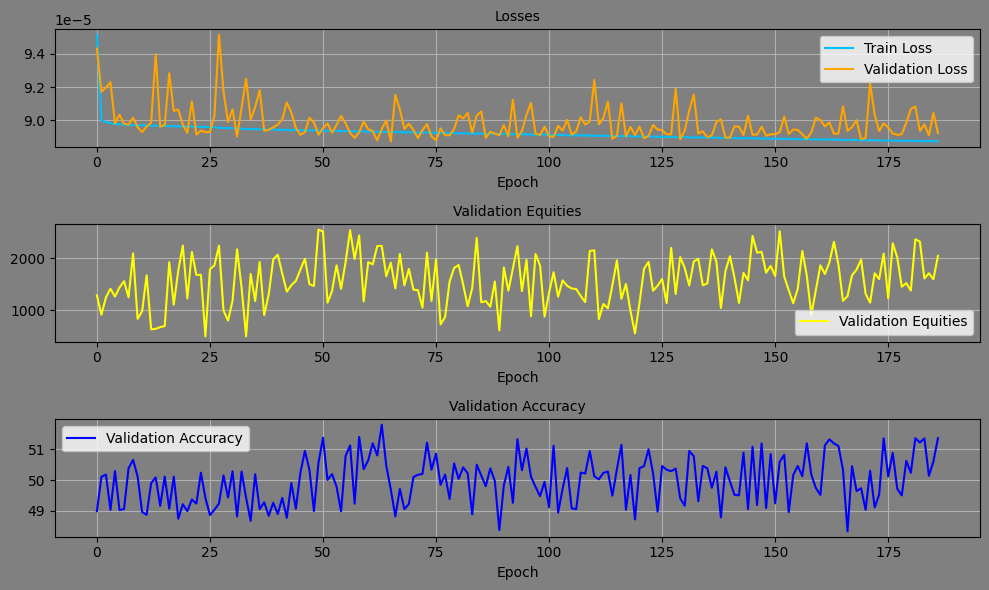

Epoch: 187, Val Equity: 974.71, Val Accuracy: 49.91 train_losses: 0.0002591366240334707, val_losses: 8.943529974203557e-05, Duration: 0:01:49.832214


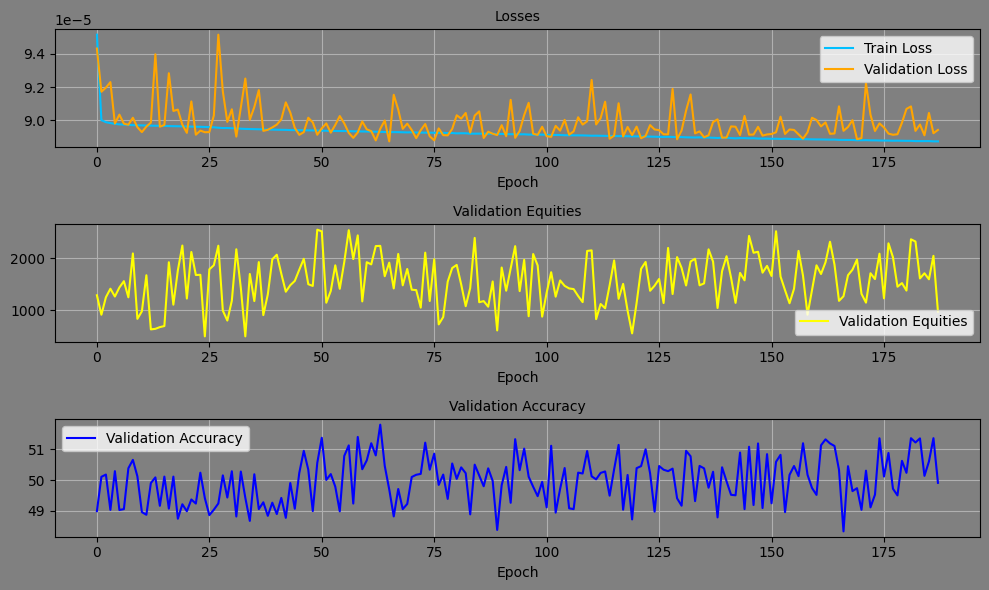

Epoch: 188, Val Equity: 1632.15, Val Accuracy: 50.20 train_losses: 0.00025907450957197954, val_losses: 8.898361556930467e-05, Duration: 0:01:50.135967


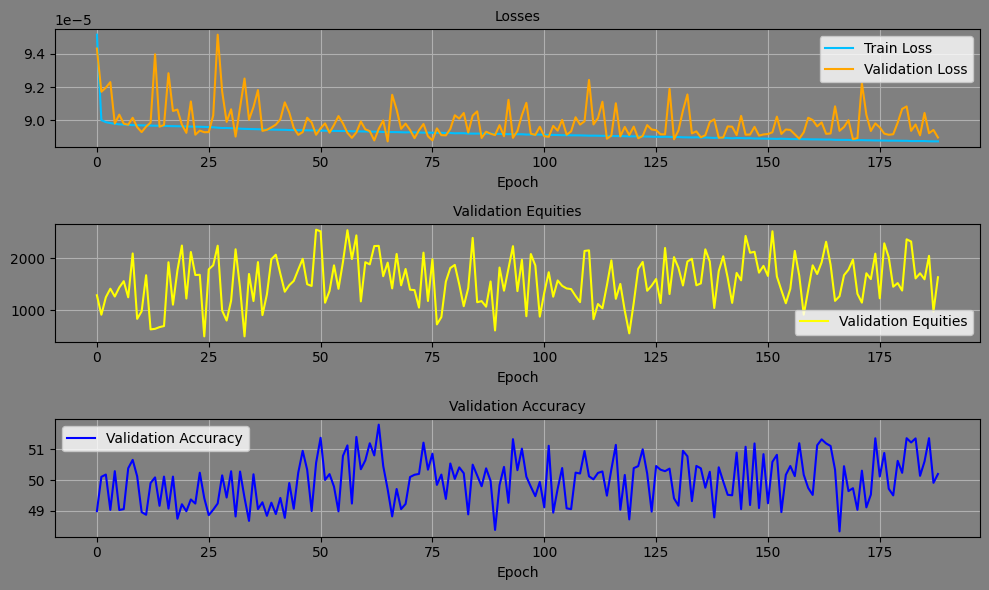

Epoch: 189, Val Equity: 1571.66, Val Accuracy: 50.51 train_losses: 0.0002587361795227347, val_losses: 8.951291238190606e-05, Duration: 0:01:49.923078


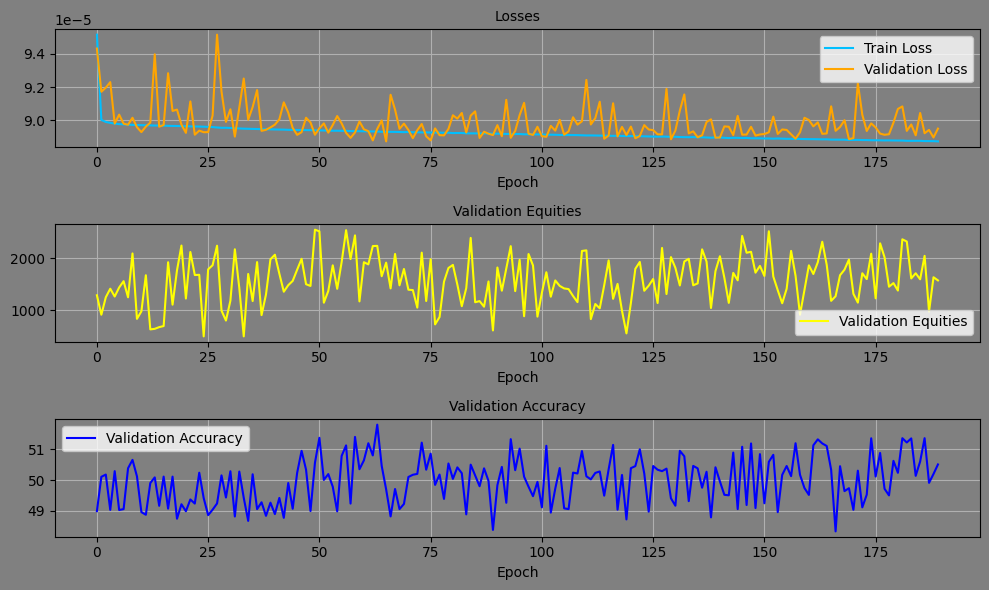

Epoch: 190, Val Equity: 1654.90, Val Accuracy: 49.68 train_losses: 0.00025889678358094616, val_losses: 8.916203660191968e-05, Duration: 0:01:50.181590


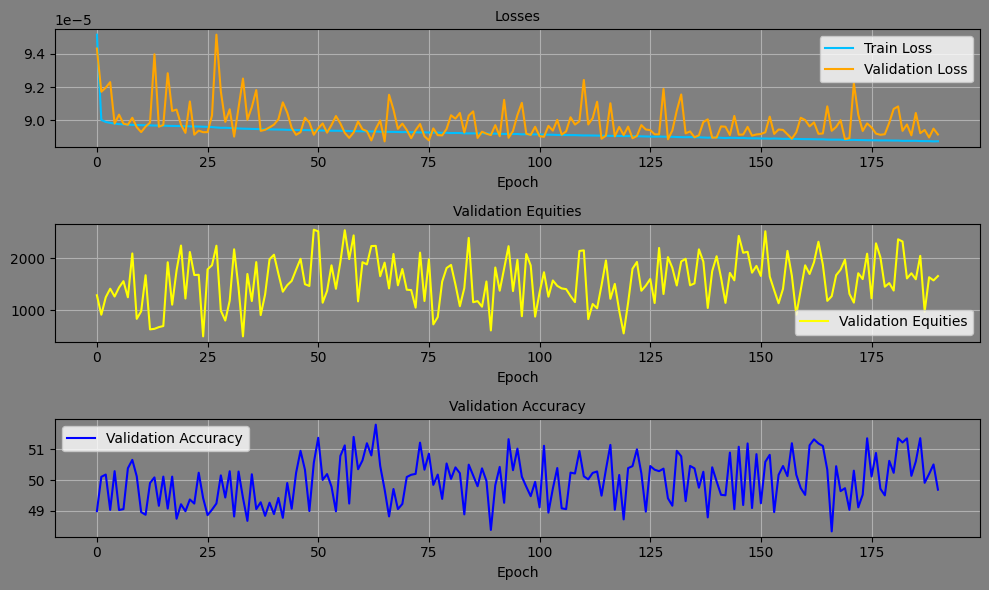

Epoch: 191, Val Equity: 1095.33, Val Accuracy: 50.18 train_losses: 0.00025864826144692324, val_losses: 9.152680286206305e-05, Duration: 0:01:55.218648


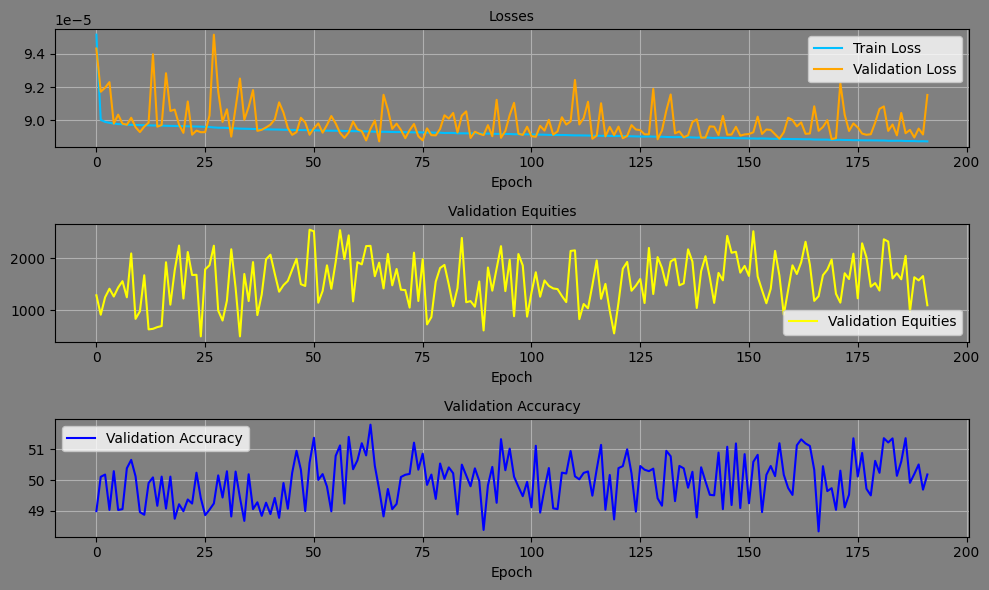

Epoch: 192, Val Equity: 1359.63, Val Accuracy: 49.42 train_losses: 0.0002588453945547808, val_losses: 8.91440940904431e-05, Duration: 0:02:01.708255


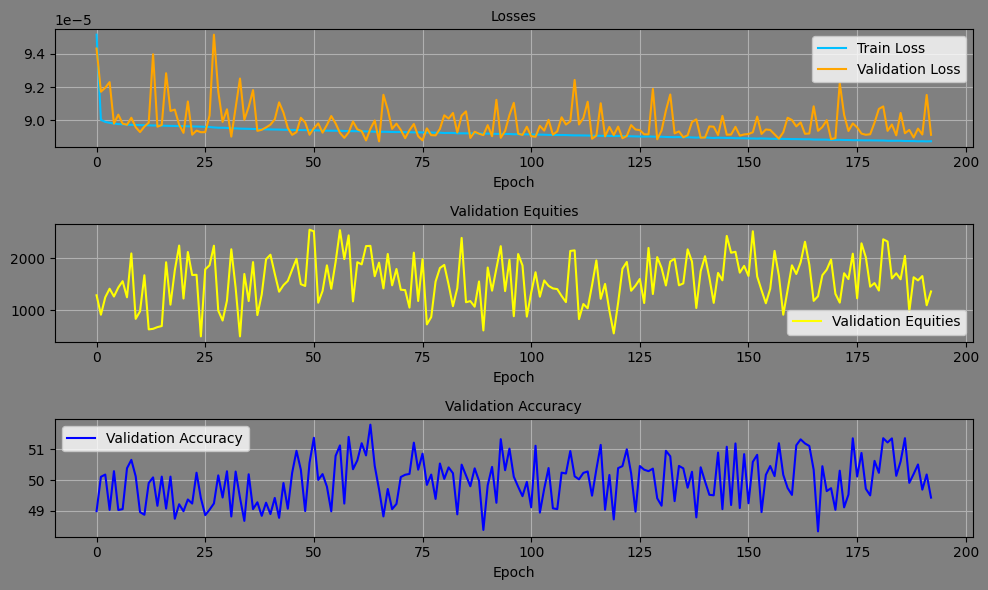

Epoch: 193, Val Equity: 2241.94, Val Accuracy: 50.72 train_losses: 0.0002584198019854643, val_losses: 9.11514216568321e-05, Duration: 0:01:51.622711


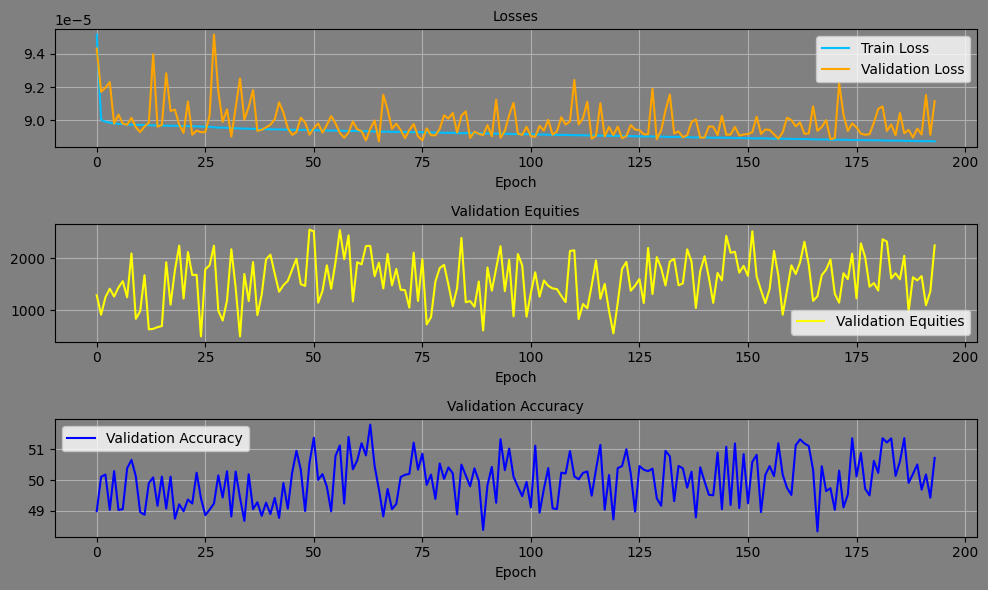

Epoch: 194, Val Equity: 1245.56, Val Accuracy: 50.22 train_losses: 0.00025861485125240624, val_losses: 9.008813503896818e-05, Duration: 0:01:51.170135


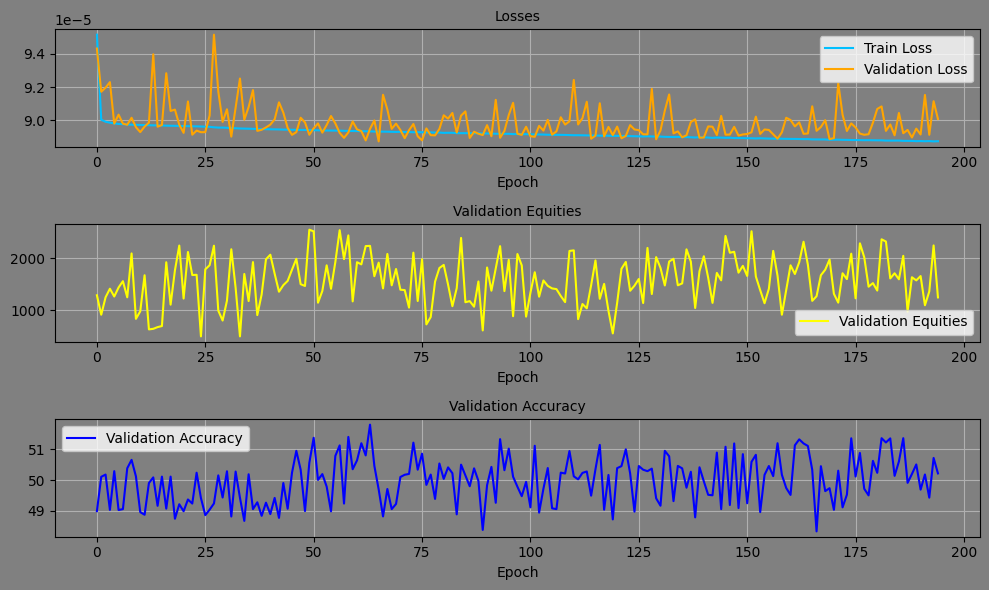

Epoch: 195, Val Equity: 1377.18, Val Accuracy: 49.04 train_losses: 0.0002582433207756485, val_losses: 8.945396257331595e-05, Duration: 0:01:49.459095


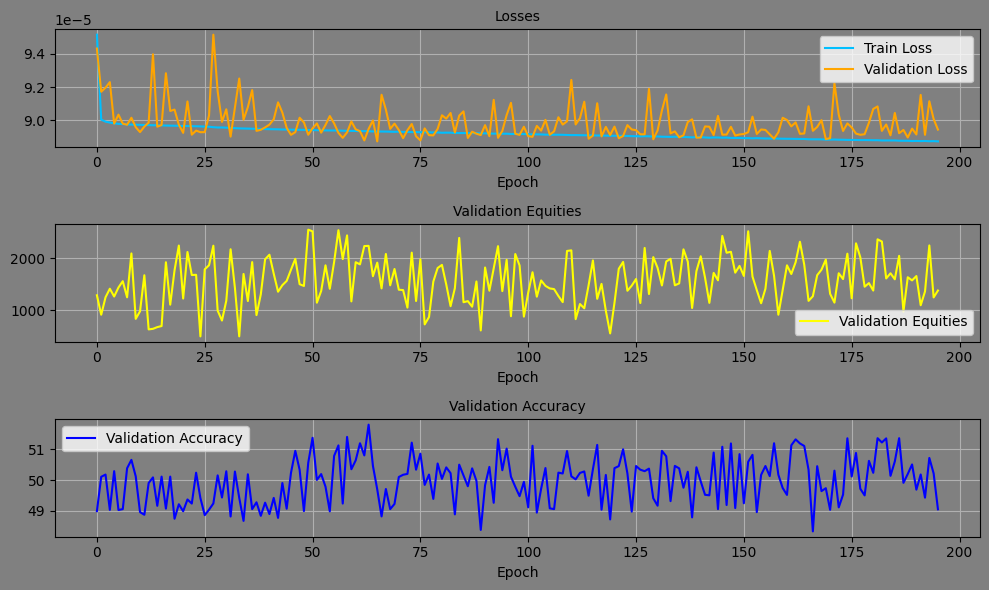

Epoch: 196, Val Equity: 1174.41, Val Accuracy: 48.83 train_losses: 0.0002583581087586625, val_losses: 8.995080861495808e-05, Duration: 0:01:51.243366


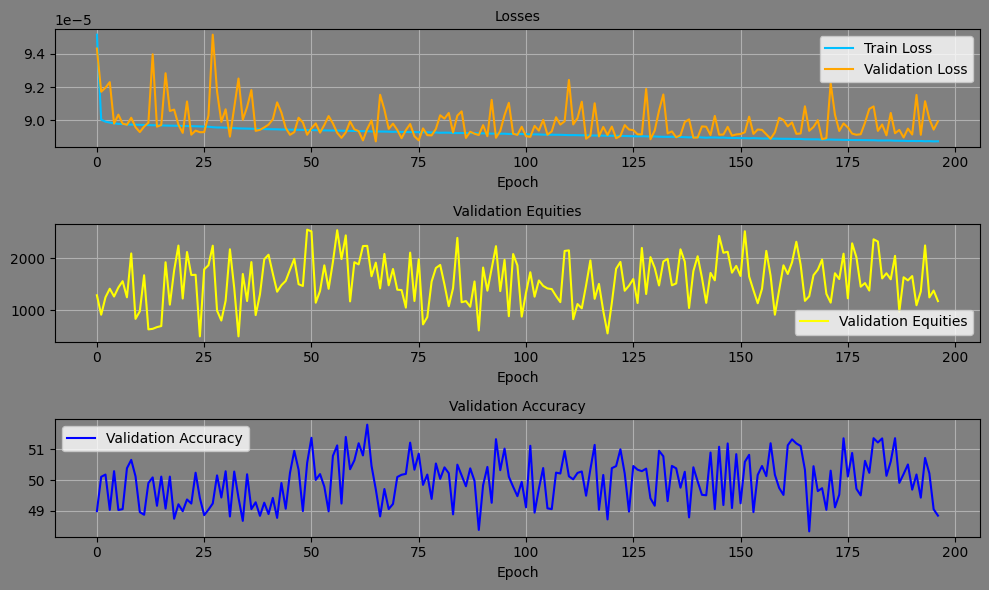

Epoch: 197, Val Equity: 1773.70, Val Accuracy: 51.05 train_losses: 0.00025813550402146085, val_losses: 8.914146019378677e-05, Duration: 0:01:53.416874


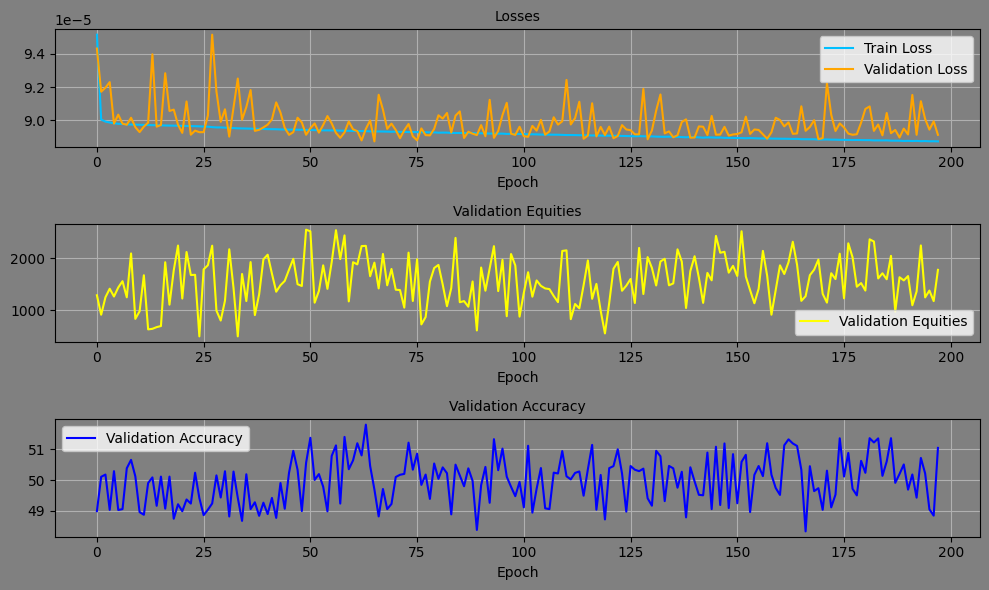

Epoch: 198, Val Equity: 1641.30, Val Accuracy: 49.18 train_losses: 0.00025795089500317726, val_losses: 8.902561239665374e-05, Duration: 0:01:54.656659


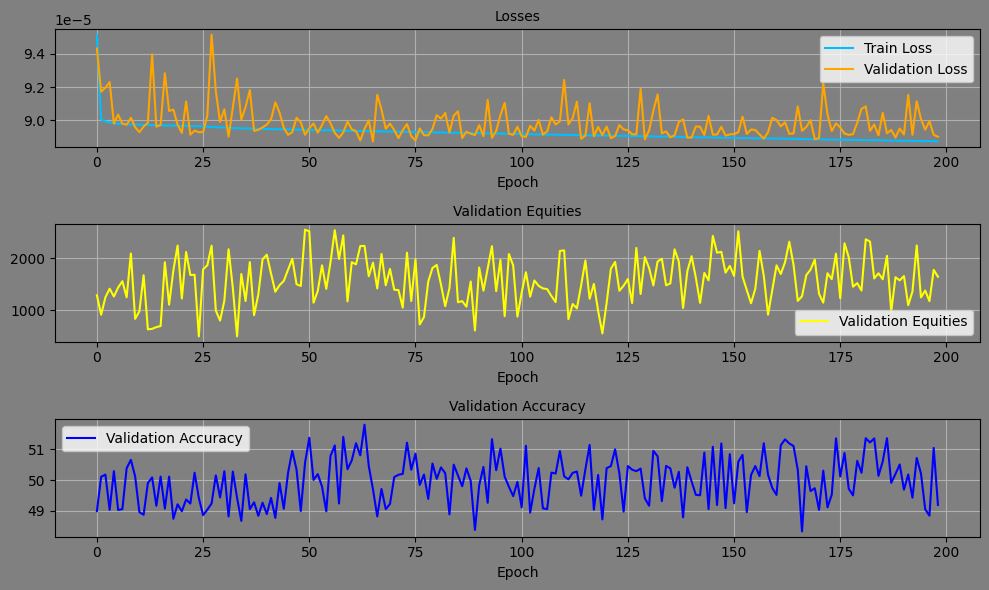

Epoch: 199, Val Equity: 2015.28, Val Accuracy: 49.93 train_losses: 0.00025799226799803573, val_losses: 8.958098624134436e-05, Duration: 0:01:51.412069


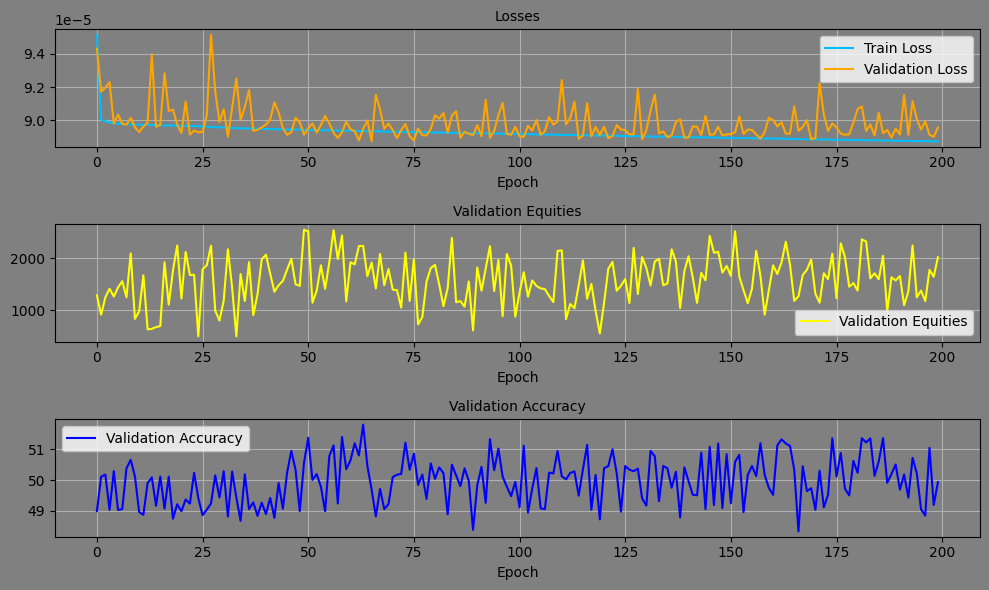

In [15]:
for epoch in range(epoch, num_epochs):

    # Track duration
    dt0_epoch = datetime.now()

    # Create mini batches
    mini_batches, seed = create_minibatches(X_train, Y_train, batch_size, seed, shuffle=True)

    train_losses_batch = []

    for X_train_batch, Y_train_batch in mini_batches:
        # Set train mode
        model.train()

        # Reset the gradients
        optimizer.zero_grad()

        # Forward propagation
        Y_hat_train = model(X_train_batch) # Shape: (batch_size, num_features)

        # Calculate loss (train)
        train_loss = criterion(Y_hat_train, Y_train_batch)

        # Backprop
        train_loss.backward()

        # Update optimizer
        optimizer.step()

        # Keep track of training losses
        train_losses_batch.append(train_loss.item())

    # Predict on validation data -- X_test is never touched here, only X_val.
    # This is the slice the loop is "allowed" to check every epoch to decide
    # when to stop / which checkpoint to keep.
    with torch.no_grad():

        # Set evaluation mode
        model.eval()

        # Forward propagation (chunks)
        chunks = 16  # set once per epoch, outside the retry loop -- previously
                     # this was reset to 16 on every retry, so the "increase
                     # chunks on OOM" logic never actually took effect
        while True:
            try:
                # split the validation set into chunks
                m = m_val // chunks

                for j in range(chunks + 1):
                    Y_pred_val[m*j:m*j+m] = model(X_val[m*j:m*j+m])  # Forward prop

                break

            except Exception as err:
                print(f"Chunks = {chunks} is too large: {err}")
                chunks += 2

        # Calculate validation loss
        val_loss = criterion(Y_pred_val, Y_val)

    # Convert 'Y_pred_val' to numpy
    Y_pred_val_cpu = Y_pred_val.detach().cpu().numpy()

    train_losses.append(np.mean(train_losses_batch))
    val_losses.append(val_loss.item())

    # ===================== Backtest (validation only) =====================
    equities = []    # Store equity (account value) over time
    pos_size = 1000  # Fixed position size ($1000 per trade)
    equity = 1000    # Starting capital
    correct_pred = 0 # Initialize correct prediction

    actions = Y_pred_val_cpu[:, 0] > 0 # Get model's buy/sell predictions

    for i in range(len(X_val)-1):
        curr_open = backtest_opens_val[i]   # the price we enter at.
        curr_close = backtest_closes_val[i] # the price we exit at.
        curr_action = actions[i]        # the model's signal (buy or sell).

        # Calculate percentage price change
        pct_change = (curr_close - curr_open) / curr_open

        # Profit or loss in dollars
        pnl = np.abs(pos_size * pct_change)

        # Update equity depending on action and price move
        if curr_action == 1:     # Long position (Buy side)
            if pct_change > 0:
                equity += pnl    # Price up -> profit
                correct_pred += 1
            elif pct_change < 0:
                equity -= pnl    # Price down -> loss

        elif curr_action == 0:   # Short position
            if pct_change > 0:
                equity -= pnl    # Price up -> loss
            elif pct_change < 0:
                equity += pnl    # Price down -> profit
                correct_pred += 1

        equities.append(equity) # Save current equity
    # ========================================================

    # Calculate percentage accuracy
    accuracy = correct_pred / len(X_val) * 100

    # Save final equity for each epoch
    val_equity_epochs.append(equity)
    val_accuracy_epochs.append(accuracy)

    print(f'Epoch: {epoch}, Val Equity: {equity:.2f}, Val Accuracy: {accuracy:.2f} train_losses: {train_losses[-1]}, val_losses: {val_losses[-1]}, Duration: {datetime.now() - dt0_epoch}')

    # Save training process
    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_losses': train_losses,
        'val_losses': val_losses,
        'val_equity_epochs': val_equity_epochs,
        'val_accuracy_epochs': val_accuracy_epochs,
        'best_val_equity': best_val_equity,
        'seed': seed,
    }, 'training_process')

    # Manual-inspection checkpoints, same threshold convention as before, but
    # now scored on validation equity, not test equity.
    if equity > 3000:
        torch.save(model.state_dict(), f"models/valeq_{equity:.0f}_ep_{epoch}.pt")

    # The single best checkpoint by validation equity across every epoch run
    # so far -- this is the one file the final held-out test cell loads.
    if equity > best_val_equity:
        best_val_equity = equity
        torch.save(model.state_dict(), "models/best_by_validation.pt")

    # Plot training process
    fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(10, 6))
    scaler_valloss = MinMaxScaler(feature_range=(np.min(val_losses)-0.0000000001, np.max(val_losses)))

    # Plot Train Loss and Validation Loss
    axs[0].set_title(f"Losses", fontsize=10)
    axs[0].plot(scaler_valloss.fit_transform(np.array(train_losses).reshape(-1,1)), label='Train Loss', color='deepskyblue')
    axs[0].plot(val_losses, label='Validation Loss', color='orange')
    axs[0].set_xlabel("Epoch")
    axs[0].legend()
    axs[0].grid()
    # Plot Equities
    axs[1].set_title(f"Validation Equities", fontsize=10)
    axs[1].plot(val_equity_epochs, label='Validation Equities', color='yellow')
    axs[1].set_xlabel("Epoch")
    axs[1].legend()
    axs[1].grid()
    # Plot Accuracy
    axs[2].set_title(f"Validation Accuracy", fontsize=10)
    axs[2].plot(val_accuracy_epochs, label='Validation Accuracy', color='blue')
    axs[2].set_xlabel("Epoch")
    axs[2].legend()
    axs[2].grid()
    # Set background color and paper color
    fig.patch.set_facecolor(mcolors.to_hex('grey'))  # Set paper color
    for ax in axs.flat:
        ax.set_facecolor(mcolors.to_hex('grey'))  # Set bg color
    # Display
    plt.tight_layout()
    plt.savefig(f'training_process.png')
    plt.show()
    plt.close()

**Final held-out test evaluation (run exactly once, after training is done)**

/var/folders/4f/6p47vdgn5_3dwdmxhs9cypqm0000gn/T/ipykernel_20916/1620699859.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  test_model.load_state_dict(torch.load("model

HELD-OUT TEST (checked exactly once): final equity=1247.57, accuracy=48.86%


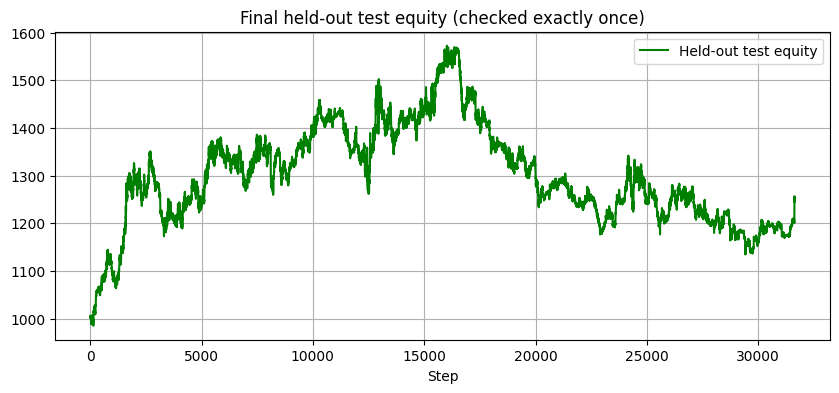

In [16]:
# ===================== FINAL, ONE-TIME TEST EVALUATION =====================
# The only cell in this notebook that touches X_test/Y_test. Runs exactly
# once, after training is completely finished, using
# models/best_by_validation.pt -- the single checkpoint that scored best on
# the VALIDATION set across every epoch. No decision anywhere above this
# cell was made by looking at test-set performance, so this is the first
# honest out-of-sample number in this project.

test_model = Model()
test_model.load_state_dict(torch.load("models/best_by_validation.pt", map_location=device))
test_model.to(device)
test_model.eval()

with torch.no_grad():
    chunks = 16
    m_chunk = m_test // chunks
    Y_pred_test = torch.zeros([m_test, num_features], dtype=torch.float32)
    while True:
        try:
            for j in range(chunks + 1):
                Y_pred_test[m_chunk*j:m_chunk*j+m_chunk] = test_model(
                    X_test[m_chunk*j:m_chunk*j+m_chunk].to(device)
                ).cpu()
            break
        except Exception as err:
            print(f"Chunks = {chunks} is too large: {err}")
            chunks += 2
            m_chunk = m_test // chunks

Y_pred_test_cpu = Y_pred_test.detach().numpy()

pos_size = 1000
equity = 1000
correct_pred = 0
test_equities = []

actions = Y_pred_test_cpu[:, 0] > 0

for i in range(len(X_test) - 1):
    curr_open = backtest_opens_test[i]
    curr_close = backtest_closes_test[i]
    curr_action = actions[i]

    pct_change = (curr_close - curr_open) / curr_open
    pnl = np.abs(pos_size * pct_change)

    if curr_action == 1:
        if pct_change > 0:
            equity += pnl
            correct_pred += 1
        elif pct_change < 0:
            equity -= pnl
    elif curr_action == 0:
        if pct_change > 0:
            equity -= pnl
        elif pct_change < 0:
            equity += pnl
            correct_pred += 1

    test_equities.append(equity)

test_accuracy = correct_pred / len(X_test) * 100
print(f"HELD-OUT TEST (checked exactly once): final equity={equity:.2f}, accuracy={test_accuracy:.2f}%")

plt.figure(figsize=(10, 4))
plt.plot(test_equities, label="Held-out test equity", color="green")
plt.title("Final held-out test equity (checked exactly once)")
plt.xlabel("Step")
plt.legend()
plt.grid()
plt.savefig("test_equity_final.png")
plt.show()